# Qwen: context, caching, concurrency and precision

**You are here → 01 — Qwen: caching and quantization.**

**Main workflow:** understand a local AI request → optimize Qwen → optimize Nemotron.
**Optional extensions:** model-specific NIM deployment; separate CPU portability branch.

| **Step** | **Notebook** | **Purpose** |
|---|---|---|
| 0. Understand the request | [00 — How a local AI request works](00_local_serving.ipynb) | Follow a question through schema context, model serving and generated SQL, then evaluate the results to establish a quality baseline. |
| **→ 1. Qwen optimization (current)** | [01 — Qwen: caching and quantization](01_qwen_optimization.ipynb) | Compare FP16/AWQ W4A16 and prefix caching, with cold and warm requests reported separately. |
| 2. Nemotron optimization | [02 — Nemotron optimization](02_nemotron_optimization.ipynb) | Test schema context, supported prefix caching, concurrent requests, scheduler capacity and output budgets. |
| 3. Qwen NIM (optional) | [03 — Qwen through NIM](03_qwen_nim.ipynb) | Deploy Qwen in a container, check the plan format, and compare schema context and concurrent requests. |
| 4. Nemotron NIM (optional) | [04 — Nemotron through NIM](04_nemotron_nim.ipynb) | Deploy the hybrid model through NIM and compare schema context and request concurrency. |
| 5. CPU portability (optional) | [05 — Qwen with ExecuTorch](05_edge_portability_executorch.ipynb) | Follow Qwen3-4B conversion and CPU export, then inspect a generated SQL answer and its timing. |
| 6. Compatibility study (optional) | [06 — Nemotron with ExecuTorch](06_nemotron_executorch.ipynb) | Check whether the installed exporter accepts Nemotron and identify what a working port still needs. |

We compare FP16 and AWQ W4A16 weights, each with prefix caching off and on. Caching reuses computation for shared instructions and schema; AWQ compresses weights while keeping activations at FP16. We then test schema context, concurrency, scheduling capacity, reasoning and output limits against the FP16 cache-off baseline.

The workload is structured clinical-trial questions on synthetic data with no personally identifiable information (PII). We compare response time with executed SQL and reference-result matches.

Configure your GPU environment below, then run the cells in order to collect new measurements. Each experiment saves its results separately. Completed outputs are visible when a live execution has been saved. For the previous Dell measurements, use the reference links at the end.

Follow [SETUP.md](../SETUP.md) and [the execution guide](../tutorial/RUN_ALL.md) first. The target is **Qwen3-4B**, `Qwen/Qwen3-4B`, on a **Linux NVIDIA GPU**. Model loading and server startup happen before request timing.


## 1. Imports and editable configuration

`MODE` controls execution: **live** collects new inference; **plan** previews commands; **replay** explicitly reads archived results. It overrides an older local JSON mode. CPU validation supplies `LOCAL_AI_LAB_MODE=plan` or `replay` before executing these cells.

Keep machine paths, exact checkpoint revisions and deployment settings in the per-notebook local JSON. Downloads are opt-in. Remove the obsolete `execute` flag; mode is the execution authority.


In [1]:
from pathlib import Path
import os
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/clinical_trial_mvp').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import JSON, Markdown, display
from clinical_trial_mvp.tutorial.workflow import Study, read_config
from clinical_trial_mvp.tutorial.teaching import server_example, request_example, response_example, interpret

MODE = "live"  # "plan" previews commands; "replay" displays archived results
MODE = os.environ.get('LOCAL_AI_LAB_MODE', MODE)  # Explicit CPU validation override.
CONFIG = read_config('vllm', 'qwen', root=ROOT, mode=MODE)
# Edit CONFIG here or the matching tutorial/config/*.local.json before continuing.
if 'study' in globals():
    study.close()
study = Study('vllm', 'qwen', root=ROOT, config=CONFIG, mode=MODE)
results = study.results
print('Effective mode:', study.mode)
print('Model:', 'Qwen/Qwen3-4B')
print('Hardware target: Linux / NVIDIA GPU; actual device checked next')
print('Session:', study.session_id)
print('Current-session measurements:', len(results))


Effective mode: live
Model: Qwen/Qwen3-4B
Hardware target: Linux / NVIDIA GPU; actual device checked next
Session: 20261110T233252-f6e2bc4728
Current-session measurements: 0


## 2. Preflight checks

Check the GPU, selected runtime, checkpoint paths/revisions and port 8000 before loading a model. NIM also checks Docker access, an already available image, GPU access from that image and your selected profile. Missing prerequisites stop with instructions; no package installation or image pull is automatic.


In [2]:
display(JSON(study.preflight()))


<IPython.core.display.JSON object>

## 3. Model preparation and compatibility smoke

Preparation validates local checkpoint identity and precision. It downloads weights only when `download_models=true`. NIM verifies the selected profile against discovery for this deployment.

Qwen's vLLM study requires a successful AWQ SQL smoke before all four variants. Nemotron core needs no AWQ checkpoint: its optional stretch remains separate. NIM smoke tests both serving and SQL execution; a failed required smoke blocks dependent experiments.


In [3]:
print(study.prepare())


Validated local checkpoint/configuration; ready to run.


In [4]:
smoke = study.smoke()
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(smoke)))


Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-3c8fe7be.log


| Result | Status | SQL executed | Reference match | TTFT (s) | Request / inference (s) | Model load (s) | Peak memory (GiB) | Artifacts (MiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/awq_w4a16_cache_off | completed | Yes | Yes | 2.684 | 4.599 | — | — | — |

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-smoke-4099eced.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261110T233423_820570Z&quot;,
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/awq_w4a16_cache_off&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: &quot;awq&quot;,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-00d6d35c.json&quot;
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: &quot;awq&quot;,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-awq-4bit-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--quantization&quot;,
      &quot;awq&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 582690,
    &quot;readiness_seconds&quot;: 70.02255526400404,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-3c8fe7be.log&quot;
  },
  &quot;sample&quot;: {
    &quot;request_started_at&quot;: &quot;2026-11-10T23:34:23.873837+00:00&quot;,
    &quot;success&quot;: true,
    &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
    &quot;error&quot;: null,
    &quot;finish_reason&quot;: &quot;stop&quot;,
    &quot;ttft_seconds&quot;: 2.6844790110044414,
    &quot;e2e_seconds&quot;: 4.599333243997535,
    &quot;prompt_tokens&quot;: 2347,
    &quot;output_tokens&quot;: 127,
    &quot;decode_tokens_per_second&quot;: 65.80135335056309
  },
  &quot;attempts&quot;: [
    {
      &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
      &quot;execution_success&quot;: true,
      &quot;query_result&quot;: {
        &quot;ok&quot;: true,
        &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
        &quot;columns&quot;: [
          &quot;treatment_arm&quot;,
          &quot;enrolled_or_randomized_subjects&quot;
        ],
        &quot;rows&quot;: [
          {
            &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
            &quot;enrolled_or_randomized_subjects&quot;: 40
          },
          {
            &quot;treatment_arm&quot;: &quot;Placebo&quot;,
            &quot;enrolled_or_randomized_subjects&quot;: 44
          },
          {
            &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
            &quot;enrolled_or_randomized_subjects&quot;: 48
          },
          {
            &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
            &quot;enrolled_or_randomized_subjects&quot;: 38
          }
        ],
        &quot;row_count&quot;: 4,
        &quot;error&quot;: null
      },
      &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
      &quot;error&quot;: null
    }
  ],
  &quot;scores&quot;: {
    &quot;sql_generated&quot;: true,
    &quot;sql_safety&quot;: false,
    &quot;schema_compliance&quot;: null,
    &quot;sql_execution_success&quot;: true,
    &quot;result_equivalence&quot;: true,
    &quot;first_pass_accuracy&quot;: true,
    &quot;repair_count&quot;: 0,
    &quot;repair_success&quot;: null,
    &quot;schema_linking_accuracy&quot;: null
  },
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-10T23:33:13.797009+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-10T23:34:28.564426+00:00&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/awq_w4a16_cache_off&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-smoke-4099eced.json&quot;
}</pre>
</details>

## 4. Individual experiments

For the first four precision/cache variants, hold the schema, four questions, seed 42, temperature 0, output cap 1,024, scheduling capacity 4 and context limit 8,192 fixed. Subsequent experiments each change one control from fp16_cache_off; capacity experiments keep concurrency at four clients. Compare capacity 1/2/4 using batch_capacity_1, batch_capacity_2 and concurrency_4. AWQ W4A16 changes weight storage, not KV-cache precision.

Cache-on targets use **reset → cold target → reset → different-question prime → identical target warm**, with an identical shared schema prefix. Cold and warm requests remain separate. Startup, readiness, warmup, reset, priming and SQL scoring are outside individual request timing.

Predict whether shared-prefix reuse helps TTFT more than complete-request latency. Each cell below starts its own server, makes new inference requests in Live mode, saves a new result and stops that server.

| Control | What it changes |
|---|---|
| Schema context | Compare the full schema with a smaller retrieved selection. |
| Prefix caching | Reuse processing of an identical shared schema prefix; report cold and warm requests separately. |
| Concurrency | Change how many client requests overlap: 1, 2 or 4. |
| Scheduling capacity | Allow 1, 2 or 4 sequences in the server scheduler, keeping four client requests concurrent; actual batch occupancy is not measured. |
| Reasoning | Compare reasoning disabled and enabled; reasoning tokens count within the output budget. |
| Output limit | Cap generated tokens at 256, 1,024 or 2,048; the context-window limit remains 8,192. |
| Precision | Compare FP16 with validated AWQ 4-bit weights and FP16 activations (W4A16). |


### fp16 cache off

Establish the Qwen FP16 baseline with prefix caching disabled, one client, scheduling capacity 4 and an output limit of 1,024 tokens.


In [5]:
result = study.run('fp16_cache_off')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'fp16_cache_off')))


Starting fp16_cache_off | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-95ff2940.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/fp16_cache_off | completed | 3/4 | 2/4 | 2.048 / 2.051 | 6.081 / 7.647 | 12.836 / 15.095 | 23.966 | 13.950 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_off-5d535f84.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261110T233756_234915Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/fp16_cache_off&quot;,
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/fp16_cache_off&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fe8a55b5.json&quot;
  },
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 12.836355238498072,
    &quot;latency_p95_seconds&quot;: 15.094652185004815,
    &quot;sql_executed&quot;: 3,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    }
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 126.84779444200103,
    &quot;requests_per_second&quot;: 0.15766927669479233,
    &quot;slo_requests_per_second&quot;: 0.15766927669479233,
    &quot;output_tokens_per_second&quot;: 23.965730057608432,
    &quot;ttft_p50_seconds&quot;: 2.04760990649811,
    &quot;ttft_p95_seconds&quot;: 2.0505106664961206,
    &quot;e2e_p50_seconds&quot;: 6.080721119004011,
    &quot;e2e_p95_seconds&quot;: 7.64672299795202,
    &quot;mean_prompt_tokens&quot;: 2344
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 14978908160.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1389,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.989463836012874,
            &quot;query_seconds&quot;: 2.4010303469985956,
            &quot;privacy_check_seconds&quot;: 0.0012887729972135276,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:38:01.337326+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1276636680122465,
              &quot;e2e_seconds&quot;: 5.988882956007728,
              &quot;prompt_tokens&quot;: 2420,
              &quot;output_tokens&quot;: 135,
              &quot;decode_tokens_per_second&quot;: 34.704063666263544
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.971523401007289,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:37:56.365419+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.522667562996503,
          &quot;e2e_seconds&quot;: 4.9688470819965005,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 86,
          &quot;decode_tokens_per_second&quot;: 34.74806298547874
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 13.385690822004108,
        &quot;inference_seconds&quot;: 10.960987237020163,
        &quot;query_seconds&quot;: 2.4010303469985956,
        &quot;privacy_check_seconds&quot;: 0.001487108995206654,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.67579920400749,
            &quot;query_seconds&quot;: 1.3434588110103505,
            &quot;privacy_check_seconds&quot;: 0.0015532079996773973,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:38:14.203777+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1547518330044113,
              &quot;e2e_seconds&quot;: 5.675312232997385,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 123,
              &quot;decode_tokens_per_second&quot;: 34.65357390267853
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;&quot;,
          &quot;measure&quot;: &quot;count of distinct subject_id&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.452446985989809,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:38:09.751061+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.2106236410036217,
          &quot;e2e_seconds&quot;: 4.451744927006075,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 79,
          &quot;decode_tokens_per_second&quot;: 34.80400658686823
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 11.495023156996467,
        &quot;inference_seconds&quot;: 10.128246189997299,
        &quot;query_seconds&quot;: 1.3434588110103505,
        &quot;privacy_check_seconds&quot;: 0.001560339005663991,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.53856759100745,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013550529984058812,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:38:25.756264+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.185901321005076,
              &quot;e2e_seconds&quot;: 5.537991944001988,
              &quot;prompt_tokens&quot;: 2439,
              &quot;output_tokens&quot;: 117,
              &quot;decode_tokens_per_second&quot;: 34.60526967981882
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.345707000989933,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.001059321002685465,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:38:31.296373+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.22172281400708,
              &quot;e2e_seconds&quot;: 5.345086401008302,
              &quot;prompt_tokens&quot;: 2478,
              &quot;output_tokens&quot;: 109,
              &quot;decode_tokens_per_second&quot;: 34.57810690035356
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (visit_planned_date)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.509164358998532,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:38:21.246716+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.14890865200141,
          &quot;e2e_seconds&quot;: 4.5082889039913425,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 83,
          &quot;decode_tokens_per_second&quot;: 34.75488952272111
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 15.39623360200494,
        &quot;inference_seconds&quot;: 15.393438950995915,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.00242244299442973,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.209828888007905,
            &quot;query_seconds&quot;: 1.3756908200011821,
            &quot;privacy_check_seconds&quot;: 0.0003815500094788149,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:38:41.323591+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.129078580008354,
              &quot;e2e_seconds&quot;: 6.209342479996849,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 143,
              &quot;decode_tokens_per_second&quot;: 34.80167054890749
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.680093504997785,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:38:36.643272+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.174295364005957,
          &quot;e2e_seconds&quot;: 4.678399939002702,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 34.742957969362394
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.287019654992037,
        &quot;inference_seconds&quot;: 10.88992239300569,
        &quot;query_seconds&quot;: 1.3756908200011821,
        &quot;privacy_check_seconds&quot;: 0.0004110620211577043,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:38:54.459368+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.050971254997421,
        &quot;e2e_seconds&quot;: 5.560321505996399,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.334176166856516
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:00.019864+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.04774787799397,
        &quot;e2e_seconds&quot;: 6.481813156991848,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.18216133147612
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:06.502222+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0421258230053354,
        &quot;e2e_seconds&quot;: 5.670394842003589,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.27853070700368
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:12.173181+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0464886080008,
        &quot;e2e_seconds&quot;: 7.641133641998749,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 35.03350057223163
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:19.814909+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.044284333998803,
        &quot;e2e_seconds&quot;: 5.564514301993768,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.22497141589511
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:25.380006+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0445067690016003,
        &quot;e2e_seconds&quot;: 6.480551408996689,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.16646306791284
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:31.861118+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0483158450078918,
        &quot;e2e_seconds&quot;: 5.676186709009926,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.28240248849393
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:37.537732+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.039505321998149,
        &quot;e2e_seconds&quot;: 7.641479818004882,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.98766374957885
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:45.179785+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0493052450037794,
        &quot;e2e_seconds&quot;: 5.567458413002896,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.245765058751736
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:50.747461+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0430883540102514,
        &quot;e2e_seconds&quot;: 6.48248279200925,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.13992779391665
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:39:57.230362+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0474719350022497,
        &quot;e2e_seconds&quot;: 5.676067282009171,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.27535802678629
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:40:02.907014+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0481502289912896,
        &quot;e2e_seconds&quot;: 7.647125055998913,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 35.0064085043855
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:40:10.554717+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.047022571990965,
        &quot;e2e_seconds&quot;: 5.565474397997605,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.24277327984254
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:40:16.120763+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.040400967001915,
        &quot;e2e_seconds&quot;: 6.481478750007227,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.12660836452037
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:40:22.602669+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0491750509972917,
        &quot;e2e_seconds&quot;: 5.676504338989616,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.28767030435392
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:40:28.279326+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0490081480093068,
        &quot;e2e_seconds&quot;: 7.645693576007034,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 35.02072834386925
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:40:35.925567+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.050486424996052,
        &quot;e2e_seconds&quot;: 5.570042014005594,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.23172084203266
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:40:41.496382+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.044798995004385,
        &quot;e2e_seconds&quot;: 6.481276243997854,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.16303392187859
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:40:47.977866+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0489311870042,
        &quot;e2e_seconds&quot;: 5.680890829011332,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.242682357908386
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:40:53.659146+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.048406720001367,
        &quot;e2e_seconds&quot;: 7.646701837002183,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 35.010658763735094
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 583313,
    &quot;readiness_seconds&quot;: 74.02149258401187,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-95ff2940.log&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;finding&quot;: &quot;Inspect execution match, semantic review coverage, and latency together.&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;cache_study&quot;: {
    &quot;format&quot;: &quot;mvp4-cache-phases-v2&quot;,
    &quot;inputs&quot;: {
      &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
      &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
      &quot;case_ids&quot;: [
        &quot;eval_001&quot;,
        &quot;eval_002&quot;,
        &quot;eval_005&quot;,
        &quot;eval_007&quot;
      ],
      &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
      &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
      &quot;cache_sha256&quot;: null
    },
    &quot;shared_prefix_sha256&quot;: &quot;e9e8260b9d5648efa661582a24b578440b84cbeb5e7a44517810c2d819885d0c&quot;,
    &quot;schema_sha256&quot;: &quot;094ca9df32ae69dffd4dcaedda7cc2cc2091b54050f335921f511ff7c690ab57&quot;,
    &quot;phases&quot;: {
      &quot;cache_off&quot;: {
        &quot;requests&quot;: 20,
        &quot;successful&quot;: 20,
        &quot;failed&quot;: 0,
        &quot;slo_successful&quot;: 20,
        &quot;measurement_seconds&quot;: 125.96347694199358,
        &quot;requests_per_second&quot;: 0.1587761824739884,
        &quot;slo_requests_per_second&quot;: 0.1587761824739884,
        &quot;output_tokens_per_second&quot;: 24.133979736046236,
        &quot;ttft_p50_seconds&quot;: 2.0100539069972,
        &quot;ttft_p95_seconds&quot;: 2.0160879442511943,
        &quot;e2e_p50_seconds&quot;: 6.024564290004491,
        &quot;e2e_p95_seconds&quot;: 7.610150160743797,
        &quot;sql_executed&quot;: 15,
        &quot;result_equivalent&quot;: 10,
        &quot;reference_scored&quot;: 20,
        &quot;tpot_p50_seconds&quot;: 0.028365589726857456,
        &quot;peak_gpu_bytes&quot;: 14978908160.0,
        &quot;semantic&quot;: {
          &quot;correct&quot;: 0,
          &quot;reviewed&quot;: 0,
          &quot;total&quot;: 20
        }
      }
    },
    &quot;records&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.497253301000455,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:35:48.833033+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.001942865012097,
        &quot;e2e_seconds&quot;: 5.497120761006954,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.47745027287231,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 6.408739507998689,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 50,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:35:54.408432+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.996602939994773,
        &quot;e2e_seconds&quot;: 6.408633896004176,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.35786615175951,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.62040834200161,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:00.878980+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0003420789871598,
        &quot;e2e_seconds&quot;: 5.6202576009964105,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.35994119800702,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 7.587316737000947,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 57,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:06.574447+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0047568100126227,
        &quot;e2e_seconds&quot;: 7.58709921000991,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 35.11070908156677,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.512832234002417,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 42,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:14.247728+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0048979459970724,
        &quot;e2e_seconds&quot;: 5.5127240769943455,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.34952855965722,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 6.433848767992458,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 50,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:19.819437+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0056117339991033,
        &quot;e2e_seconds&quot;: 6.433718486005091,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.22950297648765,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.628446813992923,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:26.339243+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0063174859969877,
        &quot;e2e_seconds&quot;: 5.6283174690033775,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.339591551780025,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 7.610338030994171,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 58,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:32.043121+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0133560779941035,
        &quot;e2e_seconds&quot;: 7.610137672993005,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 35.02012659831841,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.531224339996697,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:39.738949+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.013867678993847,
        &quot;e2e_seconds&quot;: 5.531095906000701,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.25503379276683,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 6.442846745005227,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 50,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:45.326532+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0141368609911297,
        &quot;e2e_seconds&quot;: 6.44272696400003,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.22565791176056,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.638322951999726,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:51.824811+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.007295207993593,
        &quot;e2e_seconds&quot;: 5.638198975997511,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.25293099970197,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 7.604177967004944,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 59,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:36:57.531992+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.009306641994044,
        &quot;e2e_seconds&quot;: 7.604053653994924,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 35.03286200065433,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.527852175000589,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:37:05.227361+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0155390889995033,
        &quot;e2e_seconds&quot;: 5.527724152998417,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.30565666116003,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 6.444054585997947,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 49,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:37:10.827673+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.00908745599736,
        &quot;e2e_seconds&quot;: 6.443923291997635,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.176048397023536,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.640616016986314,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:37:17.329252+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0127445309917675,
        &quot;e2e_seconds&quot;: 5.640494684004807,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.28357648712087,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 7.608141075994354,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 57,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:37:23.043875+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.015954121001414,
        &quot;e2e_seconds&quot;: 7.607950367004378,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 35.05009506043508,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.533722688007401,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:37:30.710767+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.018630585997016,
        &quot;e2e_seconds&quot;: 5.533588796999538,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.27780205518666,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 6.446257308998611,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 51,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:37:36.327966+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.013673330991878,
        &quot;e2e_seconds&quot;: 6.446141331005492,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.19483953398442,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.636536825011717,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:37:42.839024+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.010801172000356,
        &quot;e2e_seconds&quot;: 5.636396645990317,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.304545396272864,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 7.610540527006378,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 14978908160.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 58,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:37:48.532721+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.015323879997595,
        &quot;e2e_seconds&quot;: 7.610387428008835,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 35.030880045976964,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ],
    &quot;priming_records&quot;: [],
    &quot;startup_in_request_timing&quot;: false,
    &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;
  },
  &quot;awq_smoke_run_id&quot;: &quot;20261110T233423_820570Z&quot;,
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-10T23:34:28.568642+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-10T23:41:01.412790+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_off-5d535f84.json&quot;
}</pre>
</details>

**Prediction:** Establish executable SQL and separate application quality from request speed.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 6.081/7.647 s; aggregate output: 23.966 tok/s.

**Explanation:** Transport timing and application correctness measure different stages.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use this baseline to judge useful completed tasks, not latency alone.

### Inspect the serving call and answer

The experiment above calls the model through the OpenAI-compatible `/v1/chat/completions` API. Inspect the launch command, request, generated plan/SQL and execution checks below. The request is constructed from the experiment prompt, schema profile and generation settings. In Plan, these details preview the configured call. The response shows the generated answer and its reference-result check.

[Request transport](../src/clinical_trial_mvp/serving/client.py) · [plan and SQL execution](../src/clinical_trial_mvp/serving/agent.py)


In [6]:
display(JSON(server_example(study, 'fp16_cache_off')))
display(JSON(request_example(study, 'fp16_cache_off')))
display(JSON(response_example(study, 'fp16_cache_off')))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

### fp16 cache on

Change only prefix caching from fp16_cache_off; compare cold and warm requests using an identical shared schema prefix.


In [7]:
result = study.run('fp16_cache_on')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'fp16_cache_on')))


Starting fp16_cache_on | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-de489b48.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/fp16_cache_on | completed | 3/4 | 2/4 | 0.077 / 0.102 | 4.068 / 5.706 | 8.981 / 10.371 | 34.561 | 14.544 |
| cold | completed | 15/20 | 10/20 | 2.024 / 2.028 | 6.064 / 7.643 | — | 24.015 | 14.542 |
| warm | completed | 15/20 | 10/20 | 0.080 / 0.099 | 4.053 / 5.701 | — | 34.607 | 14.542 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_on-9bda846e.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261110T234732_742362Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/fp16_cache_on&quot;,
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/fp16_cache_on&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: true,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-f97b87eb.json&quot;
  },
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 8.980513726499339,
    &quot;latency_p95_seconds&quot;: 10.370648983502178,
    &quot;sql_executed&quot;: 3,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    }
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 87.23738048800442,
    &quot;requests_per_second&quot;: 0.22925952026666024,
    &quot;slo_requests_per_second&quot;: 0.22925952026666024,
    &quot;output_tokens_per_second&quot;: 34.56087268019903,
    &quot;ttft_p50_seconds&quot;: 0.07708910400106106,
    &quot;ttft_p95_seconds&quot;: 0.1020745074521983,
    &quot;e2e_p50_seconds&quot;: 4.0681913740045275,
    &quot;e2e_p95_seconds&quot;: 5.706165327910275,
    &quot;mean_prompt_tokens&quot;: 2344
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15616442368.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 940,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.146032722987002,
            &quot;query_seconds&quot;: 1.3597715600044467,
            &quot;privacy_check_seconds&quot;: 0.00036483998701442033,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:47:37.853796+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2717366129945731,
              &quot;e2e_seconds&quot;: 4.145660861002398,
              &quot;prompt_tokens&quot;: 2420,
              &quot;output_tokens&quot;: 135,
              &quot;decode_tokens_per_second&quot;: 34.59024787821028
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.981002633998287,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:47:32.872553+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.524956599008874,
          &quot;e2e_seconds&quot;: 4.980596879002405,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 86,
          &quot;decode_tokens_per_second&quot;: 34.61419031627218
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 10.505955243002973,
        &quot;inference_seconds&quot;: 9.127035356985289,
        &quot;query_seconds&quot;: 1.3597715600044467,
        &quot;privacy_check_seconds&quot;: 0.00037657999200746417,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.800406871989253,
            &quot;query_seconds&quot;: 1.3525372989970492,
            &quot;privacy_check_seconds&quot;: 0.0015894450043560937,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:47:45.727886+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2621652359957807,
              &quot;e2e_seconds&quot;: 3.7999554380076006,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 123,
              &quot;decode_tokens_per_second&quot;: 34.48480351678932
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;&quot;,
          &quot;measure&quot;: &quot;count of distinct subject_id&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.3490069300023606,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:47:43.378612+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.09323188800772186,
          &quot;e2e_seconds&quot;: 2.348622786012129,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 79,
          &quot;decode_tokens_per_second&quot;: 34.58380543657208
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 7.526314329996239,
        &quot;inference_seconds&quot;: 6.149413801991614,
        &quot;query_seconds&quot;: 1.3525372989970492,
        &quot;privacy_check_seconds&quot;: 0.001596078000147827,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 3.6439414369961014,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0004150989989284426,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:47:53.375294+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.28839429399522487,
              &quot;e2e_seconds&quot;: 3.643458909005858,
              &quot;prompt_tokens&quot;: 2439,
              &quot;output_tokens&quot;: 117,
              &quot;decode_tokens_per_second&quot;: 34.57459492166364
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 3.4897408749966417,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.00027064100140705705,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:47:57.019418+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.3503206199966371,
              &quot;e2e_seconds&quot;: 3.4895709809934488,
              &quot;prompt_tokens&quot;: 2478,
              &quot;output_tokens&quot;: 109,
              &quot;decode_tokens_per_second&quot;: 34.40311780857981
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (visit_planned_date)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.4693292699957965,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:47:50.905563+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.09914652600127738,
          &quot;e2e_seconds&quot;: 2.468811575003201,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 83,
          &quot;decode_tokens_per_second&quot;: 34.604046691973394
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 9.603913512997678,
        &quot;inference_seconds&quot;: 9.60301158198854,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0006936529971426353,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.351003435003804,
            &quot;query_seconds&quot;: 1.339604679000331,
            &quot;privacy_check_seconds&quot;: 0.0015948320069583133,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:48:03.152774+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.24192586199205834,
              &quot;e2e_seconds&quot;: 4.350390933992458,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 143,
              &quot;decode_tokens_per_second&quot;: 34.562786225869175
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.6428571669966914,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:48:00.509491+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.1197830159944715,
          &quot;e2e_seconds&quot;: 2.6422608510038117,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 34.48989671684384
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.357113940001,
        &quot;inference_seconds&quot;: 6.993860602000495,
        &quot;query_seconds&quot;: 1.339604679000331,
        &quot;privacy_check_seconds&quot;: 0.0016030490078264847,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:12.452089+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07631221099290997,
        &quot;e2e_seconds&quot;: 3.6111566509935074,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.07933718293387
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:16.063799+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.10388683099881746,
        &quot;e2e_seconds&quot;: 4.409960470002261,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.06674819312797
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:20.474087+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.10197912200237624,
        &quot;e2e_seconds&quot;: 3.7485672460024944,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.10130446527935
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:24.223216+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.0752639599959366,
        &quot;e2e_seconds&quot;: 5.7042548559984425,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.81974009572332
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:29.928097+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07912711901008151,
        &quot;e2e_seconds&quot;: 3.6094483670021873,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.12428226482954
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:33.537959+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07601951999822631,
        &quot;e2e_seconds&quot;: 4.3925352259975625,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 34.98191835376198
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:37.931088+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07517707398801576,
        &quot;e2e_seconds&quot;: 3.725723064999329,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.06324815936371
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:41.657366+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07719329099927563,
        &quot;e2e_seconds&quot;: 5.706110691011418,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.820194732219235
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:47.364068+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07698491700284649,
        &quot;e2e_seconds&quot;: 3.6154491790075554,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.04345128803084
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:50.980077+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08602514400263317,
        &quot;e2e_seconds&quot;: 4.394152919005137,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.050028199294125
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:55.374814+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07487418199889362,
        &quot;e2e_seconds&quot;: 3.7233497260021977,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.08314594855458
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:48:59.098755+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07961103899287991,
        &quot;e2e_seconds&quot;: 5.706082367003546,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.8353325865608
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:49:04.805381+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.0864397200057283,
        &quot;e2e_seconds&quot;: 3.6249377460044343,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.04311690692613
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:49:08.430886+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07893376100400928,
        &quot;e2e_seconds&quot;: 4.387815502006561,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.043895162661556
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:49:12.819112+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07605413800047245,
        &quot;e2e_seconds&quot;: 3.7232832589943428,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.09513544493744
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:49:16.542827+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07691203900321852,
        &quot;e2e_seconds&quot;: 5.701043034001486,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.84982838669823
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:49:22.244265+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07655378599883988,
        &quot;e2e_seconds&quot;: 3.6132028049905784,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.061437913155174
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:49:25.858040+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.074027038004715,
        &quot;e2e_seconds&quot;: 4.39022329900763,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 34.984507392375505
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:49:30.248852+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08194472899776883,
        &quot;e2e_seconds&quot;: 3.732253832000424,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.06552360037409
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:49:33.981698+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08143200298945885,
        &quot;e2e_seconds&quot;: 5.707203428988578,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.83966644897789
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: true,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 591408,
    &quot;readiness_seconds&quot;: 42.0163232509949,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-de489b48.log&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;finding&quot;: &quot;Inspect execution match, semantic review coverage, and latency together.&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;cache_study&quot;: {
    &quot;format&quot;: &quot;mvp4-cache-phases-v2&quot;,
    &quot;inputs&quot;: {
      &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
      &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
      &quot;case_ids&quot;: [
        &quot;eval_001&quot;,
        &quot;eval_002&quot;,
        &quot;eval_005&quot;,
        &quot;eval_007&quot;
      ],
      &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
      &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
      &quot;cache_sha256&quot;: null
    },
    &quot;shared_prefix_sha256&quot;: &quot;e9e8260b9d5648efa661582a24b578440b84cbeb5e7a44517810c2d819885d0c&quot;,
    &quot;schema_sha256&quot;: &quot;094ca9df32ae69dffd4dcaedda7cc2cc2091b54050f335921f511ff7c690ab57&quot;,
    &quot;phases&quot;: {
      &quot;cold&quot;: {
        &quot;requests&quot;: 20,
        &quot;successful&quot;: 20,
        &quot;failed&quot;: 0,
        &quot;slo_successful&quot;: 20,
        &quot;measurement_seconds&quot;: 126.58577598295233,
        &quot;requests_per_second&quot;: 0.15799563453869775,
        &quot;slo_requests_per_second&quot;: 0.15799563453869775,
        &quot;output_tokens_per_second&quot;: 24.01533644988206,
        &quot;ttft_p50_seconds&quot;: 2.024150269498932,
        &quot;ttft_p95_seconds&quot;: 2.027693245401315,
        &quot;e2e_p50_seconds&quot;: 6.063779979500396,
        &quot;e2e_p95_seconds&quot;: 7.6432747727958485,
        &quot;sql_executed&quot;: 15,
        &quot;result_equivalent&quot;: 10,
        &quot;reference_scored&quot;: 20,
        &quot;tpot_p50_seconds&quot;: 0.028475643374298587,
        &quot;peak_gpu_bytes&quot;: 15614345216.0,
        &quot;semantic&quot;: {
          &quot;correct&quot;: 0,
          &quot;reviewed&quot;: 0,
          &quot;total&quot;: 20
        }
      },
      &quot;warm&quot;: {
        &quot;requests&quot;: 20,
        &quot;successful&quot;: 20,
        &quot;failed&quot;: 0,
        &quot;slo_successful&quot;: 20,
        &quot;measurement_seconds&quot;: 87.12060816500161,
        &quot;requests_per_second&quot;: 0.22956680883265995,
        &quot;slo_requests_per_second&quot;: 0.22956680883265995,
        &quot;output_tokens_per_second&quot;: 34.60719643152349,
        &quot;ttft_p50_seconds&quot;: 0.08015862599859247,
        &quot;ttft_p95_seconds&quot;: 0.09871200769775897,
        &quot;e2e_p50_seconds&quot;: 4.05256975600787,
        &quot;e2e_p95_seconds&quot;: 5.700913567300449,
        &quot;sql_executed&quot;: 15,
        &quot;result_equivalent&quot;: 10,
        &quot;reference_scored&quot;: 20,
        &quot;tpot_p50_seconds&quot;: 0.028494234069584734,
        &quot;peak_gpu_bytes&quot;: 15614345216.0,
        &quot;semantic&quot;: {
          &quot;correct&quot;: 0,
          &quot;reviewed&quot;: 0,
          &quot;total&quot;: 20
        }
      }
    },
    &quot;records&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.5435803559958,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15612248064.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:41:49.251110+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.026901388002443,
        &quot;e2e_seconds&quot;: 5.543443638001918,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.261911043445735,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.617542758001946,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15612248064.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 29,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:01.315758+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.0985848319978686,
        &quot;e2e_seconds&quot;: 3.6174122739903396,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.239011302522776,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 6.455419876001542,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15612248064.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 49,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:05.017455+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0163610769959632,
        &quot;e2e_seconds&quot;: 6.4552939840068575,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.1435814120128,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.377303902001586,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 34,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:17.211403+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08073193700693082,
        &quot;e2e_seconds&quot;: 4.377171070009354,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.14538326404236,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.648619362997124,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:21.652288+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.015484759991523,
        &quot;e2e_seconds&quot;: 5.648502279989771,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.23242023893728,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.7133521549985744,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 29,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:34.986634+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07865504099754617,
        &quot;e2e_seconds&quot;: 3.7132297450007172,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.21732538858509,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 7.62554127900512,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 57,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:38.781290+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0238769660063554,
        &quot;e2e_seconds&quot;: 7.625324808002915,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.990953326477545,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.6832333210040815,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:52.073088+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08005594700807706,
        &quot;e2e_seconds&quot;: 5.683119931010879,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.98086057192918,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.546966376990895,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:57.813528+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.025884788003168,
        &quot;e2e_seconds&quot;: 5.546839357994031,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.217722221369584,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.6223410249949666,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 29,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:09.909518+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.09767628100235015,
        &quot;e2e_seconds&quot;: 3.622212695001508,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.18193187265212,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 6.464235413004644,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 50,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:13.615215+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0199395029922016,
        &quot;e2e_seconds&quot;: 6.464118476986187,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.102096678118876,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.3807593480014475,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 34,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:25.824923+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07912855899485294,
        &quot;e2e_seconds&quot;: 4.380632139000227,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.104004260717446,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.657078624004498,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:30.268405+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.019687455991516,
        &quot;e2e_seconds&quot;: 5.656950432996382,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.19129653512231,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.71645741899556,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 29,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:43.613397+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07900529200560413,
        &quot;e2e_seconds&quot;: 3.7163216409971938,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.19078015732306,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 7.628300493990537,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 58,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:47.375254+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0214899020065786,
        &quot;e2e_seconds&quot;: 7.628201020008419,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.95810571917818,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.692070888995659,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:00.631613+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08080479099589866,
        &quot;e2e_seconds&quot;: 5.691924942002515,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.93063679358893,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.549939167001867,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:06.410659+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0212091879948275,
        &quot;e2e_seconds&quot;: 5.549745706986869,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.14204807930449,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.62497999399784,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 29,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:18.521513+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.09826282398717012,
        &quot;e2e_seconds&quot;: 3.6248629079927923,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.16134436745006,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 6.4676998399954755,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 50,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:22.218429+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.019601837004302,
        &quot;e2e_seconds&quot;: 6.467579707998084,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.072116931450914,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.383445949002635,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:34.416793+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07956600899342448,
        &quot;e2e_seconds&quot;: 4.383321118002641,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.08563944168335,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.659405979997246,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:38.887216+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0202620519994525,
        &quot;e2e_seconds&quot;: 5.659288837006898,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.174239587175265,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.718067369001801,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 29,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:52.240321+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08008772900211625,
        &quot;e2e_seconds&quot;: 3.717944768999587,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.18554978732452,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 7.636783216992626,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 59,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:56.023006+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.024423572991509,
        &quot;e2e_seconds&quot;: 7.636589946996537,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.92412500596056,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.701014960999601,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:09.277518+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08461031199840363,
        &quot;e2e_seconds&quot;: 5.700876873001107,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.89862845203113,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.551264556008391,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:15.065809+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0246598009980517,
        &quot;e2e_seconds&quot;: 5.551146142010111,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.1624784584912,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.6263376510032685,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 29,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:27.217198+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.09714301899657585,
        &quot;e2e_seconds&quot;: 3.6262083819892723,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.136781908410526,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 6.47701422899263,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 49,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:30.952755+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0248018830025103,
        &quot;e2e_seconds&quot;: 6.476853027998004,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.040028723694704,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.385304006005754,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 34,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:43.188687+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08013685399782844,
        &quot;e2e_seconds&quot;: 4.385176377996686,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.07517158860818,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.663030174997402,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:47.663935+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.019037242003833,
        &quot;e2e_seconds&quot;: 5.662296121008694,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.13338037481503,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.722027461990365,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 30,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:01.022991+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07968292498844676,
        &quot;e2e_seconds&quot;: 3.7219199659884907,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.14323712573502,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 7.643014123998,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 58,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:04.799393+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0275067670008866,
        &quot;e2e_seconds&quot;: 7.642839349995484,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.90443301498543,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.69469007900625,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:18.088457+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07996655300667044,
        &quot;e2e_seconds&quot;: 5.694585395001923,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.90887013273157,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.555617395992158,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:23.844943+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.031236335009453,
        &quot;e2e_seconds&quot;: 5.555504110001493,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.18461363233958,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.6355080679932144,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 29,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:35.950783+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.10112834599567577,
        &quot;e2e_seconds&quot;: 3.6353747609973652,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.085272909568964,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 6.488173435995122,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 51,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:39.702275+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.027347583993105,
        &quot;e2e_seconds&quot;: 6.488046176993521,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 34.97210061329635,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.396343065003748,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 34,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:51.982542+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.0801803979993565,
        &quot;e2e_seconds&quot;: 4.39621279099083,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 34.98583565897215,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.6724065269954735,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 44,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:56.439559+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0247637319989735,
        &quot;e2e_seconds&quot;: 5.672265974993934,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.09250754974158,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.7280930359993363,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 30,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:47:09.840872+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07920276799995918,
        &quot;e2e_seconds&quot;: 3.727968442006386,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.080356327583274,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 7.651685553995776,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 59,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:47:13.611406+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0249845259968424,
        &quot;e2e_seconds&quot;: 7.651547806002782,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.83476329085081,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.70173570800398,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15614345216.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 43,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:47:26.919998+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08035164698958397,
        &quot;e2e_seconds&quot;: 5.701610758987954,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.86763305068881,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ],
    &quot;priming_records&quot;: [
      {
        &quot;repeat&quot;: 0,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:41:54.838187+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0205605250084773,
        &quot;e2e_seconds&quot;: 6.456451535006636,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.16768100216799
      },
      {
        &quot;repeat&quot;: 0,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:11.545801+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.01263181300601,
        &quot;e2e_seconds&quot;: 5.645777437006473,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.231177950709004
      },
      {
        &quot;repeat&quot;: 0,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:27.329876+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0303885390021605,
        &quot;e2e_seconds&quot;: 7.6358248769975035,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.96605583965921
      },
      {
        &quot;repeat&quot;: 0,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:42:46.508350+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0223894549999386,
        &quot;e2e_seconds&quot;: 5.544130561000202,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.209856791781654
      },
      {
        &quot;repeat&quot;: 1,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:03.418855+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0230521179910284,
        &quot;e2e_seconds&quot;: 6.469189162002294,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.08663778371936
      },
      {
        &quot;repeat&quot;: 1,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:20.145099+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.021380099991802,
        &quot;e2e_seconds&quot;: 5.659058408986311,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.18727856817567
      },
      {
        &quot;repeat&quot;: 1,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:35.951661+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.028482855996117,
        &quot;e2e_seconds&quot;: 7.6401077970076585,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.927494631291125
      },
      {
        &quot;repeat&quot;: 1,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:43:55.059158+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0270621639938327,
        &quot;e2e_seconds&quot;: 5.5526219839957776,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.171719196621545
      },
      {
        &quot;repeat&quot;: 2,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:12.030023+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0203003930073464,
        &quot;e2e_seconds&quot;: 6.470226948003983,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.056758369378954
      },
      {
        &quot;repeat&quot;: 2,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:28.731907+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.025282115006121,
        &quot;e2e_seconds&quot;: 5.663852964993566,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.17864713296476
      },
      {
        &quot;repeat&quot;: 2,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:44:44.574975+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0279487389925634,
        &quot;e2e_seconds&quot;: 7.644647366993013,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.89594385977875
      },
      {
        &quot;repeat&quot;: 2,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:03.706050+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.030741330003366,
        &quot;e2e_seconds&quot;: 5.555101625999669,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.18368997087637
      },
      {
        &quot;repeat&quot;: 3,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:20.720995+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0188168760068947,
        &quot;e2e_seconds&quot;: 6.475197321007727,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.00598791447459
      },
      {
        &quot;repeat&quot;: 3,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:37.501335+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0254508950019954,
        &quot;e2e_seconds&quot;: 5.6665760570031125,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.15396870610534
      },
      {
        &quot;repeat&quot;: 3,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:45:53.355751+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0286374860006617,
        &quot;e2e_seconds&quot;: 7.645668923010817,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.89387627574455
      },
      {
        &quot;repeat&quot;: 3,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:12.508096+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0281127110065427,
        &quot;e2e_seconds&quot;: 5.559619620005833,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.112489709141585
      },
      {
        &quot;repeat&quot;: 4,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:29.459419+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.01722576499742,
        &quot;e2e_seconds&quot;: 6.471191930002533,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.02496297023867
      },
      {
        &quot;repeat&quot;: 4,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:46:46.288439+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0240356330032228,
        &quot;e2e_seconds&quot;: 5.6736050990002695,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.072630125984176
      },
      {
        &quot;repeat&quot;: 4,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:47:02.162954+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0314944430137984,
        &quot;e2e_seconds&quot;: 7.6568292130104965,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.842370812380125
      },
      {
        &quot;repeat&quot;: 4,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:47:21.336739+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0290388399880612,
        &quot;e2e_seconds&quot;: 5.561826517994632,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.09976010501964
      }
    ],
    &quot;startup_in_request_timing&quot;: false,
    &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;
  },
  &quot;awq_smoke_run_id&quot;: &quot;20261110T233423_820570Z&quot;,
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-10T23:41:01.435772+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-10T23:49:39.782878+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_on-9bda846e.json&quot;
}</pre>
</details>

**Prediction:** Shared-prefix reuse should reduce warm prefill latency more than total generation time.

**Observation:** Cold → warm TTFT p50: 2.024 → 0.080 s. Request E2E p50: 6.064 → 4.053 s. Direct SQL result match: 10/20 cold; 10/20 warm.

**Explanation:** The paired phase records are consistent with avoiding repeated prefill; generation still consumes time.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Consider caching for repeated schema/system prefixes after checking both phase quality counts.

### awq w4a16 cache off

Change only precision from fp16_cache_off to AWQ W4A16, after the checkpoint passes its compatibility smoke.


In [8]:
result = study.run('awq_w4a16_cache_off')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'awq_w4a16_cache_off')))


Starting awq_w4a16_cache_off | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-8f23eae0.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/awq_w4a16_cache_off | completed | 3/4 | 2/4 | 2.108 / 2.118 | 4.327 / 5.133 | 9.780 / 12.258 | 33.924 | 14.569 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_off-6b17db5f.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261110T235144_757329Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/awq_w4a16_cache_off&quot;,
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/awq_w4a16_cache_off&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: &quot;awq&quot;,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-48d59439.json&quot;
  },
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 9.77993426049943,
    &quot;latency_p95_seconds&quot;: 12.258129878457112,
    &quot;sql_executed&quot;: 3,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    }
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 89.31780644299579,
    &quot;requests_per_second&quot;: 0.22391951612430558,
    &quot;slo_requests_per_second&quot;: 0.22391951612430558,
    &quot;output_tokens_per_second&quot;: 33.923806692832294,
    &quot;ttft_p50_seconds&quot;: 2.1081215324957157,
    &quot;ttft_p95_seconds&quot;: 2.118327593104186,
    &quot;e2e_p50_seconds&quot;: 4.327024223508488,
    &quot;e2e_p95_seconds&quot;: 5.132619708400307,
    &quot;mean_prompt_tokens&quot;: 2344
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15643705344.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1026,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to filter subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group the results by treatment_arm to count the distinct subject_ids. This approach ensures we get the correct aggregate count for each treatment arm without including other statuses.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.457690073992126,
            &quot;query_seconds&quot;: 1.3803250519995345,
            &quot;privacy_check_seconds&quot;: 0.0009298739896621555,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:51:49.070617+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to filter subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group the results by treatment_arm to count the distinct subject_ids. This approach ensures we get the correct aggregate count for each treatment arm without including other statuses.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.244802867004182,
              &quot;e2e_seconds&quot;: 4.457250569001189,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 139,
              &quot;decode_tokens_per_second&quot;: 62.37435573073115
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.182142216988723,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:51:44.888215+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.6121772010083077,
          &quot;e2e_seconds&quot;: 4.181770000999677,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 99,
          &quot;decode_tokens_per_second&quot;: 62.4365759071645
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 10.043159267996089,
        &quot;inference_seconds&quot;: 8.639832290980848,
        &quot;query_seconds&quot;: 1.3803250519995345,
        &quot;privacy_check_seconds&quot;: 0.0009394019871251658,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site. It uses an outer join with the subjects table to include sites with no enrolled subjects, and filters for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The COUNT(DISTINCT sub.subject_id) ensures unique subject counts, and the GROUP BY clause groups results by site_id.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.517225596995559,
            &quot;query_seconds&quot;: 1.4442218799958937,
            &quot;privacy_check_seconds&quot;: 0.0014741990016773343,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:51:58.429353+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site. It uses an outer join with the subjects table to include sites with no enrolled subjects, and filters for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The COUNT(DISTINCT sub.subject_id) ensures unique subject counts, and the GROUP BY clause groups results by site_id.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2295576089964015,
              &quot;e2e_seconds&quot;: 4.516658186999848,
              &quot;prompt_tokens&quot;: 2432,
              &quot;output_tokens&quot;: 144,
              &quot;decode_tokens_per_second&quot;: 62.524578663188336
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.49746113299625,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:51:54.931512+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.2417291419988032,
          &quot;e2e_seconds&quot;: 3.4969733510079095,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 80,
          &quot;decode_tokens_per_second&quot;: 62.93596053501243
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 9.516709253002773,
        &quot;inference_seconds&quot;: 8.014686729991809,
        &quot;query_seconds&quot;: 1.4442218799958937,
        &quot;privacy_check_seconds&quot;: 0.0014812629960943013,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of scheduled visits with status &#x27;Missed&#x27; that occurred in the previous calendar month. The DATE_SUB function is used to calculate the start of the previous month, and the end is set to the day before the current date to ensure exclusivity of the current month. The &#x27;status&#x27; filter ensures only missed visits are counted.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 4.294660554005532,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0009352430060971528,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:52:08.220033+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of scheduled visits with status &#x27;Missed&#x27; that occurred in the previous calendar month. The DATE_SUB function is used to calculate the start of the previous month, and the end is set to the day before the current date to ensure exclusivity of the current month. The &#x27;status&#x27; filter ensures only missed visits are counted.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2747190719965147,
              &quot;e2e_seconds&quot;: 4.2943340850033564,
              &quot;prompt_tokens&quot;: 2453,
              &quot;output_tokens&quot;: 127,
              &quot;decode_tokens_per_second&quot;: 62.38812802862302
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The SQL query counts the number of scheduled visits that were missed last month. It filters visits with status &#x27;Missed&#x27; and checks if their planned_date falls within the range of the previous month (from DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) to CURRENT_DATE - INTERVAL 1 DAY). This ensures the visits are scheduled for the previous month and not rolled over to the current month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 4.580290751007851,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.001027285004965961,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:52:12.516508+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The SQL query counts the number of scheduled visits that were missed last month. It filters visits with status &#x27;Missed&#x27; and checks if their planned_date falls within the range of the previous month (from DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) to CURRENT_DATE - INTERVAL 1 DAY). This ensures the visits are scheduled for the previous month and not rolled over to the current month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.3981986099970527,
              &quot;e2e_seconds&quot;: 4.579814505996183,
              &quot;prompt_tokens&quot;: 2535,
              &quot;output_tokens&quot;: 136,
              &quot;decode_tokens_per_second&quot;: 61.88073723132326
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.7710332089918666,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:52:04.448855+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.2352090530039277,
          &quot;e2e_seconds&quot;: 3.7707338770123897,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 97,
          &quot;decode_tokens_per_second&quot;: 62.519340943895386
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 12.649007045009057,
        &quot;inference_seconds&quot;: 12.64598451400525,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0019694140210049227,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query compares serious adverse-event rates across treatment arms by counting the number of subjects in each treatment arm and the number of subjects with serious adverse events. It uses the subjects table to link to the adverse_events table, filters for serious adverse events, and groups by treatment arm to calculate the rate.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.432012042001588,
            &quot;query_seconds&quot;: 1.3838741309882607,
            &quot;privacy_check_seconds&quot;: 0.001142870998592116,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:52:20.749545+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query compares serious adverse-event rates across treatment arms by counting the number of subjects in each treatment arm and the number of subjects with serious adverse events. It uses the subjects table to link to the adverse_events table, filters for serious adverse events, and groups by treatment arm to calculate the rate.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2275766609964194,
              &quot;e2e_seconds&quot;: 4.431563278994872,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 139,
              &quot;decode_tokens_per_second&quot;: 62.61381029859632
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.651337358998717,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:52:17.098159+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.2684259220113745,
          &quot;e2e_seconds&quot;: 3.650690199006931,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 62.94020720053643
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 9.491763027996058,
        &quot;inference_seconds&quot;: 8.083349401000305,
        &quot;query_seconds&quot;: 1.3838741309882607,
        &quot;privacy_check_seconds&quot;: 0.0011580179998418316,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:52:30.642363+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1182727480045287,
        &quot;e2e_seconds&quot;: 4.080307012001867,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.21906197667245
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:52:34.722828+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1078341139946133,
        &quot;e2e_seconds&quot;: 4.417838060006034,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.06915462440872
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:52:39.141190+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.098893203001353,
        &quot;e2e_seconds&quot;: 4.2230591400002595,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.02512987857503
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:52:43.364783+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.107101040004636,
        &quot;e2e_seconds&quot;: 5.129392674003611,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.52795270982943
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:52:48.494742+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1037586250022287,
        &quot;e2e_seconds&quot;: 4.070093971997267,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.07859177863722
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:52:52.564995+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.106039933001739,
        &quot;e2e_seconds&quot;: 4.416433974009124,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.0583369646628
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:52:56.981583+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.104911201997311,
        &quot;e2e_seconds&quot;: 4.22572250101075,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.12640297760794
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:01.207453+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.106850675001624,
        &quot;e2e_seconds&quot;: 5.132088742000633,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.46607961021102
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:06.340075+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.110319666011492,
        &quot;e2e_seconds&quot;: 4.0722443610138725,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.22264846401106
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:10.412926+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.113423642993439,
        &quot;e2e_seconds&quot;: 4.429546849001781,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.89988218937043
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:14.843014+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1193696499976795,
        &quot;e2e_seconds&quot;: 4.237614473007852,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.2040988476179
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:19.080867+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.108408950996818,
        &quot;e2e_seconds&quot;: 5.129415851988597,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.55496901942446
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:24.210482+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1065706180088455,
        &quot;e2e_seconds&quot;: 4.073077627006569,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.0729981756937
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:28.284109+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.115994377003517,
        &quot;e2e_seconds&quot;: 4.433802566010854,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.85342872715663
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:32.718442+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.098625851009274,
        &quot;e2e_seconds&quot;: 4.222205809011939,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.04279692294465
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:36.941165+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1050242130004335,
        &quot;e2e_seconds&quot;: 5.128687313001137,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.4991378503628
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:42.070417+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1139373339974554,
        &quot;e2e_seconds&quot;: 4.078765466998448,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.12774628158094
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:46.149754+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.117408631995204,
        &quot;e2e_seconds&quot;: 4.428680843004258,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.0339979406347
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:50.578989+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1150450150016695,
        &quot;e2e_seconds&quot;: 4.236480694991769,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.10752929385758
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:53:54.816066+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.117322990001412,
        &quot;e2e_seconds&quot;: 5.142708069994114,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.462995593428104
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: &quot;awq&quot;,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-awq-4bit-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--quantization&quot;,
      &quot;awq&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 601266,
    &quot;readiness_seconds&quot;: 30.012002950999886,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-8f23eae0.log&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;finding&quot;: &quot;Inspect execution match, semantic review coverage, and latency together.&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;cache_study&quot;: {
    &quot;format&quot;: &quot;mvp4-cache-phases-v2&quot;,
    &quot;inputs&quot;: {
      &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
      &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
      &quot;case_ids&quot;: [
        &quot;eval_001&quot;,
        &quot;eval_002&quot;,
        &quot;eval_005&quot;,
        &quot;eval_007&quot;
      ],
      &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
      &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
      &quot;cache_sha256&quot;: null
    },
    &quot;shared_prefix_sha256&quot;: &quot;e9e8260b9d5648efa661582a24b578440b84cbeb5e7a44517810c2d819885d0c&quot;,
    &quot;schema_sha256&quot;: &quot;094ca9df32ae69dffd4dcaedda7cc2cc2091b54050f335921f511ff7c690ab57&quot;,
    &quot;phases&quot;: {
      &quot;cache_off&quot;: {
        &quot;requests&quot;: 20,
        &quot;successful&quot;: 20,
        &quot;failed&quot;: 0,
        &quot;slo_successful&quot;: 20,
        &quot;measurement_seconds&quot;: 88.93434593600978,
        &quot;requests_per_second&quot;: 0.22488499566174852,
        &quot;slo_requests_per_second&quot;: 0.22488499566174852,
        &quot;output_tokens_per_second&quot;: 34.0700768427549,
        &quot;ttft_p50_seconds&quot;: 2.0922725070049637,
        &quot;ttft_p95_seconds&quot;: 2.099893289096508,
        &quot;e2e_p50_seconds&quot;: 4.307351677009137,
        &quot;e2e_p95_seconds&quot;: 5.11362740594559,
        &quot;sql_executed&quot;: 20,
        &quot;result_equivalent&quot;: 15,
        &quot;reference_scored&quot;: 20,
        &quot;tpot_p50_seconds&quot;: 0.015617038706123649,
        &quot;peak_gpu_bytes&quot;: 15641608192.0,
        &quot;semantic&quot;: {
          &quot;correct&quot;: 0,
          &quot;reviewed&quot;: 0,
          &quot;total&quot;: 20
        }
      }
    },
    &quot;records&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.062727416006965,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:14.051618+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.102485251991311,
        &quot;e2e_seconds&quot;: 4.062266936991364,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.29287556077789,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.403231278993189,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:18.176407+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.09200097998837,
        &quot;e2e_seconds&quot;: 4.403092294000089,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.03901009999188,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.213328673999058,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:22.645349+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.093702067009872,
        &quot;e2e_seconds&quot;: 4.213204005005537,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.16601823379798,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.113718217995483,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 40,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:26.946604+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0936057469953084,
        &quot;e2e_seconds&quot;: 5.113563481994788,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.577048703310105,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.059883641995839,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 32,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:32.114537+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0997568699967815,
        &quot;e2e_seconds&quot;: 4.059743432997493,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.28615500664239,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.4046119039994664,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:36.266385+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.092898711998714,
        &quot;e2e_seconds&quot;: 4.404450854999595,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.02624333962238,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.210146245997748,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 34,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:40.767235+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0855309250036953,
        &quot;e2e_seconds&quot;: 4.210000089005916,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.01599152599319,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.114977340999758,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 41,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:45.082172+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0922643300000345,
        &quot;e2e_seconds&quot;: 5.114841961010825,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.52194167988752,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.057383245992241,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:50.307521+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.090985738002928,
        &quot;e2e_seconds&quot;: 4.0572177750000264,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.0819586036406,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.404546947000199,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:54.441416+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0924703359924024,
        &quot;e2e_seconds&quot;: 4.404417625002679,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.01530030702276,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.207336170002236,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 34,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:50:58.949504+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0913029799994547,
        &quot;e2e_seconds&quot;: 4.207206421997398,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.27514474459284,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.112909418006893,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 39,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:51:03.211335+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0928513260005275,
        &quot;e2e_seconds&quot;: 5.112775776011404,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.577749436516044,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.056982389010955,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:51:08.444563+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0960063349921256,
        &quot;e2e_seconds&quot;: 4.056802455001161,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.2596130797216,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.403722490998916,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:51:12.608021+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0870311400067294,
        &quot;e2e_seconds&quot;: 4.403590397996595,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.88785414814865,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.211926504998701,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:51:17.095506+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.08910978899803,
        &quot;e2e_seconds&quot;: 4.211808795997058,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.06937561640942,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.1136135940032545,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 40,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:51:21.390555+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.092280684009893,
        &quot;e2e_seconds&quot;: 5.113446978997672,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.5516159168513,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.057904679008061,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 32,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:51:26.596449+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.096411733000423,
        &quot;e2e_seconds&quot;: 4.057777078007348,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.24096373516538,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.40081134600041,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:51:30.764343+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0915454720088746,
        &quot;e2e_seconds&quot;: 4.400702481012559,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.09265347610838,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 4.214156000001822,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 34,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:51:35.226849+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0898670369933825,
        &quot;e2e_seconds&quot;: 4.214000873005716,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.02609745877157,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cache_off&quot;,
        &quot;reset&quot;: null,
        &quot;request_seconds&quot;: 5.1104284309985815,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 39,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:51:39.536305+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.088695167010883,
        &quot;e2e_seconds&quot;: 5.1102999720023945,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.542392996869545,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ],
    &quot;priming_records&quot;: [],
    &quot;startup_in_request_timing&quot;: false,
    &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;
  },
  &quot;awq_smoke_run_id&quot;: &quot;20261110T233423_820570Z&quot;,
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-10T23:49:39.803418+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-10T23:54:00.052013+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_off-6b17db5f.json&quot;
}</pre>
</details>

**Prediction:** Four-bit weights reduce weight storage; latency and SQL quality may change in either direction.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 4.327/5.133 s; aggregate output: 33.924 tok/s.

**Explanation:** Quantization changes weight representation and kernel behavior; caching addresses prefix reuse.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Benchmark compatible AWQ when weight capacity matters; no native VRAM reduction is established here.

### awq w4a16 cache on

Change only prefix caching from awq_w4a16_cache_off; report cold and warm requests separately.


In [9]:
result = study.run('awq_w4a16_cache_on')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'awq_w4a16_cache_on')))


Starting awq_w4a16_cache_on | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-3bb812f2.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/awq_w4a16_cache_on | completed | 3/4 | 2/4 | 0.053 / 0.088 | 2.279 / 3.077 | 5.896 / 7.805 | 62.682 | 14.573 |
| cold | completed | 20/20 | 15/20 | 2.093 / 2.098 | 4.308 / 5.118 | — | 34.063 | 14.569 |
| warm | completed | 20/20 | 15/20 | 0.057 / 0.075 | 2.275 / 3.086 | — | 62.622 | 14.569 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_on-cfd3066b.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261110T235824_026121Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/awq_w4a16_cache_on&quot;,
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/awq_w4a16_cache_on&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: &quot;awq&quot;,
    &quot;prefix_cache&quot;: true,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-7af796fe.json&quot;
  },
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 5.896489102000487,
    &quot;latency_p95_seconds&quot;: 7.8051470358979715,
    &quot;sql_executed&quot;: 3,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    }
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 48.33920850299182,
    &quot;requests_per_second&quot;: 0.41374281084395814,
    &quot;slo_requests_per_second&quot;: 0.41374281084395814,
    &quot;output_tokens_per_second&quot;: 62.68203584285966,
    &quot;ttft_p50_seconds&quot;: 0.05278137099958258,
    &quot;ttft_p95_seconds&quot;: 0.08842288644809741,
    &quot;e2e_p50_seconds&quot;: 2.279290074009623,
    &quot;e2e_p95_seconds&quot;: 3.0769416096489293,
    &quot;mean_prompt_tokens&quot;: 2344
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15647899648.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 579,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to filter subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group the results by treatment_arm to count the distinct subject_ids. This approach ensures we get the correct aggregate count for each treatment arm without including other statuses.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 2.479188397002872,
            &quot;query_seconds&quot;: 1.340113719998044,
            &quot;privacy_check_seconds&quot;: 0.0008867299911798909,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:58:28.344869+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to filter subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group the results by treatment_arm to count the distinct subject_ids. This approach ensures we get the correct aggregate count for each treatment arm without including other statuses.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2616448859917,
              &quot;e2e_seconds&quot;: 2.478592938001384,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 139,
              &quot;decode_tokens_per_second&quot;: 62.24773732289384
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.1874967939947965,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:58:24.156964+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.6154629829979967,
          &quot;e2e_seconds&quot;: 4.187026143001276,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 99,
          &quot;decode_tokens_per_second&quot;: 62.358295545560836
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.02986787899863,
        &quot;inference_seconds&quot;: 6.6666851909976685,
        &quot;query_seconds&quot;: 1.340113719998044,
        &quot;privacy_check_seconds&quot;: 0.0008966789901023731,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site. It uses an outer join with the subjects table to include sites with no enrolled subjects, and filters for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The COUNT(DISTINCT sub.subject_id) ensures unique subject counts, and the GROUP BY clause groups results by site_id.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 2.546050106990151,
            &quot;query_seconds&quot;: 1.3520995659928303,
            &quot;privacy_check_seconds&quot;: 0.00039867599844001234,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:58:33.524979+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site. It uses an outer join with the subjects table to include sites with no enrolled subjects, and filters for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The COUNT(DISTINCT sub.subject_id) ensures unique subject counts, and the GROUP BY clause groups results by site_id.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.25865672300278675,
              &quot;e2e_seconds&quot;: 2.5455643449968193,
              &quot;prompt_tokens&quot;: 2432,
              &quot;output_tokens&quot;: 144,
              &quot;decode_tokens_per_second&quot;: 62.52985412472124
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 1.3376130269898567,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:58:32.186939+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.07473452600243036,
          &quot;e2e_seconds&quot;: 1.3371524550020695,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 80,
          &quot;decode_tokens_per_second&quot;: 62.578325438233364
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 5.254965779997292,
        &quot;inference_seconds&quot;: 3.883663133980008,
        &quot;query_seconds&quot;: 1.3520995659928303,
        &quot;privacy_check_seconds&quot;: 0.0004054449964314699,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of scheduled visits with status &#x27;Missed&#x27; that occurred in the previous calendar month. The DATE_SUB function is used to calculate the start of the previous month, and the end is set to the day before the current date to ensure exclusivity of the current month. The &#x27;status&#x27; filter ensures only missed visits are counted.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 2.3100678810005775,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0015933290123939514,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:58:39.053344+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of scheduled visits with status &#x27;Missed&#x27; that occurred in the previous calendar month. The DATE_SUB function is used to calculate the start of the previous month, and the end is set to the day before the current date to ensure exclusivity of the current month. The &#x27;status&#x27; filter ensures only missed visits are counted.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.27874206998967566,
              &quot;e2e_seconds&quot;: 2.309471685992321,
              &quot;prompt_tokens&quot;: 2453,
              &quot;output_tokens&quot;: 127,
              &quot;decode_tokens_per_second&quot;: 62.04666490658787
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The SQL query counts the number of scheduled visits that were missed last month. It filters visits with status &#x27;Missed&#x27; and checks if their planned_date falls within the range of the previous month (from DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) to CURRENT_DATE - INTERVAL 1 DAY). This ensures the visits are scheduled for the previous month and not rolled over to the current month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 2.608270126002026,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0008205179910873994,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:58:41.365335+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The SQL query counts the number of scheduled visits that were missed last month. It filters visits with status &#x27;Missed&#x27; and checks if their planned_date falls within the range of the previous month (from DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) to CURRENT_DATE - INTERVAL 1 DAY). This ensures the visits are scheduled for the previous month and not rolled over to the current month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.428233230006299,
              &quot;e2e_seconds&quot;: 2.607703216999653,
              &quot;prompt_tokens&quot;: 2535,
              &quot;output_tokens&quot;: 136,
              &quot;decode_tokens_per_second&quot;: 61.94166508630691
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 1.6104279720020713,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:58:37.442556+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.07560865199775435,
          &quot;e2e_seconds&quot;: 1.6099561500013806,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 97,
          &quot;decode_tokens_per_second&quot;: 62.56731289679016
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE - INTERVAL 1 DAY;\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 6.5317289249942405,
        &quot;inference_seconds&quot;: 6.528765979004675,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.002420582008198835,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query compares serious adverse-event rates across treatment arms by counting the number of subjects in each treatment arm and the number of subjects with serious adverse events. It uses the subjects table to link to the adverse_events table, filters for serious adverse events, and groups by treatment arm to calculate the rate.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 2.4236196760029998,
            &quot;query_seconds&quot;: 1.3370519219897687,
            &quot;privacy_check_seconds&quot;: 0.0015771220059832558,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-10T23:58:45.451362+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query compares serious adverse-event rates across treatment arms by counting the number of subjects in each treatment arm and the number of subjects with serious adverse events. It uses the subjects table to link to the adverse_events table, filters for serious adverse events, and groups by treatment arm to calculate the rate.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.22092715199687518,
              &quot;e2e_seconds&quot;: 2.4233658089942764,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 139,
              &quot;decode_tokens_per_second&quot;: 62.65781776103417
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 1.4769935689982958,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-10T23:58:43.974590+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.08726904299692251,
          &quot;e2e_seconds&quot;: 1.4765121660020668,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 62.624027831648185
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 5.261249279006734,
        &quot;inference_seconds&quot;: 3.9006132450012956,
        &quot;query_seconds&quot;: 1.3370519219897687,
        &quot;privacy_check_seconds&quot;: 0.001590957006555982,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:58:51.239873+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.08823297399794683,
        &quot;e2e_seconds&quot;: 2.053484787000343,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.11392126259108
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:58:53.293937+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.06461095999111421,
        &quot;e2e_seconds&quot;: 2.3783779200020945,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.96495522578369
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:58:55.672900+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.06477348699991126,
        &quot;e2e_seconds&quot;: 2.1875753739877837,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.06627054254967
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:58:57.861012+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.04771204499411397,
        &quot;e2e_seconds&quot;: 3.0741908279887866,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.44006145981231
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:00.935762+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.04773552699771244,
        &quot;e2e_seconds&quot;: 2.0140667039959226,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.07872767005142
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:02.950341+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.04751247500826139,
        &quot;e2e_seconds&quot;: 2.3628382660099305,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.921889772571234
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:05.313734+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07202863600105047,
        &quot;e2e_seconds&quot;: 2.1957418820093153,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.03877748355426
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:07.510012+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.04756749200168997,
        &quot;e2e_seconds&quot;: 3.076677329998347,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.38495804661273
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:10.587264+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.09203122300095856,
        &quot;e2e_seconds&quot;: 2.058335627996712,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.07960012695598
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:12.646142+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.053560209009447135,
        &quot;e2e_seconds&quot;: 2.3631676329969196,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.08015425603463
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:15.009891+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.04854224799782969,
        &quot;e2e_seconds&quot;: 2.169063207998988,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.13518308252218
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:17.179157+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05200253298971802,
        &quot;e2e_seconds&quot;: 3.0759177669970086,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.49384329320691
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:20.255629+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.076518190006027,
        &quot;e2e_seconds&quot;: 2.039167199996882,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.19894711616678
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:22.295025+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05523595999693498,
        &quot;e2e_seconds&quot;: 2.3657411390013294,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.05525568385602
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:24.661253+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.04813665000256151,
        &quot;e2e_seconds&quot;: 2.16978402499808,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.1011327343156
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:26.831301+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.04737258699606173,
        &quot;e2e_seconds&quot;: 3.071064852003474,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.49852536978638
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:29.902582+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05016752699157223,
        &quot;e2e_seconds&quot;: 2.016576420995989,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.0761951312233
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:31.919702+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.06948022299911827,
        &quot;e2e_seconds&quot;: 2.389223171994672,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.80017236999635
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:34.309331+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.057974153009126894,
        &quot;e2e_seconds&quot;: 2.185867498003063,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 63.912977743904534
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:59:36.495716+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.047628348009311594,
        &quot;e2e_seconds&quot;: 3.0819629230099963,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.275817235795984
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: &quot;awq&quot;,
      &quot;prefix_cache&quot;: true,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-awq-4bit-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--quantization&quot;,
      &quot;awq&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 608453,
    &quot;readiness_seconds&quot;: 30.01398562300892,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-3bb812f2.log&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;finding&quot;: &quot;Inspect execution match, semantic review coverage, and latency together.&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;cache_study&quot;: {
    &quot;format&quot;: &quot;mvp4-cache-phases-v2&quot;,
    &quot;inputs&quot;: {
      &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
      &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
      &quot;case_ids&quot;: [
        &quot;eval_001&quot;,
        &quot;eval_002&quot;,
        &quot;eval_005&quot;,
        &quot;eval_007&quot;
      ],
      &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
      &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
      &quot;cache_sha256&quot;: null
    },
    &quot;shared_prefix_sha256&quot;: &quot;e9e8260b9d5648efa661582a24b578440b84cbeb5e7a44517810c2d819885d0c&quot;,
    &quot;schema_sha256&quot;: &quot;094ca9df32ae69dffd4dcaedda7cc2cc2091b54050f335921f511ff7c690ab57&quot;,
    &quot;phases&quot;: {
      &quot;cold&quot;: {
        &quot;requests&quot;: 20,
        &quot;successful&quot;: 20,
        &quot;failed&quot;: 0,
        &quot;slo_successful&quot;: 20,
        &quot;measurement_seconds&quot;: 88.9532214130304,
        &quot;requests_per_second&quot;: 0.22483727606823106,
        &quot;slo_requests_per_second&quot;: 0.22483727606823106,
        &quot;output_tokens_per_second&quot;: 34.06284732433701,
        &quot;ttft_p50_seconds&quot;: 2.093173649504024,
        &quot;ttft_p95_seconds&quot;: 2.0977991509920684,
        &quot;e2e_p50_seconds&quot;: 4.307716415503819,
        &quot;e2e_p95_seconds&quot;: 5.117747750446142,
        &quot;sql_executed&quot;: 20,
        &quot;result_equivalent&quot;: 15,
        &quot;reference_scored&quot;: 20,
        &quot;tpot_p50_seconds&quot;: 0.015602718281434263,
        &quot;peak_gpu_bytes&quot;: 15643705344.0,
        &quot;semantic&quot;: {
          &quot;correct&quot;: 0,
          &quot;reviewed&quot;: 0,
          &quot;total&quot;: 20
        }
      },
      &quot;warm&quot;: {
        &quot;requests&quot;: 20,
        &quot;successful&quot;: 20,
        &quot;failed&quot;: 0,
        &quot;slo_successful&quot;: 20,
        &quot;measurement_seconds&quot;: 48.385788415995194,
        &quot;requests_per_second&quot;: 0.4133445099220182,
        &quot;slo_requests_per_second&quot;: 0.4133445099220182,
        &quot;output_tokens_per_second&quot;: 62.62169325318576,
        &quot;ttft_p50_seconds&quot;: 0.05665520449838368,
        &quot;ttft_p95_seconds&quot;: 0.07542773649547599,
        &quot;e2e_p50_seconds&quot;: 2.2753113955041044,
        &quot;e2e_p95_seconds&quot;: 3.086234264151426,
        &quot;sql_executed&quot;: 20,
        &quot;result_equivalent&quot;: 15,
        &quot;reference_scored&quot;: 20,
        &quot;tpot_p50_seconds&quot;: 0.015621330881258298,
        &quot;peak_gpu_bytes&quot;: 15643705344.0,
        &quot;semantic&quot;: {
          &quot;correct&quot;: 0,
          &quot;reviewed&quot;: 0,
          &quot;total&quot;: 20
        }
      }
    },
    &quot;records&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.058527444998617,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15641608192.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:54:34.347710+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.097748275991762,
        &quot;e2e_seconds&quot;: 4.058402988986927,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.26424763364783,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.0381264629977522,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 17,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:54:42.881916+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07474774599540979,
        &quot;e2e_seconds&quot;: 2.037999663996743,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.17923183708024,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.399789685005089,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:54:45.031028+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.087788750999607,
        &quot;e2e_seconds&quot;: 4.399672386003658,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.01706286559732,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.3690041590016335,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 20,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:54:53.722796+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.058589291002135724,
        &quot;e2e_seconds&quot;: 2.3688708400004543,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.06145608710297,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.213132402001065,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:54:56.158905+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.089048605004791,
        &quot;e2e_seconds&quot;: 4.212982900993666,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.03211260199566,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.178957249998348,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 18,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:05.572262+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.056448276998708025,
        &quot;e2e_seconds&quot;: 2.1788157419941854,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.0793841043402,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.112269696997828,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 40,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:07.852412+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.09064905399282,
        &quot;e2e_seconds&quot;: 5.112151143999654,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.54455309993373,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.1048502040066523,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 25,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:17.129427+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07916620500327554,
        &quot;e2e_seconds&quot;: 3.104525319999084,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.46354026148926,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.056300828000531,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 32,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:20.350783+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.096318871001131,
        &quot;e2e_seconds&quot;: 4.056166852999013,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.29070068564948,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.038458506009192,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 17,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:28.875528+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07330350299889687,
        &quot;e2e_seconds&quot;: 2.038327015005052,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.12137016689564,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.403319485994871,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 34,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:30.984437+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0929570559965214,
        &quot;e2e_seconds&quot;: 4.403199652995681,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.06253619954953,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.3704074270062847,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 20,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:39.657176+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.057791375991655514,
        &quot;e2e_seconds&quot;: 2.370290947990725,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.00001184521714,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.21234544600884,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 34,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:42.095983+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0899580030090874,
        &quot;e2e_seconds&quot;: 4.212208016004297,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.08293045929032,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.179489222005941,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 18,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:51.492420+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05656175100011751,
        &quot;e2e_seconds&quot;: 2.1792189680127194,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.0706369874475,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.112862656998914,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 40,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:53.767742+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0913524590141606,
        &quot;e2e_seconds&quot;: 5.1127529200020945,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.54669050961225,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.081506934002391,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 25,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:03.006385+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05597002299327869,
        &quot;e2e_seconds&quot;: 3.0813817960006418,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.46243566347513,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.059934909993899,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 32,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:06.158356+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.09876577599789,
        &quot;e2e_seconds&quot;: 4.059812471008627,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.25140223359656,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.040028916002484,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 16,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:14.750474+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.0744625039951643,
        &quot;e2e_seconds&quot;: 2.039892984001199,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.10809300139333,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.406403707995196,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:16.879342+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.091860475993599,
        &quot;e2e_seconds&quot;: 4.40627828000288,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.94696745921097,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.372548958999687,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 20,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:25.594785+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05661782299284823,
        &quot;e2e_seconds&quot;: 2.3724135829979787,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.908917425288024,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.209916138002882,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:28.039443+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.091848438998568,
        &quot;e2e_seconds&quot;: 4.209812390006846,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.21261322000115,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.1803913909971016,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 18,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:37.427422+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05666124999697786,
        &quot;e2e_seconds&quot;: 2.1802582109958166,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.04228415171214,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.116412861010758,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 39,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:39.664409+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.092805199994473,
        &quot;e2e_seconds&quot;: 5.116284867996001,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.50299029029322,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.0812218569917604,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 25,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:48.957890+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.056649158999789506,
        &quot;e2e_seconds&quot;: 3.0810947279969696,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.48270968012882,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.059711127003538,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 32,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:52.151370+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0976180959987687,
        &quot;e2e_seconds&quot;: 4.059591091005132,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.22106742584975,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.0383721889957087,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 17,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:00.710285+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07342600799165666,
        &quot;e2e_seconds&quot;: 2.03821640300157,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.1289779917538,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.403851156006567,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:02.808746+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0954566900036298,
        &quot;e2e_seconds&quot;: 4.403737772008753,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.11697481462593,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.370452014991315,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 20,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:11.499319+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05586084500828292,
        &quot;e2e_seconds&quot;: 2.3703452439949615,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.945127504336156,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.215920154994819,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:13.953590+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.096478115010541,
        &quot;e2e_seconds&quot;: 4.21576044500398,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.17266735783195,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.180058537996956,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 18,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:23.351757+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05593313700228464,
        &quot;e2e_seconds&quot;: 2.1799355300026946,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.03005968740156,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.11777406600595,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 41,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:25.616161+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.089200870002969,
        &quot;e2e_seconds&quot;: 5.117655099995318,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.398679794637374,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.0854030920017976,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 24,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:34.908516+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05632116599008441,
        &quot;e2e_seconds&quot;: 3.0852715770015493,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.388294275799964,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.060032612003852,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 33,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:38.054428+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0942259469884448,
        &quot;e2e_seconds&quot;: 4.059908735987847,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.09986428386962,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.0408940899942536,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 16,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:46.619717+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.07523097499506548,
        &quot;e2e_seconds&quot;: 2.040768178005237,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.10461211674554,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\nFROM subjects AS sub\nJOIN sites AS st ON sub.site_id = st.site_id\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.401963662006892,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:48.745788+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0933902430115268,
        &quot;e2e_seconds&quot;: 4.4018618970003445,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.11168174591626,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.3695676019997336,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 19,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:57.423929+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05602604699379299,
        &quot;e2e_seconds&quot;: 2.3694489679910475,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.97446772776038,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 4.213092808000511,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 35,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:59.852392+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.095720245008124,
        &quot;e2e_seconds&quot;: 4.212986915008514,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.23376040769344,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 2.1818840319901938,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 17,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:58:09.244350+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.05645835600444116,
        &quot;e2e_seconds&quot;: 2.1817519510077545,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 63.991158830828724,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;cold&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 5.119660563999787,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 40,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:58:11.537739+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0939996570086805,
        &quot;e2e_seconds&quot;: 5.119508109011804,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.46040774497952,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;phase&quot;: &quot;warm&quot;,
        &quot;reset&quot;: {
          &quot;method&quot;: &quot;POST /reset_prefix_cache&quot;,
          &quot;success&quot;: true
        },
        &quot;request_seconds&quot;: 3.0841655700060073,
        &quot;memory&quot;: {
          &quot;peak_bytes&quot;: 15643705344.0,
          &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
          &quot;sample_count&quot;: 25,
          &quot;sampling_interval_seconds&quot;: 0.1,
          &quot;error&quot;: null
        },
        &quot;request_started_at&quot;: &quot;2026-11-10T23:58:20.838369+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.056879891009884886,
        &quot;e2e_seconds&quot;: 3.08403419800743,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.42590450581735,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\nFROM adverse_events AS ae\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\nWHERE ae.serious = TRUE\nGROUP BY sub.treatment_arm\nORDER BY serious_adverse_event_rate DESC) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ],
    &quot;priming_records&quot;: [
      {
        &quot;repeat&quot;: 0,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:54:38.460954+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.094027562008705,
        &quot;e2e_seconds&quot;: 4.4025286990072345,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.11086294392165
      },
      {
        &quot;repeat&quot;: 0,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:54:49.495960+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0916403099981835,
        &quot;e2e_seconds&quot;: 4.207701363993692,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.27035729579127
      },
      {
        &quot;repeat&quot;: 0,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:00.440489+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0869184990006033,
        &quot;e2e_seconds&quot;: 5.111686768010259,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.47593697247527
      },
      {
        &quot;repeat&quot;: 0,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:13.025599+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.096934183005942,
        &quot;e2e_seconds&quot;: 4.058536857002764,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.2331913951113
      },
      {
        &quot;repeat&quot;: 1,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:24.450423+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0887390580028296,
        &quot;e2e_seconds&quot;: 4.4053408300096635,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.88668168538524
      },
      {
        &quot;repeat&quot;: 1,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:35.431955+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0883356659905985,
        &quot;e2e_seconds&quot;: 4.208734045998426,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.13889073028717
      },
      {
        &quot;repeat&quot;: 1,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:46.351481+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.095526429999154,
        &quot;e2e_seconds&quot;: 5.120396692000213,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.473796682104705
      },
      {
        &quot;repeat&quot;: 1,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:55:58.924411+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0993130770075368,
        &quot;e2e_seconds&quot;: 4.062331827008165,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.18685506695219
      },
      {
        &quot;repeat&quot;: 2,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:10.321671+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.095568701988668,
        &quot;e2e_seconds&quot;: 4.408205243991688,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.996221330920555
      },
      {
        &quot;repeat&quot;: 2,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:21.364648+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.09323546399537,
        &quot;e2e_seconds&quot;: 4.212557200997253,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.17147412095797
      },
      {
        &quot;repeat&quot;: 2,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:32.287672+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0941986510006245,
        &quot;e2e_seconds&quot;: 5.119604616003926,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.46255749508661
      },
      {
        &quot;repeat&quot;: 2,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:44.875719+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.098929482002859,
        &quot;e2e_seconds&quot;: 4.0624833530018805,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.16936243052676
      },
      {
        &quot;repeat&quot;: 3,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:56:56.285144+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.089914953990956,
        &quot;e2e_seconds&quot;: 4.404602880997118,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 63.939504878061264
      },
      {
        &quot;repeat&quot;: 3,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:07.262624+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0956728239980293,
        &quot;e2e_seconds&quot;: 4.216914402000839,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.11339538613356
      },
      {
        &quot;repeat&quot;: 3,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:18.210612+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0946711279975716,
        &quot;e2e_seconds&quot;: 5.120685738991597,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.449792774440475
      },
      {
        &quot;repeat&quot;: 3,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:30.825834+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.09796567200101,
        &quot;e2e_seconds&quot;: 4.062347598999622,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.14231278971087
      },
      {
        &quot;repeat&quot;: 4,
        &quot;target&quot;: &quot;eval_001&quot;,
        &quot;prime_case&quot;: &quot;eval_002&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:42.199767+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is determined by counting distinct subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. The SQL query joins the sites table with the subjects table on site_id, filters for enrolled subjects, and groups by site_id to return the count for each site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.092362729992601,
        &quot;e2e_seconds&quot;: 4.403512012999272,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 149,
        &quot;decode_tokens_per_second&quot;: 64.03740385279683
      },
      {
        &quot;repeat&quot;: 4,
        &quot;target&quot;: &quot;eval_002&quot;,
        &quot;prime_case&quot;: &quot;eval_005&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:57:53.187665+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column, which includes &#x27;Missed&#x27; for missed visits. The &#x27;planned_date&#x27; column is used to determine the month. The query counts all &#x27;Missed&#x27; visits where the planned date falls within the specified month range.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0942601099959575,
        &quot;e2e_seconds&quot;: 4.216037210993818,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 137,
        &quot;decode_tokens_per_second&quot;: 64.09721357443244
      },
      {
        &quot;repeat&quot;: 4,
        &quot;target&quot;: &quot;eval_005&quot;,
        &quot;prime_case&quot;: &quot;eval_007&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:58:04.103620+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_subjects, (COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id)) AS serious_adverse_event_rate\\nFROM adverse_events AS ae\\nJOIN subjects AS sub ON ae.subject_id = sub.subject_id\\nWHERE ae.serious = TRUE\\nGROUP BY sub.treatment_arm\\nORDER BY serious_adverse_event_rate DESC;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by joining adverse_events with subjects on subject_id. It filters for serious adverse events (ae.serious = TRUE) and groups by treatment_arm. The rate is calculated as the ratio of serious adverse events to total subjects in each arm. The results are ordered by rate in descending order to highlight higher rates first.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0940987470094115,
        &quot;e2e_seconds&quot;: 5.120727504006936,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 63.4369179094392
      },
      {
        &quot;repeat&quot;: 4,
        &quot;target&quot;: &quot;eval_007&quot;,
        &quot;prime_case&quot;: &quot;eval_001&quot;,
        &quot;request_started_at&quot;: &quot;2026-11-10T23:58:16.755261+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_subjects\\nFROM subjects AS sub\\nJOIN sites AS st ON sub.site_id = st.site_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It joins subjects with sites to get the treatment arm, filters for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and groups by treatment arm to count distinct subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0988355809968198,
        &quot;e2e_seconds&quot;: 4.062488914001733,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 127,
        &quot;decode_tokens_per_second&quot;: 64.16611215544161
      }
    ],
    &quot;startup_in_request_timing&quot;: false,
    &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;
  },
  &quot;awq_smoke_run_id&quot;: &quot;20261110T233423_820570Z&quot;,
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-10T23:54:00.066239+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-10T23:59:39.724597+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_on-cfd3066b.json&quot;
}</pre>
</details>

**Prediction:** Shared-prefix reuse should reduce warm prefill latency more than total generation time.

**Observation:** Cold → warm TTFT p50: 2.093 → 0.057 s. Request E2E p50: 4.308 → 2.275 s. Direct SQL result match: 15/20 cold; 15/20 warm.

**Explanation:** The paired phase records are consistent with avoiding repeated prefill; generation still consumes time.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Consider caching for repeated schema/system prefixes after checking both phase quality counts.

### schema retrieved

Replace the full schema with retrieved schema context while keeping the FP16 baseline settings fixed.


In [10]:
result = study.run('schema_retrieved')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'schema_retrieved')))


Starting schema_retrieved | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-b4c5f362.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/schema_retrieved | completed | 3/4 | 2/4 | 0.194 / 0.240 | 2.652 / 3.153 | 7.386 / 9.383 | 40.383 | 14.390 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-schema_retrieved-68cdec00.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T000019_768639Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/schema_retrieved&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/schema_retrieved&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;retrieved&quot;,
    &quot;concurrency&quot;: 1,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-95d7f5c9.json&quot;,
    &quot;model_id&quot;: &quot;Qwen/Qwen3-4B&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;28c2d3fd119b99282cb73d4efb0eaef73de8f27830e875cb6a1a2cdac333075b&quot;,
    &quot;prompts_sha256&quot;: &quot;f7e93a3ef70ec87d8a24a8fd82360c31c01bb8f40d785cdd3f8415d29f81e3d8&quot;,
    &quot;cache_sha256&quot;: &quot;3b3e711a685321de48f1981fbe29d9f107cec7f9b47cf9519b38a6ca303980e9&quot;
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 1,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 7.385735217001638,
    &quot;latency_p95_seconds&quot;: 9.382539093201922,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 52.9932373539923,
    &quot;requests_per_second&quot;: 0.3774066465575778,
    &quot;slo_requests_per_second&quot;: 0.3774066465575778,
    &quot;output_tokens_per_second&quot;: 40.382511181660824,
    &quot;ttft_p50_seconds&quot;: 0.19350082299934002,
    &quot;ttft_p95_seconds&quot;: 0.23957699929960655,
    &quot;e2e_p50_seconds&quot;: 2.651776590006193,
    &quot;e2e_p95_seconds&quot;: 3.1533226538071175,
    &quot;result_equivalent&quot;: 15,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15450767360.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 644,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It filters subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, groups the results by treatment_arm, and counts the subject_id for each group.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 2.2598800429987023,
            &quot;query_seconds&quot;: 1.3870364949980285,
            &quot;privacy_check_seconds&quot;: 0.0008333320001838729,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:01:17.800787+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects enrolled or randomized by treatment arm. It filters subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, groups the results by treatment_arm, and counts the subject_id for each group.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2416857960051857,
              &quot;e2e_seconds&quot;: 2.259395922999829,
              &quot;prompt_tokens&quot;: 519,
              &quot;output_tokens&quot;: 88,
              &quot;decode_tokens_per_second&quot;: 43.11818572749373
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;count of subject_id&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count of subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.7008694450050825,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:01:15.099659+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count of subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.5961671769910026,
          &quot;e2e_seconds&quot;: 2.7003471329953754,
          &quot;prompt_tokens&quot;: 541,
          &quot;output_tokens&quot;: 91,
          &quot;decode_tokens_per_second&quot;: 42.77200709149468
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;count of subject_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;subjects&quot;
          ],
          &quot;columns&quot;: {
            &quot;subjects&quot;: [
              &quot;subject_id&quot;,
              &quot;treatment_arm&quot;,
              &quot;screening_status&quot;,
              &quot;enrollment_date&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;definition:enrollment&quot;,
            &quot;column:subjects.treatment_arm&quot;,
            &quot;column:subjects.screening_status&quot;,
            &quot;column:subjects.enrollment_date&quot;,
            &quot;table:subjects&quot;,
            &quot;column:trials.target_enrollment&quot;,
            &quot;column:lab_results.subject_id&quot;,
            &quot;relationship:3&quot;,
            &quot;column:subjects.subject_id&quot;,
            &quot;relationship:8&quot;,
            &quot;column:trials.indication&quot;,
            &quot;relationship:2&quot;
          ],
          &quot;scores&quot;: {
            &quot;definition:enrollment&quot;: 0.52829,
            &quot;column:subjects.treatment_arm&quot;: 0.48853,
            &quot;column:subjects.screening_status&quot;: 0.41099,
            &quot;column:subjects.enrollment_date&quot;: 0.28449,
            &quot;table:subjects&quot;: 0.28052,
            &quot;column:trials.target_enrollment&quot;: 0.27009,
            &quot;column:lab_results.subject_id&quot;: 0.21569,
            &quot;relationship:3&quot;: 0.21058,
            &quot;column:subjects.subject_id&quot;: 0.193,
            &quot;relationship:8&quot;: 0.18102,
            &quot;column:trials.indication&quot;: 0.17991,
            &quot;relationship:2&quot;: 0.16744
          },
          &quot;prompt_chars&quot;: 711,
          &quot;retrieval_seconds&quot;: 0.005874458991456777
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 6.370915153005626,
        &quot;inference_seconds&quot;: 4.960749488003785,
        &quot;query_seconds&quot;: 1.3870364949980285,
        &quot;privacy_check_seconds&quot;: 0.0008437270007561892,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites LEFT JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and grouping by site_id. LEFT JOIN ensures all sites are included, even if they have no enrolled subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites LEFT JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;zero_groups_filter: Put qualifying child filters in JOIN ON or conditional aggregates, not WHERE, so empty groups survive.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: zero_groups_filter: Put qualifying child filters in JOIN ON or conditional aggregates, not WHERE, so empty groups survive.&quot;,
            &quot;inference_seconds&quot;: 2.996230799006298,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.001488246998633258,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:01:23.487129+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites LEFT JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for subjects with screening status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and grouping by site_id. LEFT JOIN ensures all sites are included, even if they have no enrolled subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2559337850107113,
              &quot;e2e_seconds&quot;: 2.995732980009052,
              &quot;prompt_tokens&quot;: 558,
              &quot;output_tokens&quot;: 118,
              &quot;decode_tokens_per_second&quot;: 42.70385954327973
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites LEFT JOIN subjects ON sites.site_id = subjects.site_id AND subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query placed the screening_status filter in the WHERE clause, which caused empty groups to be excluded. To ensure all sites are included even if they have no enrolled subjects, the filter was moved to the JOIN condition. This way, sites with no enrolled subjects will still appear in the result with a count of zero.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites LEFT JOIN subjects ON sites.site_id = subjects.site_id AND subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites LEFT JOIN subjects ON sites.site_id = subjects.site_id AND subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.2341272850026144,
            &quot;query_seconds&quot;: 1.348054226997192,
            &quot;privacy_check_seconds&quot;: 0.00145239700214006,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:01:26.485552+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites LEFT JOIN subjects ON sites.site_id = subjects.site_id AND subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query placed the screening_status filter in the WHERE clause, which caused empty groups to be excluded. To ensure all sites are included even if they have no enrolled subjects, the filter was moved to the JOIN condition. This way, sites with no enrolled subjects will still appear in the result with a count of zero.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.27948560600634664,
              &quot;e2e_seconds&quot;: 3.233601533007459,
              &quot;prompt_tokens&quot;: 623,
              &quot;output_tokens&quot;: 126,
              &quot;decode_tokens_per_second&quot;: 42.313843833100506
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;count(subject_id)&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count(subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n- subjects.site_id -&gt; sites.site_id\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.0161734389985213,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:01:21.470662+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count(subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.23944960899825674,
          &quot;e2e_seconds&quot;: 2.0156734629999846,
          &quot;prompt_tokens&quot;: 570,
          &quot;output_tokens&quot;: 77,
          &quot;decode_tokens_per_second&quot;: 42.78739970121247
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n- subjects.site_id -&gt; sites.site_id\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count(subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n- subjects.site_id -&gt; sites.site_id\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count(subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nFailed SQL:\nSELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites LEFT JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\n\nError:\nQuestion-intent contract violation: zero_groups_filter: Put qualifying child filters in JOIN ON or conditional aggregates, not WHERE, so empty groups survive.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;sites&quot;,
            &quot;subjects&quot;
          ],
          &quot;columns&quot;: {
            &quot;sites&quot;: [
              &quot;site_id&quot;,
              &quot;enrollment_target&quot;
            ],
            &quot;subjects&quot;: [
              &quot;subject_id&quot;,
              &quot;site_id&quot;,
              &quot;screening_status&quot;,
              &quot;enrollment_date&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;column:subjects.enrollment_date&quot;,
            &quot;column:sites.enrollment_target&quot;,
            &quot;relationship:1&quot;,
            &quot;definition:enrollment&quot;,
            &quot;column:subjects.site_id&quot;,
            &quot;column:subjects.screening_status&quot;,
            &quot;column:data_queries.site_id&quot;,
            &quot;relationship:2&quot;,
            &quot;column:screen_failures.site_id&quot;,
            &quot;table:subjects&quot;,
            &quot;relationship:8&quot;,
            &quot;relationship:3&quot;
          ],
          &quot;scores&quot;: {
            &quot;column:subjects.enrollment_date&quot;: 0.36913,
            &quot;column:sites.enrollment_target&quot;: 0.36311,
            &quot;relationship:1&quot;: 0.36136,
            &quot;definition:enrollment&quot;: 0.3556,
            &quot;column:subjects.site_id&quot;: 0.34324,
            &quot;column:subjects.screening_status&quot;: 0.29506,
            &quot;column:data_queries.site_id&quot;: 0.28863,
            &quot;relationship:2&quot;: 0.27231,
            &quot;column:screen_failures.site_id&quot;: 0.2592,
            &quot;table:subjects&quot;: 0.24909,
            &quot;relationship:8&quot;: 0.24709,
            &quot;relationship:3&quot;: 0.24563
          },
          &quot;prompt_chars&quot;: 851,
          &quot;retrieval_seconds&quot;: 0.005007334009860642
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 9.649704023002414,
        &quot;inference_seconds&quot;: 8.246531523007434,
        &quot;query_seconds&quot;: 1.348054226997192,
        &quot;privacy_check_seconds&quot;: 0.002948677007225342,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: true,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month. It filters visits based on the planned_date to ensure only those scheduled in the previous calendar month are included.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 2.275057413004106,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013734739914070815,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:01:33.210635+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month. It filters visits based on the planned_date to ensure only those scheduled in the previous calendar month are included.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.21312289200432133,
              &quot;e2e_seconds&quot;: 2.2745510509994347,
              &quot;prompt_tokens&quot;: 511,
              &quot;output_tokens&quot;: 90,
              &quot;decode_tokens_per_second&quot;: 43.17395181182784
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original SQL had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago. The query counts the number of missed visits where the planned date is within the last month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 2.5361854679940734,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.00035614399530459195,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:01:35.487222+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original SQL had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago. The query counts the number of missed visits where the planned date is within the last month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.25091604300541803,
              &quot;e2e_seconds&quot;: 2.535782087012194,
              &quot;prompt_tokens&quot;: 546,
              &quot;output_tokens&quot;: 99,
              &quot;decode_tokens_per_second&quot;: 42.89091706581875
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits where status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;count of visit_id&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (planned_date)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visit_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed. Examples: Completed, Missed, Pending, Screen Failed.\n\nRelationships:\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.0896121760015376,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:01:31.120725+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visit_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.216108130000066,
          &quot;e2e_seconds&quot;: 2.0891451760107884,
          &quot;prompt_tokens&quot;: 514,
          &quot;output_tokens&quot;: 82,
          &quot;decode_tokens_per_second&quot;: 43.24527385751254
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed. Examples: Completed, Missed, Pending, Screen Failed.\n\nRelationships:\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;count of visit_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed. Examples: Completed, Missed, Pending, Screen Failed.\n\nRelationships:\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;count of visit_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;visits&quot;
          ],
          &quot;columns&quot;: {
            &quot;visits&quot;: [
              &quot;visit_id&quot;,
              &quot;visit_name&quot;,
              &quot;planned_date&quot;,
              &quot;actual_date&quot;,
              &quot;status&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;column:visits.status&quot;,
            &quot;column:visits.planned_date&quot;,
            &quot;column:visits.visit_name&quot;,
            &quot;column:visits.actual_date&quot;,
            &quot;column:visits.visit_id&quot;,
            &quot;column:site_monitoring.next_visit_date&quot;,
            &quot;table:visits&quot;,
            &quot;relationship:9&quot;,
            &quot;column:lab_results.visit_id&quot;,
            &quot;column:data_queries.visit_id&quot;,
            &quot;relationship:12&quot;,
            &quot;column:site_monitoring.visit_type&quot;
          ],
          &quot;scores&quot;: {
            &quot;column:visits.status&quot;: 0.37456,
            &quot;column:visits.planned_date&quot;: 0.36402,
            &quot;column:visits.visit_name&quot;: 0.31327,
            &quot;column:visits.actual_date&quot;: 0.28359,
            &quot;column:visits.visit_id&quot;: 0.27303,
            &quot;column:site_monitoring.next_visit_date&quot;: 0.23961,
            &quot;table:visits&quot;: 0.22817,
            &quot;relationship:9&quot;: 0.2193,
            &quot;column:lab_results.visit_id&quot;: 0.21328,
            &quot;column:data_queries.visit_id&quot;: 0.20979,
            &quot;relationship:12&quot;: 0.20729,
            &quot;column:site_monitoring.visit_type&quot;: 0.20278
          },
          &quot;prompt_chars&quot;: 547,
          &quot;retrieval_seconds&quot;: 0.004965707994415425
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;
        ],
        &quot;latency_seconds&quot;: 6.902865943004144,
        &quot;inference_seconds&quot;: 6.900855056999717,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0017364889790769666,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT subjects.treatment_arm, COUNT(adverse_events.subject_id) AS total_serious_adverse_events, COUNT(DISTINCT subjects.subject_id) AS total_subjects_in_arm FROM subjects INNER JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE subjects.treatment_arm IS NOT NULL AND adverse_events.serious = TRUE GROUP BY subjects.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of serious adverse events and the number of subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for subjects with a treatment arm and serious adverse events, and groups the results by treatment arm to compare the rates.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT subjects.treatment_arm, COUNT(adverse_events.subject_id) AS total_serious_adverse_events, COUNT(DISTINCT subjects.subject_id) AS total_subjects_in_arm FROM subjects INNER JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE subjects.treatment_arm IS NOT NULL AND adverse_events.serious = TRUE GROUP BY subjects.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT subjects.treatment_arm, COUNT(adverse_events.subject_id) AS total_serious_adverse_events, COUNT(DISTINCT subjects.subject_id) AS total_subjects_in_arm FROM subjects INNER JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE subjects.treatment_arm IS NOT NULL AND adverse_events.serious = TRUE GROUP BY subjects.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_serious_adverse_events&quot;,
                &quot;total_subjects_in_arm&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_serious_adverse_events&quot;: 1,
                  &quot;total_subjects_in_arm&quot;: 1
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_serious_adverse_events&quot;: 2,
                  &quot;total_subjects_in_arm&quot;: 2
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.845578826003475,
            &quot;query_seconds&quot;: 1.3418376319896197,
            &quot;privacy_check_seconds&quot;: 0.0017467659927206114,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:01:40.680954+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT subjects.treatment_arm, COUNT(adverse_events.subject_id) AS total_serious_adverse_events, COUNT(DISTINCT subjects.subject_id) AS total_subjects_in_arm FROM subjects INNER JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE subjects.treatment_arm IS NOT NULL AND adverse_events.serious = TRUE GROUP BY subjects.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of serious adverse events and the number of subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for subjects with a treatment arm and serious adverse events, and groups the results by treatment arm to compare the rates.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2793892929912545,
              &quot;e2e_seconds&quot;: 3.8453233079926576,
              &quot;prompt_tokens&quot;: 605,
              &quot;output_tokens&quot;: 152,
              &quot;decode_tokens_per_second&quot;: 42.34514698386548
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where treatment_arm is not null and adverse_events.serious is true&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;treatment_arm is not null, adverse_events.serious is true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where treatment_arm is not null and adverse_events.serious is true\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;treatment_arm is not null, adverse_events.serious is true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe. Examples: Mild, Moderate, Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nRelationships:\n- adverse_events.subject_id -&gt; subjects.subject_id\n\nClinical business definitions:\n- Serious adverse event means serious = true. Severity = &#x27;Severe&#x27; is a different concept.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.6573080490052234,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:01:38.023658+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where treatment_arm is not null and adverse_events.serious is true\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;treatment_arm is not null, adverse_events.serious is true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.2826323540066369,
          &quot;e2e_seconds&quot;: 2.6570607460016618,
          &quot;prompt_tokens&quot;: 616,
          &quot;output_tokens&quot;: 102,
          &quot;decode_tokens_per_second&quot;: 42.53655336185503
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe. Examples: Mild, Moderate, Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nRelationships:\n- adverse_events.subject_id -&gt; subjects.subject_id\n\nClinical business definitions:\n- Serious adverse event means serious = true. Severity = &#x27;Severe&#x27; is a different concept.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;treatment_arm is not null, adverse_events.serious is true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where treatment_arm is not null and adverse_events.serious is true\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;subjects&quot;,
            &quot;adverse_events&quot;
          ],
          &quot;columns&quot;: {
            &quot;subjects&quot;: [
              &quot;subject_id&quot;,
              &quot;treatment_arm&quot;,
              &quot;screening_status&quot;
            ],
            &quot;adverse_events&quot;: [
              &quot;subject_id&quot;,
              &quot;event_term&quot;,
              &quot;severity&quot;,
              &quot;serious&quot;,
              &quot;onset_date&quot;,
              &quot;outcome&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;definition:serious_events&quot;,
            &quot;column:adverse_events.serious&quot;,
            &quot;table:adverse_events&quot;,
            &quot;column:adverse_events.severity&quot;,
            &quot;column:adverse_events.outcome&quot;,
            &quot;column:adverse_events.event_term&quot;,
            &quot;relationship:3&quot;,
            &quot;column:adverse_events.onset_date&quot;,
            &quot;column:subjects.treatment_arm&quot;,
            &quot;column:adverse_events.subject_id&quot;,
            &quot;column:protocol_deviations.severity&quot;,
            &quot;table:screen_failures&quot;
          ],
          &quot;scores&quot;: {
            &quot;definition:serious_events&quot;: 0.49431,
            &quot;column:adverse_events.serious&quot;: 0.49351,
            &quot;table:adverse_events&quot;: 0.3384,
            &quot;column:adverse_events.severity&quot;: 0.32704,
            &quot;column:adverse_events.outcome&quot;: 0.29085,
            &quot;column:adverse_events.event_term&quot;: 0.28929,
            &quot;relationship:3&quot;: 0.24612,
            &quot;column:adverse_events.onset_date&quot;: 0.24402,
            &quot;column:subjects.treatment_arm&quot;: 0.24155,
            &quot;column:adverse_events.subject_id&quot;: 0.21072,
            &quot;column:protocol_deviations.severity&quot;: 0.1647,
            &quot;table:screen_failures&quot;: 0.16321
          },
          &quot;prompt_chars&quot;: 1053,
          &quot;retrieval_seconds&quot;: 0.0049554169963812456
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 7.868604490999132,
        &quot;inference_seconds&quot;: 6.5028868750086986,
        &quot;query_seconds&quot;: 1.3418376319896197,
        &quot;privacy_check_seconds&quot;: 0.0017666909843683243,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:21.990687+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.18156461100443266,
        &quot;e2e_seconds&quot;: 2.128083821007749,
        &quot;prompt_tokens&quot;: 443,
        &quot;output_tokens&quot;: 86,
        &quot;decode_tokens_per_second&quot;: 43.66769131441306,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:24.119014+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.19896418300049845,
        &quot;e2e_seconds&quot;: 2.617552171999705,
        &quot;prompt_tokens&quot;: 472,
        &quot;output_tokens&quot;: 106,
        &quot;decode_tokens_per_second&quot;: 43.41376062296919,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:26.737161+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.17358203000912908,
        &quot;e2e_seconds&quot;: 2.675493657006882,
        &quot;prompt_tokens&quot;: 416,
        &quot;output_tokens&quot;: 110,
        &quot;decode_tokens_per_second&quot;: 43.56668669820203,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;count_star()&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;count_star()&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:29.412909+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2400452790025156,
        &quot;e2e_seconds&quot;: 3.151102047995664,
        &quot;prompt_tokens&quot;: 518,
        &quot;output_tokens&quot;: 126,
        &quot;decode_tokens_per_second&quot;: 42.93973285970439,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;total_subjects&quot;: 22,
                  &quot;serious_adverse_events&quot;: 0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 26,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 18,
                  &quot;serious_adverse_events&quot;: 1
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;total_subjects&quot;: 19,
                  &quot;serious_adverse_events&quot;: 0
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:32.564567+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.18688591998943593,
        &quot;e2e_seconds&quot;: 2.1403722489922075,
        &quot;prompt_tokens&quot;: 443,
        &quot;output_tokens&quot;: 86,
        &quot;decode_tokens_per_second&quot;: 43.51195026964502,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:34.705327+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.1967058599984739,
        &quot;e2e_seconds&quot;: 2.6244558519974817,
        &quot;prompt_tokens&quot;: 472,
        &quot;output_tokens&quot;: 106,
        &quot;decode_tokens_per_second&quot;: 43.249922910531275,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:37.330240+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.17497468899819069,
        &quot;e2e_seconds&quot;: 2.6813500139978714,
        &quot;prompt_tokens&quot;: 416,
        &quot;output_tokens&quot;: 110,
        &quot;decode_tokens_per_second&quot;: 43.48909714869376,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;count_star()&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;count_star()&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:40.012183+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.23545499100873712,
        &quot;e2e_seconds&quot;: 3.1470845980074955,
        &quot;prompt_tokens&quot;: 518,
        &quot;output_tokens&quot;: 126,
        &quot;decode_tokens_per_second&quot;: 42.93128483771916,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;total_subjects&quot;: 19,
                  &quot;serious_adverse_events&quot;: 0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 18,
                  &quot;serious_adverse_events&quot;: 1
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;total_subjects&quot;: 22,
                  &quot;serious_adverse_events&quot;: 0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 26,
                  &quot;serious_adverse_events&quot;: 2
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:43.159738+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.18703135299438145,
        &quot;e2e_seconds&quot;: 2.143423545989208,
        &quot;prompt_tokens&quot;: 443,
        &quot;output_tokens&quot;: 86,
        &quot;decode_tokens_per_second&quot;: 43.447321198865964,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:45.303484+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.19975190299737733,
        &quot;e2e_seconds&quot;: 2.624601638992317,
        &quot;prompt_tokens&quot;: 472,
        &quot;output_tokens&quot;: 106,
        &quot;decode_tokens_per_second&quot;: 43.301652239047904,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:47.928501+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.18169682900770567,
        &quot;e2e_seconds&quot;: 2.682858390006004,
        &quot;prompt_tokens&quot;: 416,
        &quot;output_tokens&quot;: 110,
        &quot;decode_tokens_per_second&quot;: 43.57975178400487,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;count_star()&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;count_star()&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:50.611614+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.23955235299945343,
        &quot;e2e_seconds&quot;: 3.153140192007413,
        &quot;prompt_tokens&quot;: 518,
        &quot;output_tokens&quot;: 126,
        &quot;decode_tokens_per_second&quot;: 42.90243057939209,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;total_subjects&quot;: 19,
                  &quot;serious_adverse_events&quot;: 0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 18,
                  &quot;serious_adverse_events&quot;: 1
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 26,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;total_subjects&quot;: 22,
                  &quot;serious_adverse_events&quot;: 0
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:53.764915+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.19029578600020614,
        &quot;e2e_seconds&quot;: 2.145407073010574,
        &quot;prompt_tokens&quot;: 443,
        &quot;output_tokens&quot;: 86,
        &quot;decode_tokens_per_second&quot;: 43.47578604079188,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:55.910758+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2001740260020597,
        &quot;e2e_seconds&quot;: 2.6263337140117073,
        &quot;prompt_tokens&quot;: 472,
        &quot;output_tokens&quot;: 106,
        &quot;decode_tokens_per_second&quot;: 43.27827245622856,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:00:58.537516+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.1778889590059407,
        &quot;e2e_seconds&quot;: 2.68111010400753,
        &quot;prompt_tokens&quot;: 416,
        &quot;output_tokens&quot;: 110,
        &quot;decode_tokens_per_second&quot;: 43.54389551943913,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;count_star()&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;count_star()&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:01:01.219084+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.23613262199796736,
        &quot;e2e_seconds&quot;: 3.1468793179956265,
        &quot;prompt_tokens&quot;: 518,
        &quot;output_tokens&quot;: 126,
        &quot;decode_tokens_per_second&quot;: 42.944307098889006,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;total_subjects&quot;: 22,
                  &quot;serious_adverse_events&quot;: 0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 18,
                  &quot;serious_adverse_events&quot;: 1
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 26,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;total_subjects&quot;: 19,
                  &quot;serious_adverse_events&quot;: 0
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:01:04.366389+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.18833185500989202,
        &quot;e2e_seconds&quot;: 2.1477097120077815,
        &quot;prompt_tokens&quot;: 443,
        &quot;output_tokens&quot;: 86,
        &quot;decode_tokens_per_second&quot;: 43.381116968543736,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; grouped by treatment_arm. It uses the subjects table, filters for the specified screening statuses, and aggregates the count per treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:01:06.514556+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.1994801460095914,
        &quot;e2e_seconds&quot;: 2.628059523005504,
        &quot;prompt_tokens&quot;: 472,
        &quot;output_tokens&quot;: 106,
        &quot;decode_tokens_per_second&quot;: 43.23515261415181,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(subjects.subject_id) AS enrolled_subjects FROM sites INNER JOIN subjects ON sites.site_id = subjects.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites and subjects tables, filtering for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and grouping by site_id to aggregate the count of subjects.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:01:09.143044+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.1775710890069604,
        &quot;e2e_seconds&quot;: 2.6821459180064267,
        &quot;prompt_tokens&quot;: 416,
        &quot;output_tokens&quot;: 110,
        &quot;decode_tokens_per_second&quot;: 43.52036071669042,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;count_star()&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;count_star()&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;2023-01-01&#x27;) AND planned_date &lt; DATE(&#x27;2023-02-01&#x27;);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of visits with status &#x27;Missed&#x27; that were scheduled last month (assuming the current month is February 2023). It filters visits based on the planned_date to ensure only those scheduled last month are counted.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:01:11.825655+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2391704990004655,
        &quot;e2e_seconds&quot;: 3.1567894280015025,
        &quot;prompt_tokens&quot;: 518,
        &quot;output_tokens&quot;: 126,
        &quot;decode_tokens_per_second&quot;: 42.84315499790054,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;total_subjects&quot;: 22,
                  &quot;serious_adverse_events&quot;: 0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;total_subjects&quot;: 19,
                  &quot;serious_adverse_events&quot;: 0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 26,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 18,
                  &quot;serious_adverse_events&quot;: 1
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS total_subjects, SUM(CASE WHEN serious THEN 1 ELSE 0 END) AS serious_adverse_events FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of subjects and serious adverse events per treatment arm. It joins the adverse_events and subjects tables on subject_id, then groups by treatment_arm. The SUM with a CASE statement counts serious adverse events, while COUNT(*) counts all subjects. This provides a comparison of serious adverse-event rates across treatment arms.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 617132,
    &quot;readiness_seconds&quot;: 40.01448008000443,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-b4c5f362.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-10T23:59:39.745370+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T00:01:46.418688+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-schema_retrieved-68cdec00.json&quot;
}</pre>
</details>

**Prediction:** Less context may reduce input work but can remove definitions required for correct SQL.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 2.652/3.153 s; aggregate output: 40.383 tok/s. Baseline application result match: 2/4.

**Explanation:** Context reduction changes the information available to the model, not just compute cost.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Retain needed clinical definitions; accept reduced context only with adequate task quality.

### concurrency 2

Send two overlapping client requests while keeping server scheduling capacity at 4; compare with the one-client FP16 baseline.


In [11]:
result = study.run('concurrency_2')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_2')))


Starting concurrency_2 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-1d4753a2.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/concurrency_2 | completed | 3/4 | 2/4 | 2.095 / 4.032 | 8.479 / 12.778 | 12.415 / 15.014 | 32.185 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_2-c96d7b06.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T000226_456373Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/concurrency_2&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/concurrency_2&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 2,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-8494028c.json&quot;,
    &quot;model_id&quot;: &quot;Qwen/Qwen3-4B&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 12.41496353099501,
    &quot;latency_p95_seconds&quot;: 15.014195932249276,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 94.45257104700431,
    &quot;requests_per_second&quot;: 0.21174648586375697,
    &quot;slo_requests_per_second&quot;: 0.21174648586375697,
    &quot;output_tokens_per_second&quot;: 32.18546585129106,
    &quot;ttft_p50_seconds&quot;: 2.0952794469922082,
    &quot;ttft_p95_seconds&quot;: 4.031660274492606,
    &quot;e2e_p50_seconds&quot;: 8.478819000993099,
    &quot;e2e_p95_seconds&quot;: 12.77795172690021,
    &quot;result_equivalent&quot;: 10,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15612248064.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1143,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.021659990001353,
            &quot;query_seconds&quot;: 1.3875051520008128,
            &quot;privacy_check_seconds&quot;: 0.0012503049947554246,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:04:11.652657+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1436867650045315,
              &quot;e2e_seconds&quot;: 6.021015461010393,
              &quot;prompt_tokens&quot;: 2420,
              &quot;output_tokens&quot;: 135,
              &quot;decode_tokens_per_second&quot;: 34.55987627204187
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.9900550640013535,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:04:06.662195+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.5286146770085907,
          &quot;e2e_seconds&quot;: 4.98955959599698,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 86,
          &quot;decode_tokens_per_second&quot;: 34.53957841321399
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.441769290002412,
        &quot;inference_seconds&quot;: 11.011715054002707,
        &quot;query_seconds&quot;: 1.3875051520008128,
        &quot;privacy_check_seconds&quot;: 0.0012602409988176078,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.701048716000514,
            &quot;query_seconds&quot;: 1.36937809799565,
            &quot;privacy_check_seconds&quot;: 0.001124406000599265,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:04:23.519182+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1668065470003057,
              &quot;e2e_seconds&quot;: 5.700467483009561,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 123,
              &quot;decode_tokens_per_second&quot;: 34.52510079752611
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;&quot;,
          &quot;measure&quot;: &quot;count of distinct subject_id&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.414697754997178,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:04:19.104090+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1619675800029654,
          &quot;e2e_seconds&quot;: 4.414179243001854,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 79,
          &quot;decode_tokens_per_second&quot;: 34.63262413628594
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 11.536899468992488,
        &quot;inference_seconds&quot;: 10.115746470997692,
        &quot;query_seconds&quot;: 1.36937809799565,
        &quot;privacy_check_seconds&quot;: 0.0011306190135655925,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.559465887999977,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013500799977919087,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:04:35.168531+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1996556800004328,
              &quot;e2e_seconds&quot;: 5.5591833669896005,
              &quot;prompt_tokens&quot;: 2439,
              &quot;output_tokens&quot;: 117,
              &quot;decode_tokens_per_second&quot;: 34.528663195498176
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.379079477992491,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.001050214996212162,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:04:40.729869+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2352339329954702,
              &quot;e2e_seconds&quot;: 5.378418820997467,
              &quot;prompt_tokens&quot;: 2478,
              &quot;output_tokens&quot;: 109,
              &quot;decode_tokens_per_second&quot;: 34.36005320980386
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (visit_planned_date)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.526887027997873,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:04:30.641640+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1617876020027325,
          &quot;e2e_seconds&quot;: 4.526646893995348,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 83,
          &quot;decode_tokens_per_second&quot;: 34.67436742543244
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 15.468153574998723,
        &quot;inference_seconds&quot;: 15.46543239399034,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.002407719992334023,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.241191575012635,
            &quot;query_seconds&quot;: 1.4271452140092151,
            &quot;privacy_check_seconds&quot;: 0.0004441619967110455,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:04:50.809643+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1376596100017196,
              &quot;e2e_seconds&quot;: 6.240666526995483,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 143,
              &quot;decode_tokens_per_second&quot;: 34.608764467802104
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.6993107960006455,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:04:46.110265+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1817768850014545,
          &quot;e2e_seconds&quot;: 4.698396103995037,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 34.57018818873681
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.388157771987608,
        &quot;inference_seconds&quot;: 10.940502371013281,
        &quot;query_seconds&quot;: 1.4271452140092151,
        &quot;privacy_check_seconds&quot;: 0.0004709269851446152,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:02:32.125939+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 4.022603548000916,
        &quot;e2e_seconds&quot;: 8.271401738005807,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 29.184723409952607,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:02:32.126410+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 3.215519282995956,
        &quot;e2e_seconds&quot;: 11.303426333994139,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 19.28805549029486,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:02:40.397906+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.090804740000749,
        &quot;e2e_seconds&quot;: 8.452975563006476,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 20.11891908610024,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:02:43.430386+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0881688199879136,
        &quot;e2e_seconds&quot;: 10.844346542988205,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 22.384196187013995,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:02:48.851461+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0962138319882797,
        &quot;e2e_seconds&quot;: 8.381355228993925,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 19.72907086212505,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:02:54.275301+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0926831160031725,
        &quot;e2e_seconds&quot;: 9.431416060004267,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 21.257075463894513,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:02:57.233395+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0936572900100145,
        &quot;e2e_seconds&quot;: 6.506331985001452,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 29.007350155515685,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:03.707302+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 3.253762968000956,
        &quot;e2e_seconds&quot;: 12.762692616001004,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 20.612204239119954,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:03.739920+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 4.031547106991638,
        &quot;e2e_seconds&quot;: 8.282353075992432,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 29.17093861829402,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:12.022837+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0926030989940045,
        &quot;e2e_seconds&quot;: 9.483634788994095,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 21.106660956556944,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:16.470603+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0904899960005423,
        &quot;e2e_seconds&quot;: 8.473312228990835,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 20.05382498958195,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:21.507106+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0926245139999082,
        &quot;e2e_seconds&quot;: 12.814826050991542,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 18.27982801142091,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:24.944162+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1039581859949976,
        &quot;e2e_seconds&quot;: 6.39629524499469,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 28.888691241059618,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:31.341024+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.097080645005917,
        &quot;e2e_seconds&quot;: 9.45480140800646,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 21.2022180543288,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:34.322497+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0952033459907398,
        &quot;e2e_seconds&quot;: 6.506629777999478,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 29.015558113187286,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:40.796280+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 3.253517617995385,
        &quot;e2e_seconds&quot;: 12.776010973000666,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 20.58284450227283,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:40.829357+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 4.033810457010986,
        &quot;e2e_seconds&quot;: 8.289244814004633,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 29.139211088102126,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:49.119128+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0953555479936767,
        &quot;e2e_seconds&quot;: 9.495881176000694,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 21.079583781133564,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:53.572891+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0931942040042486,
        &quot;e2e_seconds&quot;: 8.484325772995362,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 20.027752303056676,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:03:58.615606+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.094866184008424,
        &quot;e2e_seconds&quot;: 7.962108395004179,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 33.40581366023681,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 621944,
    &quot;readiness_seconds&quot;: 40.015902500992524,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-1d4753a2.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T00:01:46.432213+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T00:04:58.967857+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_2-c96d7b06.json&quot;
}</pre>
</details>

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 8.479/12.778 s; aggregate output: 32.185 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### concurrency 4

Send four overlapping client requests with scheduling capacity 4; this also supplies the capacity-4 comparison for the next two experiments.


In [12]:
result = study.run('concurrency_4')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_4')))


Starting concurrency_4 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-dd967003.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/concurrency_4 | completed | 3/4 | 2/4 | 2.151 / 6.692 | 13.981 / 19.357 | 12.382 / 14.991 | 38.795 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_4-cf5dc2f9.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T000539_004887Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/concurrency_4&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/concurrency_4&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 4,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-366ae005.json&quot;,
    &quot;model_id&quot;: &quot;Qwen/Qwen3-4B&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 12.381977335993724,
    &quot;latency_p95_seconds&quot;: 14.991397711955505,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 17,
    &quot;measurement_seconds&quot;: 78.36153452799772,
    &quot;requests_per_second&quot;: 0.25522726322892797,
    &quot;slo_requests_per_second&quot;: 0.21694317374458877,
    &quot;output_tokens_per_second&quot;: 38.79454401079705,
    &quot;ttft_p50_seconds&quot;: 2.150688291498227,
    &quot;ttft_p95_seconds&quot;: 6.692476928440739,
    &quot;e2e_p50_seconds&quot;: 13.980933052502223,
    &quot;e2e_p95_seconds&quot;: 19.3569742441905,
    &quot;result_equivalent&quot;: 10,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15612248064.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1029,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.018987436997122,
            &quot;query_seconds&quot;: 1.3872342849936103,
            &quot;privacy_check_seconds&quot;: 0.0012872469960711896,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:07:08.111882+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.144439798008534,
              &quot;e2e_seconds&quot;: 6.018157446000259,
              &quot;prompt_tokens&quot;: 2420,
              &quot;output_tokens&quot;: 135,
              &quot;decode_tokens_per_second&quot;: 34.592092706981475
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.9881761180004105,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:07:03.123084+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.5311744020000333,
          &quot;e2e_seconds&quot;: 4.98750748099701,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 86,
          &quot;decode_tokens_per_second&quot;: 34.60442752116869
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.417819147987757,
        &quot;inference_seconds&quot;: 11.007163554997533,
        &quot;query_seconds&quot;: 1.3872342849936103,
        &quot;privacy_check_seconds&quot;: 0.0012976849975530058,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.684801889001392,
            &quot;query_seconds&quot;: 1.3841578639985528,
            &quot;privacy_check_seconds&quot;: 0.0011478090018499643,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:07:19.952318+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.159928895998746,
              &quot;e2e_seconds&quot;: 5.684231684994302,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 123,
              &quot;decode_tokens_per_second&quot;: 34.61677594244694
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;&quot;,
          &quot;measure&quot;: &quot;count of distinct subject_id&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.410913008992793,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:07:15.541020+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1610836569889216,
          &quot;e2e_seconds&quot;: 4.410393225000007,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 79,
          &quot;decode_tokens_per_second&quot;: 34.67730769889989
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 11.503541588986991,
        &quot;inference_seconds&quot;: 10.095714897994185,
        &quot;query_seconds&quot;: 1.3841578639985528,
        &quot;privacy_check_seconds&quot;: 0.0011546190071385354,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.551265121990582,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013601009995909408,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:07:31.569123+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1896180309995543,
              &quot;e2e_seconds&quot;: 5.550779673998477,
              &quot;prompt_tokens&quot;: 2439,
              &quot;output_tokens&quot;: 117,
              &quot;decode_tokens_per_second&quot;: 34.51187783295705
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.367849802991259,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0010412489937152714,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:07:37.122075+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2264026940101758,
              &quot;e2e_seconds&quot;: 5.367204403999494,
              &quot;prompt_tokens&quot;: 2478,
              &quot;output_tokens&quot;: 109,
              &quot;decode_tokens_per_second&quot;: 34.38612493635177
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (visit_planned_date)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.523662127990974,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:07:27.045213+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.158759675992769,
          &quot;e2e_seconds&quot;: 4.5232370189914946,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 83,
          &quot;decode_tokens_per_second&quot;: 34.67996859551393
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 15.445558635008638,
        &quot;inference_seconds&quot;: 15.442777052972815,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0024086280027404428,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.244557957994402,
            &quot;query_seconds&quot;: 1.3562731929996517,
            &quot;privacy_check_seconds&quot;: 0.0015925909974612296,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:07:47.186766+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.137701444007689,
              &quot;e2e_seconds&quot;: 6.244050132998382,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 143,
              &quot;decode_tokens_per_second&quot;: 34.58059964091906
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.695596516990918,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:07:42.491255+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1868462309939787,
          &quot;e2e_seconds&quot;: 4.694795673989574,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 34.68969450041373
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.346135523999692,
        &quot;inference_seconds&quot;: 10.94015447498532,
        &quot;query_seconds&quot;: 1.3562731929996517,
        &quot;privacy_check_seconds&quot;: 0.0016188699955819175,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:05:44.681595+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 4.900072933000047,
        &quot;e2e_seconds&quot;: 13.703761217009742,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 14.085005738472537,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:05:44.682710+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.621364708989859,
        &quot;e2e_seconds&quot;: 19.16305179698975,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 12.438517952601735,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:05:44.683838+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 3.222823755000718,
        &quot;e2e_seconds&quot;: 15.37063530299929,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 10.536877321009216,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:05:44.685053+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 8.043609098007437,
        &quot;e2e_seconds&quot;: 23.04150074100471,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 13.068503538063307,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:05:58.385534+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1487565290008206,
        &quot;e2e_seconds&quot;: 13.808084635005798,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 10.635261215106855,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:00.054699+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.5700847640109714,
        &quot;e2e_seconds&quot;: 15.744682714008377,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 11.840968551152692,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:03.846335+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1288440330099547,
        &quot;e2e_seconds&quot;: 12.048924215006991,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 12.90312151229326,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:07.727126+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.133492490000208,
        &quot;e2e_seconds&quot;: 19.1259881129954,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 11.534503486042501,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:12.194177+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1476794029877055,
        &quot;e2e_seconds&quot;: 11.85973236800055,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 12.767640420280184,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:15.799959+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1278667869919445,
        &quot;e2e_seconds&quot;: 17.25647098799527,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 10.311592393279355,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:15.895467+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 4.0734008840081515,
        &quot;e2e_seconds&quot;: 13.998375715003931,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 12.89675814595065,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:24.054465+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1305666460102657,
        &quot;e2e_seconds&quot;: 19.146238241999527,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 11.518793066398795,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:26.853933+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1526200539956335,
        &quot;e2e_seconds&quot;: 11.840645850999863,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 12.799305307211691,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:29.894374+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.134726258998853,
        &quot;e2e_seconds&quot;: 13.34707441899809,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 13.913231891651375,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:33.057066+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1335226240043994,
        &quot;e2e_seconds&quot;: 10.09890650199668,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 16.0695331148639,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:38.695153+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1347763009980554,
        &quot;e2e_seconds&quot;: 19.053245418996084,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 11.584972531083993,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:43.156552+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 3.2910217760072555,
        &quot;e2e_seconds&quot;: 11.819143922999501,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 14.540129452031024,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:43.200936+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 4.925533485002234,
        &quot;e2e_seconds&quot;: 15.04394012701232,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 15.417447185045095,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:43.241725+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.021534208994126,
        &quot;e2e_seconds&quot;: 13.963490390000516,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 16.116936064960772,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:06:54.976259+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.137889213991002,
        &quot;e2e_seconds&quot;: 8.065677847000188,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 33.06460674197529,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 627306,
    &quot;readiness_seconds&quot;: 40.0153350430046,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-dd967003.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T00:04:58.981147+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T00:07:55.302960+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_4-cf5dc2f9.json&quot;
}</pre>
</details>

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 13.981/19.357 s; aggregate output: 38.795 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### batch capacity 1

Keep four clients concurrent but limit scheduling capacity to 1; compare with batch_capacity_2 and concurrency_4 (capacity 4).


In [13]:
result = study.run('batch_capacity_1')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'batch_capacity_1')))


Starting batch_capacity_1 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-68fbf2bf.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/batch_capacity_1 | completed | 3/4 | 2/4 | 20.967 / 21.760 | 25.280 / 25.307 | 12.397 / 14.954 | 23.851 | 13.962 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_1-92cea317.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T000903_344111Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/batch_capacity_1&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/batch_capacity_1&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 4,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 1,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-b5bac880.json&quot;,
    &quot;model_id&quot;: &quot;Qwen/Qwen3-4B&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 12.397101552000095,
    &quot;latency_p95_seconds&quot;: 14.954072405448096,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 1,
    &quot;measurement_seconds&quot;: 126.41144071699819,
    &quot;requests_per_second&quot;: 0.15821352787818244,
    &quot;slo_requests_per_second&quot;: 0.007910676393909123,
    &quot;output_tokens_per_second&quot;: 23.850689327636005,
    &quot;ttft_p50_seconds&quot;: 20.96722578900517,
    &quot;ttft_p95_seconds&quot;: 21.759791025043523,
    &quot;e2e_p50_seconds&quot;: 25.279672780496185,
    &quot;e2e_p95_seconds&quot;: 25.306974746155174,
    &quot;result_equivalent&quot;: 10,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 14991491072.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1378,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.033628061995842,
            &quot;query_seconds&quot;: 1.387257012000191,
            &quot;privacy_check_seconds&quot;: 0.0012704999971901998,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:11:20.469074+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1565234510053415,
              &quot;e2e_seconds&quot;: 6.033003293006914,
              &quot;prompt_tokens&quot;: 2420,
              &quot;output_tokens&quot;: 135,
              &quot;decode_tokens_per_second&quot;: 34.56744403727139
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.984481378007331,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:11:15.484210+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.52576779400988,
          &quot;e2e_seconds&quot;: 4.98394741100492,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 86,
          &quot;decode_tokens_per_second&quot;: 34.578433330232734
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.428955155002768,
        &quot;inference_seconds&quot;: 11.018109440003172,
        &quot;query_seconds&quot;: 1.387257012000191,
        &quot;privacy_check_seconds&quot;: 0.0012802949931938201,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.695420058997115,
            &quot;query_seconds&quot;: 1.3488136939995456,
            &quot;privacy_check_seconds&quot;: 0.0015457770059583709,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:11:32.326330+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1610129659966333,
              &quot;e2e_seconds&quot;: 5.694806546001928,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 123,
              &quot;decode_tokens_per_second&quot;: 34.52380486803001
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;&quot;,
          &quot;measure&quot;: &quot;count of distinct subject_id&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.412657578999642,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:11:27.913284+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1599392969947075,
          &quot;e2e_seconds&quot;: 4.412136169994483,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 79,
          &quot;decode_tokens_per_second&quot;: 34.63285156599531
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 11.479450001992518,
        &quot;inference_seconds&quot;: 10.108077637996757,
        &quot;query_seconds&quot;: 1.3488136939995456,
        &quot;privacy_check_seconds&quot;: 0.001552189001813531,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.554643712006509,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013458750036079437,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:11:43.922330+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.194567216007272,
              &quot;e2e_seconds&quot;: 5.554001419994165,
              &quot;prompt_tokens&quot;: 2439,
              &quot;output_tokens&quot;: 117,
              &quot;decode_tokens_per_second&quot;: 34.52962402488314
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.313744150000275,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0010500839998712763,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:11:49.478474+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2307370849885046,
              &quot;e2e_seconds&quot;: 5.313119114987785,
              &quot;prompt_tokens&quot;: 2478,
              &quot;output_tokens&quot;: 107,
              &quot;decode_tokens_per_second&quot;: 34.38898844087303
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (visit_planned_date)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.528555131997564,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:11:39.393375+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.165283381997142,
          &quot;e2e_seconds&quot;: 4.528032913003699,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 83,
          &quot;decode_tokens_per_second&quot;: 34.705329076953454
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 15.399681331997272,
        &quot;inference_seconds&quot;: 15.396942994004348,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0024032830115174875,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.252253116006614,
            &quot;query_seconds&quot;: 1.3794964929984417,
            &quot;privacy_check_seconds&quot;: 0.0015514920087298378,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:11:59.503251+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1377818470064085,
              &quot;e2e_seconds&quot;: 6.251648730001762,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 143,
              &quot;decode_tokens_per_second&quot;: 34.51740273535739
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.709687078997376,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:11:54.793566+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1971121079986915,
          &quot;e2e_seconds&quot;: 4.708706972000073,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 34.63934460408745
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.365247948997421,
        &quot;inference_seconds&quot;: 10.96194019500399,
        &quot;query_seconds&quot;: 1.3794964929984417,
        &quot;privacy_check_seconds&quot;: 0.001578406008775346,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:08.991333+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 8.392383704995154,
        &quot;e2e_seconds&quot;: 11.914837784002884,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.202730033866224,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:08.991778+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.048856124994927,
        &quot;e2e_seconds&quot;: 6.346514662000118,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.13541122446267,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:08.992197+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 13.963023460004479,
        &quot;e2e_seconds&quot;: 17.598959123002714,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.204143269809585,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:08.992697+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 19.64110663199972,
        &quot;e2e_seconds&quot;: 25.253427888004808,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.92316121253453,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:15.338434+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 20.956324604994734,
        &quot;e2e_seconds&quot;: 24.4847080920008,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.14357224963024,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:20.906314+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 20.96537829900626,
        &quot;e2e_seconds&quot;: 25.264992479002103,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.119430181092675,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:26.591424+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 21.62863508501323,
        &quot;e2e_seconds&quot;: 25.266667692005285,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.183851775817665,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:34.246722+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 19.65939691499807,
        &quot;e2e_seconds&quot;: 25.27085151198844,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.92855490715759,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:39.823735+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 21.741718577992287,
        &quot;e2e_seconds&quot;: 25.27161143400008,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.128544989391116,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:46.171897+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 20.96907327900408,
        &quot;e2e_seconds&quot;: 25.278932290995726,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.035948874397334,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:51.858674+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 21.63563156100281,
        &quot;e2e_seconds&quot;: 25.280413269996643,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.11870126107917,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:09:59.518159+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 19.669364665998728,
        &quot;e2e_seconds&quot;: 25.2825153980084,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.91800048808351,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:10:05.095774+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 21.758800034993328,
        &quot;e2e_seconds&quot;: 25.288316170001053,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.132294415684434,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:10:11.451390+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 20.98354056700191,
        &quot;e2e_seconds&quot;: 25.291760003005038,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.049282480394616,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:10:17.139693+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 21.655581049009925,
        &quot;e2e_seconds&quot;: 25.300225947008585,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.12001953065087,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:10:24.801225+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 19.689065856000525,
        &quot;e2e_seconds&quot;: 25.307006878007087,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.888226706587,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:10:30.384665+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 21.778619835997233,
        &quot;e2e_seconds&quot;: 25.306973055005074,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.14387372896536,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:10:36.743743+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 20.999129684001673,
        &quot;e2e_seconds&quot;: 25.305019623003318,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 35.06824422804698,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:10:42.440486+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 21.65696529399429,
        &quot;e2e_seconds&quot;: 25.29893336900568,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.14583251793047,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:10:50.108821+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 19.673983957996825,
        &quot;e2e_seconds&quot;: 25.29274740999972,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.88312004487976,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 1
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;1&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 632540,
    &quot;readiness_seconds&quot;: 68.01922193699284,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-68fbf2bf.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T00:07:55.316281+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T00:12:07.633536+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_1-92cea317.json&quot;
}</pre>
</details>

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 25.280/25.307 s; aggregate output: 23.851 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### batch capacity 2

Keep four clients concurrent but limit scheduling capacity to 2; compare capacity 1 → 2 → 4, without assuming achieved batch size.


In [14]:
result = study.run('batch_capacity_2')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'batch_capacity_2')))


Starting batch_capacity_2 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-d9909973.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/batch_capacity_2 | completed | 3/4 | 2/4 | 10.883 / 12.876 | 17.887 / 22.177 | 12.346 / 14.929 | 32.282 | 13.952 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_2-97ac33b8.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T001321_681882Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/batch_capacity_2&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/batch_capacity_2&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 4,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 2,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-28a56073.json&quot;,
    &quot;model_id&quot;: &quot;Qwen/Qwen3-4B&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 12.346044975507539,
    &quot;latency_p95_seconds&quot;: 14.929211899547955,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 2,
    &quot;measurement_seconds&quot;: 94.0155132360087,
    &quot;requests_per_second&quot;: 0.21273084953324317,
    &quot;slo_requests_per_second&quot;: 0.02127308495332432,
    &quot;output_tokens_per_second&quot;: 32.281906416669656,
    &quot;ttft_p50_seconds&quot;: 10.88329874649935,
    &quot;ttft_p95_seconds&quot;: 12.87573948940044,
    &quot;e2e_p50_seconds&quot;: 17.887423380991095,
    &quot;e2e_p95_seconds&quot;: 22.176795488093923,
    &quot;result_equivalent&quot;: 10,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 14981005312.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1138,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.024186478010961,
            &quot;query_seconds&quot;: 1.337870991003001,
            &quot;privacy_check_seconds&quot;: 0.0012200110068079084,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:15:06.969822+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.146533476989134,
              &quot;e2e_seconds&quot;: 6.023517943991465,
              &quot;prompt_tokens&quot;: 2420,
              &quot;output_tokens&quot;: 135,
              &quot;decode_tokens_per_second&quot;: 34.56294476815593
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.979823073997977,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:15:01.989647+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.5228361659974325,
          &quot;e2e_seconds&quot;: 4.979259108993574,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 86,
          &quot;decode_tokens_per_second&quot;: 34.603161577836445
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.366427183005726,
        &quot;inference_seconds&quot;: 11.004009552008938,
        &quot;query_seconds&quot;: 1.337870991003001,
        &quot;privacy_check_seconds&quot;: 0.0012306220160098746,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.684631910000462,
            &quot;query_seconds&quot;: 1.3715787810069742,
            &quot;privacy_check_seconds&quot;: 0.001519741999800317,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:15:18.766283+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.150951427000109,
              &quot;e2e_seconds&quot;: 5.684020229004091,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 123,
              &quot;decode_tokens_per_second&quot;: 34.53088712305878
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;&quot;,
          &quot;measure&quot;: &quot;count of distinct subject_id&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.4097550039878115,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:15:14.356135+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.15883237500384,
          &quot;e2e_seconds&quot;: 4.409243011992658,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 79,
          &quot;decode_tokens_per_second&quot;: 34.660340969756795
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 11.48924975800037,
        &quot;inference_seconds&quot;: 10.094386913988274,
        &quot;query_seconds&quot;: 1.3715787810069742,
        &quot;privacy_check_seconds&quot;: 0.0015267879934981465,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.548285798999132,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0005511839990504086,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:15:30.364794+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1934038199979113,
              &quot;e2e_seconds&quot;: 5.548107320006238,
              &quot;prompt_tokens&quot;: 2439,
              &quot;output_tokens&quot;: 117,
              &quot;decode_tokens_per_second&quot;: 34.57831668274471
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.312536284996895,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0011419719958212227,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:15:35.913761+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2353361459972803,
              &quot;e2e_seconds&quot;: 5.3121550630021375,
              &quot;prompt_tokens&quot;: 2478,
              &quot;output_tokens&quot;: 107,
              &quot;decode_tokens_per_second&quot;: 34.45116623996389
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (visit_planned_date)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.518756673001917,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:15:25.846031+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.162088380995556,
          &quot;e2e_seconds&quot;: 4.5184775289963,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 83,
          &quot;decode_tokens_per_second&quot;: 34.799005957726514
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 15.381468025996583,
        &quot;inference_seconds&quot;: 15.379578756997944,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0016997029888443649,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.252815346000716,
            &quot;query_seconds&quot;: 1.3504014659993118,
            &quot;privacy_check_seconds&quot;: 0.0016346719930879772,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:15:45.926116+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.144271008000942,
              &quot;e2e_seconds&quot;: 6.25216324700159,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 143,
              &quot;decode_tokens_per_second&quot;: 34.56760590062245
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.69803021599364,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:15:41.228049+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1850713589956285,
          &quot;e2e_seconds&quot;: 4.6970829909987515,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 34.63359758832989
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.325662768009352,
        &quot;inference_seconds&quot;: 10.950845561994356,
        &quot;query_seconds&quot;: 1.3504014659993118,
        &quot;privacy_check_seconds&quot;: 0.0016605709970463067,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:27.892485+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 3.990183143003378,
        &quot;e2e_seconds&quot;: 8.22749476399622,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 29.263837803589638,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:27.893639+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 3.187895249997382,
        &quot;e2e_seconds&quot;: 11.249198573990725,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 19.351709485448563,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:27.894782+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 10.274912774999393,
        &quot;e2e_seconds&quot;: 16.6271924689936,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 20.150246236956196,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:27.896351+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 13.298939379004878,
        &quot;e2e_seconds&quot;: 22.04223144700518,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 22.417185480666166,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:36.120630+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 10.455011631987873,
        &quot;e2e_seconds&quot;: 16.738958317990182,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 19.732821775241018,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:39.143262+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 12.853465811000206,
        &quot;e2e_seconds&quot;: 20.00159400800476,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 152,
        &quot;decode_tokens_per_second&quot;: 21.124411291794832,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to ensure each subject is counted once per site. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and the screening_status filter ensures only enrolled or randomized subjects are counted. The GROUP BY clause ensures the count is done per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:44.522573+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 10.392629358000704,
        &quot;e2e_seconds&quot;: 16.747223141006543,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 20.142908322843834,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:49.939182+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 11.263565348999691,
        &quot;e2e_seconds&quot;: 21.949600470994483,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 18.341695283836213,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:52.860175+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 10.473974167995038,
        &quot;e2e_seconds&quot;: 14.721668550002505,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 29.192307366849075,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:13:59.145090+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 10.491138066994608,
        &quot;e2e_seconds&quot;: 17.882131812992156,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 21.106769314272363,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:01.270023+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 12.677391119999811,
        &quot;e2e_seconds&quot;: 19.061036020008032,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 20.051240632108964,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:07.582401+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 11.501383091002936,
        &quot;e2e_seconds&quot;: 22.215853258006973,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 18.293018408282638,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:11.889360+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 10.503032143999008,
        &quot;e2e_seconds&quot;: 14.786832693003817,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 28.946258954284662,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:17.027809+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 11.711115144993528,
        &quot;e2e_seconds&quot;: 19.071810216002632,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 21.193650666826684,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:20.331630+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 11.527745662999223,
        &quot;e2e_seconds&quot;: 17.893595122004626,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 20.10729295819676,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:26.676349+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 11.483752992004156,
        &quot;e2e_seconds&quot;: 22.174739815993235,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 18.33320003352763,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:29.798844+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 10.489532906998647,
        &quot;e2e_seconds&quot;: 14.742149351004628,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 29.158519615559673,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:36.100199+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 10.49769274800201,
        &quot;e2e_seconds&quot;: 17.892714948990033,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 21.09527135417624,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:38.225480+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 12.68909992200497,
        &quot;e2e_seconds&quot;: 19.075351103005232,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 20.043057557900767,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:14:44.541564+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 11.51691859899438,
        &quot;e2e_seconds&quot;: 17.36421665000671,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 33.51975532803,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 2
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;2&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 638509,
    &quot;readiness_seconds&quot;: 74.02008521299285,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-d9909973.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T00:12:07.646958+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T00:15:54.018771+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_2-97ac33b8.json&quot;
}</pre>
</details>

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 17.887/22.177 s; aggregate output: 32.282 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### reasoning on

Enable reasoning while holding the FP16 baseline settings and 1,024-token output limit fixed; TTFT includes reasoning and truncation remains a failure.


In [15]:
result = study.run('reasoning_on')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'reasoning_on')))


Starting reasoning_on | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-f0b508a0.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/reasoning_on | completed | 0/4 | 0/4 | 2.046 / 2.057 | 24.437 / 30.264 | 18.466 / 31.541 | 13.298 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-reasoning_on-0ec9803f.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T001634_055450Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/reasoning_on&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/reasoning_on&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: true,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-faa81cc4.json&quot;,
    &quot;model_id&quot;: &quot;Qwen/Qwen3-4B&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 0,
    &quot;first_pass_correct&quot;: 0,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 18.466017380000267,
    &quot;latency_p95_seconds&quot;: 31.54125044405446,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 0
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 10,
    &quot;failed&quot;: 10,
    &quot;slo_successful&quot;: 5,
    &quot;measurement_seconds&quot;: 570.7670210040087,
    &quot;requests_per_second&quot;: 0.017520283464187335,
    &quot;slo_requests_per_second&quot;: 0.008760141732093668,
    &quot;output_tokens_per_second&quot;: 13.297895149318189,
    &quot;ttft_p50_seconds&quot;: 2.0462904289961443,
    &quot;ttft_p95_seconds&quot;: 2.056634396701702,
    &quot;e2e_p50_seconds&quot;: 24.43730133549252,
    &quot;e2e_p95_seconds&quot;: 30.264482439748825,
    &quot;result_equivalent&quot;: 10,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15612248064.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 4980,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: null,
            &quot;sql&quot;: null,
            &quot;sql_safety&quot;: null,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Could not generate an answer plan: Plan fields must be strings&quot;,
            &quot;inference_seconds&quot;: 0.0,
            &quot;query_seconds&quot;: 0.0
          }
        ],
        &quot;plan&quot;: null,
        &quot;plan_checks&quot;: null,
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: {\n    \&quot;screening_status\&quot;: [\&quot;Enrolled\&quot;, \&quot;Randomized\&quot;]\n  },\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: &quot;Could not generate an answer plan: Plan fields must be strings&quot;,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 14.082784515005187,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:26:23.634245+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: {\n    \&quot;screening_status\&quot;: [\&quot;Enrolled\&quot;, \&quot;Randomized\&quot;]\n  },\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1703564130002633,
          &quot;e2e_seconds&quot;: 14.082360896994942,
          &quot;prompt_tokens&quot;: 2440,
          &quot;output_tokens&quot;: 407,
          &quot;decode_tokens_per_second&quot;: 34.08326453751034
        },
        &quot;generation_prompt&quot;: null,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 14.082832612999482,
        &quot;inference_seconds&quot;: 14.082784515005187,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 1.0496994946151972e-05,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: null,
            &quot;sql&quot;: null,
            &quot;sql_safety&quot;: null,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Could not generate an answer plan: Plan fields must be strings&quot;,
            &quot;inference_seconds&quot;: 0.0,
            &quot;query_seconds&quot;: 0.0
          }
        ],
        &quot;plan&quot;: null,
        &quot;plan_checks&quot;: null,
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) per site\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: {\n    \&quot;screening_status\&quot;: [\&quot;Enrolled\&quot;, \&quot;Randomized\&quot;]\n  },\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: &quot;Could not generate an answer plan: Plan fields must be strings&quot;,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 14.01273073599441,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:26:37.717981+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) per site\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: {\n    \&quot;screening_status\&quot;: [\&quot;Enrolled\&quot;, \&quot;Randomized\&quot;]\n  },\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.19484240100428,
          &quot;e2e_seconds&quot;: 14.012174167000921,
          &quot;prompt_tokens&quot;: 2436,
          &quot;output_tokens&quot;: 404,
          &quot;decode_tokens_per_second&quot;: 34.102452903928615
        },
        &quot;generation_prompt&quot;: null,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 14.012836626003264,
        &quot;inference_seconds&quot;: 14.01273073599441,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 2.5635003112256527e-05,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: null,
            &quot;sql&quot;: null,
            &quot;sql_safety&quot;: null,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Could not generate an answer plan: Plan fields must be strings&quot;,
            &quot;inference_seconds&quot;: 0.0,
            &quot;query_seconds&quot;: 0.0
          }
        ],
        &quot;plan&quot;: null,
        &quot;plan_checks&quot;: null,
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27; and planned_date in last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id) of missed visits\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date)\&quot;,\n  \&quot;filters\&quot;: {\n    \&quot;status\&quot;: \&quot;Missed\&quot;\n  },\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: &quot;Could not generate an answer plan: Plan fields must be strings&quot;,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 22.849168736007414,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:26:51.730474+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27; and planned_date in last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id) of missed visits\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date)\&quot;,\n  \&quot;filters\&quot;: {\n    \&quot;status\&quot;: \&quot;Missed\&quot;\n  },\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1994285000109812,
          &quot;e2e_seconds&quot;: 22.8489080319996,
          &quot;prompt_tokens&quot;: 2436,
          &quot;output_tokens&quot;: 696,
          &quot;decode_tokens_per_second&quot;: 33.65702263455882
        },
        &quot;generation_prompt&quot;: null,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 22.84920214700105,
        &quot;inference_seconds&quot;: 22.849168736007414,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 9.195995517075062e-06,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: null,
            &quot;sql&quot;: null,
            &quot;sql_safety&quot;: null,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Could not generate an answer plan: ValueError: Completion did not finish normally: length&quot;,
            &quot;inference_seconds&quot;: 0.0,
            &quot;query_seconds&quot;: 0.0
          }
        ],
        &quot;plan&quot;: null,
        &quot;plan_checks&quot;: null,
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: null,
        &quot;plan_error&quot;: &quot;Could not generate an answer plan: ValueError: Completion did not finish normally: length&quot;,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 33.075088897996466,
        &quot;plan_model_metrics&quot;: {},
        &quot;generation_prompt&quot;: null,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 33.07514132000506,
        &quot;inference_seconds&quot;: 33.075088897996466,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 1.1490003089420497e-05,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:16:52.788310+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; \n\nFirst, I need to understand what the user is asking. They want the count of subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, grouped by their treatment arm. The treatment arm is in the subjects table.\n\nLooking at the schema, the subjects table has a treatment_arm column. The screening_status is in the same table, so I can filter using that. The goal is to count distinct subjects per treatment arm.\n\nSo, the steps are: \n\n1. Join the subjects table with the sites table to get the region if needed, but the question doesn&#x27;t mention region, so maybe not necessary. Wait, the question is about treatment arm, so maybe just subjects.\n\nWait, the question is about treatment arm, which is in the subjects table. So I can directly use the subjects table.\n\nBut wait, the user might have a treatment arm that&#x27;s in the subjects table. So the plan is to select treatment_arm from subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, then count the distinct subject_ids per treatment arm.\n\nBut the question says \&quot;by treatment arm\&quot;, so the SQL should group by treatment_arm and count the number of subjects in each group.\n\nSo the SQL would be:\n\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS count\nFROM subjects\nWHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut wait, the user might have multiple entries per subject, but since each subject has one treatment_arm, COUNT(DISTINCT subject_id) is correct.\n\nCheck if there are any other tables involved. The treatment_arm is in subjects, so no need to join with other tables. The answer should be from the subjects table, filtering on screening_status and grouping by treatment_arm.\n\nMake sure to use the correct column names. The screening_status is in subjects, and treatment_arm is also in subjects. So the query is straightforward.\n\nAlso, the user mentioned to use only one SELECT or WITH query. This is a simple SELECT with GROUP BY, so that&#x27;s acceptable.\n\nNo need to join with other tables because the required data is in subjects. So the final SQL should be as above.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0481849030038575,
        &quot;e2e_seconds&quot;: 18.654677580008865,
        &quot;prompt_tokens&quot;: 2342,
        &quot;output_tokens&quot;: 571,
        &quot;decode_tokens_per_second&quot;: 34.32392444849468,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:17:11.443147+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects have enrolled at each site?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of enrolled subjects per site. The term \&quot;enrolled subjects\&quot; is defined as those with screening_status in &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. So, I need to count distinct subjects for each site.\n\nLooking at the schema, the subjects table has the screening_status. Each subject is linked to a site via site_id. The sites table has the site_id. So, I need to join subjects and sites on site_id.\n\nThe key is to group by site_id and count the distinct subjects. But wait, the question says \&quot;each site\&quot;, so the group by should be on the site_id. Also, the answer should list each site with their count.\n\nI need to make sure that the join is correct. The subjects.site_id links to sites.site_id. So, the SQL should join these two tables on that key.\n\nNow, the count should be of distinct subject_id because a subject can&#x27;t be in two sites. So, COUNT(DISTINCT subjects.subject_id) would be the right approach.\n\nBut wait, the question says \&quot;enrolled at each site\&quot;. So, the screening_status must be &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. Therefore, the WHERE clause should filter those statuses.\n\nPutting it all together: select sites.site_id and count distinct subjects.subject_id, group by sites.site_id, and filter the screening_status.\n\nWait, but the user might want the site name or something else? No, the question says \&quot;each site\&quot;, and the site_id is the primary key. But the problem is, the sites table might have site_id as the identifier, but the question might expect the site&#x27;s region or name. However, the user&#x27;s example in the schema shows that the site_id is the primary key, and the question says \&quot;each site\&quot;, so probably the site_id is sufficient. However, the user might want the site&#x27;s region or something else. Wait, the question says \&quot;each site\&quot;, but the answer should include the site identifier. However, the user&#x27;s example in the schema shows that the site_id is the primary key, so the answer should include the site_id. But maybe the user wants the site&#x27;s region? Wait, the question is ambiguous, but according to the business definitions, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), and the answer should be per site. The site is identified by site_id, so the SQL should group by site_id.\n\nSo the SQL would be:\n\nSELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM subjects\nJOIN sites ON subjects.site_id = sites.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;\n\nBut wait, the user&#x27;s example in the schema shows that the sites table has region, but the question is about \&quot;each site\&quot;, which is identified by site_id. So the answer should list each site (by site_id) and the count. However, the user might want the site&#x27;s region as part of the output. But the question doesn&#x27;t specify that. The question says \&quot;each site\&quot;, so the site_id is the identifier. Therefore, the SQL should select site_id and the count.\n\nBut the user&#x27;s example in the schema shows that the site_id is the primary key, so that&#x27;s the correct way to group.\n\nAnother thing: the user&#x27;s business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), so the WHERE clause is correct.\n\nSo the final SQL is as above. Now, check if there are any other tables involved. The subjects table is the only one needed here. The sites table is joined on site_id. The answer should be grouped by site_id, and the count is distinct subjects.\n\nYes, that should do it.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0457276449888013,
        &quot;e2e_seconds&quot;: 30.14674700598698,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 947,
        &quot;decode_tokens_per_second&quot;: 33.66425921591184,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:17:41.590318+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.0435258659999818,
        &quot;e2e_seconds&quot;: 32.567324956005905,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:18:14.157827+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.0217447960021673,
        &quot;e2e_seconds&quot;: 32.57583723300195,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:18:46.734242+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; \n\nFirst, I need to understand what the user is asking. They want the count of subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, grouped by their treatment arm. The treatment arm is in the subjects table.\n\nLooking at the schema, the subjects table has a treatment_arm column. The screening_status is in the same table, so I can filter using that. The goal is to count distinct subjects per treatment arm.\n\nSo, the steps are: \n\n1. Join the subjects table with the sites table to get the region if needed, but the question doesn&#x27;t mention region, so maybe not necessary. Wait, the question is about treatment arm, so maybe just subjects.\n\nWait, the question is about treatment arm, which is in the subjects table. So I can directly use the subjects table.\n\nBut wait, the user might have a treatment arm that&#x27;s in the subjects table. So the plan is to select treatment_arm from subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, then count the distinct subject_ids per treatment arm.\n\nBut the question says \&quot;by treatment arm\&quot;, so the SQL should group by treatment_arm and count the number of subjects in each group.\n\nSo the SQL would be:\n\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS count\nFROM subjects\nWHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut wait, the user might have multiple entries per subject, but since each subject has one treatment_arm, COUNT(DISTINCT subject_id) is correct.\n\nCheck if there are any other tables involved. The treatment_arm is in subjects, so no need to join with other tables. The answer should be from the subjects table, filtering on screening_status and grouping by treatment_arm.\n\nMake sure to use the correct column names. The screening_status is in subjects, and treatment_arm is also in subjects. So the query is straightforward.\n\nAlso, the user mentioned to use only one SELECT or WITH query. This is a simple SELECT with GROUP BY, so that&#x27;s acceptable.\n\nNo need to join with other tables because the required data is in subjects. So the final SQL should be as above.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0341459369956283,
        &quot;e2e_seconds&quot;: 18.68572752799082,
        &quot;prompt_tokens&quot;: 2342,
        &quot;output_tokens&quot;: 571,
        &quot;decode_tokens_per_second&quot;: 34.23098261778589,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:19:05.420155+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects have enrolled at each site?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of enrolled subjects per site. The term \&quot;enrolled subjects\&quot; is defined as those with screening_status in &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. So, I need to count distinct subjects for each site.\n\nLooking at the schema, the subjects table has the screening_status. Each subject is linked to a site via site_id. The sites table has the site_id. So, I need to join subjects and sites on site_id.\n\nThe key is to group by site_id and count the distinct subjects. But wait, the question says \&quot;each site\&quot;, so the group by should be on the site_id. Also, the answer should list each site with their count.\n\nI need to make sure that the join is correct. The subjects.site_id links to sites.site_id. So, the SQL should join these two tables on that key.\n\nNow, the count should be of distinct subject_id because a subject can&#x27;t be in two sites. So, COUNT(DISTINCT subjects.subject_id) would be the right approach.\n\nBut wait, the question says \&quot;enrolled at each site\&quot;. So, the screening_status must be &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. Therefore, the WHERE clause should filter those statuses.\n\nPutting it all together: select sites.site_id and count distinct subjects.subject_id, group by sites.site_id, and filter the screening_status.\n\nWait, but the user might want the site name or something else? No, the question says \&quot;each site\&quot;, and the site_id is the primary key. But the problem is, the sites table might have site_id as the identifier, but the question might expect the site&#x27;s region or name. However, the user&#x27;s example in the schema shows that the site_id is the primary key, and the question says \&quot;each site\&quot;, so probably the site_id is sufficient. However, the user might want the site&#x27;s region or something else. Wait, the question says \&quot;each site\&quot;, but the answer should include the site identifier. However, the user&#x27;s example in the schema shows that the site_id is the primary key, so the answer should include the site_id. But maybe the user wants the site&#x27;s region? Wait, the question is ambiguous, but according to the business definitions, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), and the answer should be per site. The site is identified by site_id, so the SQL should group by site_id.\n\nSo the SQL would be:\n\nSELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM subjects\nJOIN sites ON subjects.site_id = sites.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;\n\nBut wait, the user&#x27;s example in the schema shows that the sites table has region, but the question is about \&quot;each site\&quot;, which is identified by site_id. So the answer should list each site (by site_id) and the count. However, the user might want the site&#x27;s region as part of the output. But the question doesn&#x27;t specify that. The question says \&quot;each site\&quot;, so the site_id is the identifier. Therefore, the SQL should select site_id and the count.\n\nBut the user&#x27;s example in the schema shows that the site_id is the primary key, so that&#x27;s the correct way to group.\n\nAnother thing: the user&#x27;s business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), so the WHERE clause is correct.\n\nSo the final SQL is as above. Now, check if there are any other tables involved. The subjects table is the only one needed here. The sites table is joined on site_id. The answer should be grouped by site_id, and the count is distinct subjects.\n\nYes, that should do it.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0468532130034873,
        &quot;e2e_seconds&quot;: 30.192988504000823,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 947,
        &quot;decode_tokens_per_second&quot;: 33.61029818905838,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:19:35.613289+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.0525491809967207,
        &quot;e2e_seconds&quot;: 32.611698473003344,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:20:08.225401+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.027380479994463,
        &quot;e2e_seconds&quot;: 32.58733330598625,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:20:40.813423+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; \n\nFirst, I need to understand what the user is asking. They want the count of subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, grouped by their treatment arm. The treatment arm is in the subjects table.\n\nLooking at the schema, the subjects table has a treatment_arm column. The screening_status is in the same table, so I can filter using that. The goal is to count distinct subjects per treatment arm.\n\nSo, the steps are: \n\n1. Join the subjects table with the sites table to get the region if needed, but the question doesn&#x27;t mention region, so maybe not necessary. Wait, the question is about treatment arm, so maybe just subjects.\n\nWait, the question is about treatment arm, which is in the subjects table. So I can directly use the subjects table.\n\nBut wait, the user might have a treatment arm that&#x27;s in the subjects table. So the plan is to select treatment_arm from subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, then count the distinct subject_ids per treatment arm.\n\nBut the question says \&quot;by treatment arm\&quot;, so the SQL should group by treatment_arm and count the number of subjects in each group.\n\nSo the SQL would be:\n\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS count\nFROM subjects\nWHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut wait, the user might have multiple entries per subject, but since each subject has one treatment_arm, COUNT(DISTINCT subject_id) is correct.\n\nCheck if there are any other tables involved. The treatment_arm is in subjects, so no need to join with other tables. The answer should be from the subjects table, filtering on screening_status and grouping by treatment_arm.\n\nMake sure to use the correct column names. The screening_status is in subjects, and treatment_arm is also in subjects. So the query is straightforward.\n\nAlso, the user mentioned to use only one SELECT or WITH query. This is a simple SELECT with GROUP BY, so that&#x27;s acceptable.\n\nNo need to join with other tables because the required data is in subjects. So the final SQL should be as above.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0321943450107938,
        &quot;e2e_seconds&quot;: 18.68386422500771,
        &quot;prompt_tokens&quot;: 2342,
        &quot;output_tokens&quot;: 571,
        &quot;decode_tokens_per_second&quot;: 34.230801121317064,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:20:59.497743+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects have enrolled at each site?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of enrolled subjects per site. The term \&quot;enrolled subjects\&quot; is defined as those with screening_status in &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. So, I need to count distinct subjects for each site.\n\nLooking at the schema, the subjects table has the screening_status. Each subject is linked to a site via site_id. The sites table has the site_id. So, I need to join subjects and sites on site_id.\n\nThe key is to group by site_id and count the distinct subjects. But wait, the question says \&quot;each site\&quot;, so the group by should be on the site_id. Also, the answer should list each site with their count.\n\nI need to make sure that the join is correct. The subjects.site_id links to sites.site_id. So, the SQL should join these two tables on that key.\n\nNow, the count should be of distinct subject_id because a subject can&#x27;t be in two sites. So, COUNT(DISTINCT subjects.subject_id) would be the right approach.\n\nBut wait, the question says \&quot;enrolled at each site\&quot;. So, the screening_status must be &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. Therefore, the WHERE clause should filter those statuses.\n\nPutting it all together: select sites.site_id and count distinct subjects.subject_id, group by sites.site_id, and filter the screening_status.\n\nWait, but the user might want the site name or something else? No, the question says \&quot;each site\&quot;, and the site_id is the primary key. But the problem is, the sites table might have site_id as the identifier, but the question might expect the site&#x27;s region or name. However, the user&#x27;s example in the schema shows that the site_id is the primary key, and the question says \&quot;each site\&quot;, so probably the site_id is sufficient. However, the user might want the site&#x27;s region or something else. Wait, the question says \&quot;each site\&quot;, but the answer should include the site identifier. However, the user&#x27;s example in the schema shows that the site_id is the primary key, so the answer should include the site_id. But maybe the user wants the site&#x27;s region? Wait, the question is ambiguous, but according to the business definitions, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), and the answer should be per site. The site is identified by site_id, so the SQL should group by site_id.\n\nSo the SQL would be:\n\nSELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM subjects\nJOIN sites ON subjects.site_id = sites.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;\n\nBut wait, the user&#x27;s example in the schema shows that the sites table has region, but the question is about \&quot;each site\&quot;, which is identified by site_id. So the answer should list each site (by site_id) and the count. However, the user might want the site&#x27;s region as part of the output. But the question doesn&#x27;t specify that. The question says \&quot;each site\&quot;, so the site_id is the identifier. Therefore, the SQL should select site_id and the count.\n\nBut the user&#x27;s example in the schema shows that the site_id is the primary key, so that&#x27;s the correct way to group.\n\nAnother thing: the user&#x27;s business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), so the WHERE clause is correct.\n\nSo the final SQL is as above. Now, check if there are any other tables involved. The subjects table is the only one needed here. The sites table is joined on site_id. The answer should be grouped by site_id, and the count is distinct subjects.\n\nYes, that should do it.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0552208779990906,
        &quot;e2e_seconds&quot;: 30.270076184999198,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 947,
        &quot;decode_tokens_per_second&quot;: 33.52843704873784,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:21:29.768277+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.0569394229969475,
        &quot;e2e_seconds&quot;: 32.672747335003805,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:22:02.441190+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.027765645994805,
        &quot;e2e_seconds&quot;: 32.65231402599602,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:22:35.094169+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; \n\nFirst, I need to understand what the user is asking. They want the count of subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, grouped by their treatment arm. The treatment arm is in the subjects table.\n\nLooking at the schema, the subjects table has a treatment_arm column. The screening_status is in the same table, so I can filter using that. The goal is to count distinct subjects per treatment arm.\n\nSo, the steps are: \n\n1. Join the subjects table with the sites table to get the region if needed, but the question doesn&#x27;t mention region, so maybe not necessary. Wait, the question is about treatment arm, so maybe just subjects.\n\nWait, the question is about treatment arm, which is in the subjects table. So I can directly use the subjects table.\n\nBut wait, the user might have a treatment arm that&#x27;s in the subjects table. So the plan is to select treatment_arm from subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, then count the distinct subject_ids per treatment arm.\n\nBut the question says \&quot;by treatment arm\&quot;, so the SQL should group by treatment_arm and count the number of subjects in each group.\n\nSo the SQL would be:\n\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS count\nFROM subjects\nWHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut wait, the user might have multiple entries per subject, but since each subject has one treatment_arm, COUNT(DISTINCT subject_id) is correct.\n\nCheck if there are any other tables involved. The treatment_arm is in subjects, so no need to join with other tables. The answer should be from the subjects table, filtering on screening_status and grouping by treatment_arm.\n\nMake sure to use the correct column names. The screening_status is in subjects, and treatment_arm is also in subjects. So the query is straightforward.\n\nAlso, the user mentioned to use only one SELECT or WITH query. This is a simple SELECT with GROUP BY, so that&#x27;s acceptable.\n\nNo need to join with other tables because the required data is in subjects. So the final SQL should be as above.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.041394197003683,
        &quot;e2e_seconds&quot;: 18.72785566499806,
        &quot;prompt_tokens&quot;: 2342,
        &quot;output_tokens&quot;: 571,
        &quot;decode_tokens_per_second&quot;: 34.159429253068055,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:22:53.822654+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects have enrolled at each site?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of enrolled subjects per site. The term \&quot;enrolled subjects\&quot; is defined as those with screening_status in &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. So, I need to count distinct subjects for each site.\n\nLooking at the schema, the subjects table has the screening_status. Each subject is linked to a site via site_id. The sites table has the site_id. So, I need to join subjects and sites on site_id.\n\nThe key is to group by site_id and count the distinct subjects. But wait, the question says \&quot;each site\&quot;, so the group by should be on the site_id. Also, the answer should list each site with their count.\n\nI need to make sure that the join is correct. The subjects.site_id links to sites.site_id. So, the SQL should join these two tables on that key.\n\nNow, the count should be of distinct subject_id because a subject can&#x27;t be in two sites. So, COUNT(DISTINCT subjects.subject_id) would be the right approach.\n\nBut wait, the question says \&quot;enrolled at each site\&quot;. So, the screening_status must be &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. Therefore, the WHERE clause should filter those statuses.\n\nPutting it all together: select sites.site_id and count distinct subjects.subject_id, group by sites.site_id, and filter the screening_status.\n\nWait, but the user might want the site name or something else? No, the question says \&quot;each site\&quot;, and the site_id is the primary key. But the problem is, the sites table might have site_id as the identifier, but the question might expect the site&#x27;s region or name. However, the user&#x27;s example in the schema shows that the site_id is the primary key, and the question says \&quot;each site\&quot;, so probably the site_id is sufficient. However, the user might want the site&#x27;s region or something else. Wait, the question says \&quot;each site\&quot;, but the answer should include the site identifier. However, the user&#x27;s example in the schema shows that the site_id is the primary key, so the answer should include the site_id. But maybe the user wants the site&#x27;s region? Wait, the question is ambiguous, but according to the business definitions, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), and the answer should be per site. The site is identified by site_id, so the SQL should group by site_id.\n\nSo the SQL would be:\n\nSELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM subjects\nJOIN sites ON subjects.site_id = sites.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;\n\nBut wait, the user&#x27;s example in the schema shows that the sites table has region, but the question is about \&quot;each site\&quot;, which is identified by site_id. So the answer should list each site (by site_id) and the count. However, the user might want the site&#x27;s region as part of the output. But the question doesn&#x27;t specify that. The question says \&quot;each site\&quot;, so the site_id is the identifier. Therefore, the SQL should select site_id and the count.\n\nBut the user&#x27;s example in the schema shows that the site_id is the primary key, so that&#x27;s the correct way to group.\n\nAnother thing: the user&#x27;s business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), so the WHERE clause is correct.\n\nSo the final SQL is as above. Now, check if there are any other tables involved. The subjects table is the only one needed here. The sites table is joined on site_id. The answer should be grouped by site_id, and the count is distinct subjects.\n\nYes, that should do it.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0477280490013072,
        &quot;e2e_seconds&quot;: 30.257645639998373,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 947,
        &quot;decode_tokens_per_second&quot;: 33.53430569048905,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:23:24.080928+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.058062370007974,
        &quot;e2e_seconds&quot;: 32.676198583998485,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:23:56.757784+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.025451460998738,
        &quot;e2e_seconds&quot;: 32.61803742998745,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:24:29.376743+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; \n\nFirst, I need to understand what the user is asking. They want the count of subjects who have a screening status of &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, grouped by their treatment arm. The treatment arm is in the subjects table.\n\nLooking at the schema, the subjects table has a treatment_arm column. The screening_status is in the same table, so I can filter using that. The goal is to count distinct subjects per treatment arm.\n\nSo, the steps are: \n\n1. Join the subjects table with the sites table to get the region if needed, but the question doesn&#x27;t mention region, so maybe not necessary. Wait, the question is about treatment arm, so maybe just subjects.\n\nWait, the question is about treatment arm, which is in the subjects table. So I can directly use the subjects table.\n\nBut wait, the user might have a treatment arm that&#x27;s in the subjects table. So the plan is to select treatment_arm from subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, then count the distinct subject_ids per treatment arm.\n\nBut the question says \&quot;by treatment arm\&quot;, so the SQL should group by treatment_arm and count the number of subjects in each group.\n\nSo the SQL would be:\n\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS count\nFROM subjects\nWHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut wait, the user might have multiple entries per subject, but since each subject has one treatment_arm, COUNT(DISTINCT subject_id) is correct.\n\nCheck if there are any other tables involved. The treatment_arm is in subjects, so no need to join with other tables. The answer should be from the subjects table, filtering on screening_status and grouping by treatment_arm.\n\nMake sure to use the correct column names. The screening_status is in subjects, and treatment_arm is also in subjects. So the query is straightforward.\n\nAlso, the user mentioned to use only one SELECT or WITH query. This is a simple SELECT with GROUP BY, so that&#x27;s acceptable.\n\nNo need to join with other tables because the required data is in subjects. So the final SQL should be as above.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.037066709002829,
        &quot;e2e_seconds&quot;: 18.703989670000738,
        &quot;prompt_tokens&quot;: 2342,
        &quot;output_tokens&quot;: 571,
        &quot;decode_tokens_per_second&quot;: 34.19947409211952,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count&quot;: 44
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for counts of enrolled/ randomized subjects grouped by treatment arm. The subjects table contains treatment_arm and screening_status. We filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, use COUNT(DISTINCT subject_id) to avoid duplicates, and group by treatment_arm as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:24:48.080935+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many subjects have enrolled at each site?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of enrolled subjects per site. The term \&quot;enrolled subjects\&quot; is defined as those with screening_status in &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. So, I need to count distinct subjects for each site.\n\nLooking at the schema, the subjects table has the screening_status. Each subject is linked to a site via site_id. The sites table has the site_id. So, I need to join subjects and sites on site_id.\n\nThe key is to group by site_id and count the distinct subjects. But wait, the question says \&quot;each site\&quot;, so the group by should be on the site_id. Also, the answer should list each site with their count.\n\nI need to make sure that the join is correct. The subjects.site_id links to sites.site_id. So, the SQL should join these two tables on that key.\n\nNow, the count should be of distinct subject_id because a subject can&#x27;t be in two sites. So, COUNT(DISTINCT subjects.subject_id) would be the right approach.\n\nBut wait, the question says \&quot;enrolled at each site\&quot;. So, the screening_status must be &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. Therefore, the WHERE clause should filter those statuses.\n\nPutting it all together: select sites.site_id and count distinct subjects.subject_id, group by sites.site_id, and filter the screening_status.\n\nWait, but the user might want the site name or something else? No, the question says \&quot;each site\&quot;, and the site_id is the primary key. But the problem is, the sites table might have site_id as the identifier, but the question might expect the site&#x27;s region or name. However, the user&#x27;s example in the schema shows that the site_id is the primary key, and the question says \&quot;each site\&quot;, so probably the site_id is sufficient. However, the user might want the site&#x27;s region or something else. Wait, the question says \&quot;each site\&quot;, but the answer should include the site identifier. However, the user&#x27;s example in the schema shows that the site_id is the primary key, so the answer should include the site_id. But maybe the user wants the site&#x27;s region? Wait, the question is ambiguous, but according to the business definitions, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), and the answer should be per site. The site is identified by site_id, so the SQL should group by site_id.\n\nSo the SQL would be:\n\nSELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM subjects\nJOIN sites ON subjects.site_id = sites.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;\n\nBut wait, the user&#x27;s example in the schema shows that the sites table has region, but the question is about \&quot;each site\&quot;, which is identified by site_id. So the answer should list each site (by site_id) and the count. However, the user might want the site&#x27;s region as part of the output. But the question doesn&#x27;t specify that. The question says \&quot;each site\&quot;, so the site_id is the identifier. Therefore, the SQL should select site_id and the count.\n\nBut the user&#x27;s example in the schema shows that the site_id is the primary key, so that&#x27;s the correct way to group.\n\nAnother thing: the user&#x27;s business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), so the WHERE clause is correct.\n\nSo the final SQL is as above. Now, check if there are any other tables involved. The subjects table is the only one needed here. The sites table is joined on site_id. The answer should be grouped by site_id, and the count is distinct subjects.\n\nYes, that should do it.\n&lt;/think&gt;\n\n{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0577909120038385,
        &quot;e2e_seconds&quot;: 30.234138886997243,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 947,
        &quot;decode_tokens_per_second&quot;: 33.57425883721971,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects FROM subjects JOIN sites ON subjects.site_id = sites.site_id WHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of enrolled subjects per site. The subjects table contains screening_status, and sites.site_id links to subjects.site_id. We join these tables, filter for &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; statuses, and group by site_id to count distinct subjects. This matches the business definition of enrolled subjects and ensures accurate per-site aggregation.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:25:18.315246+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.0560951710067457,
        &quot;e2e_seconds&quot;: 32.63344389600388,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;How many scheduled visits were missed last month?\&quot; \n\nFirst, I need to understand what&#x27;s being asked. The user wants the count of visits that were scheduled (planned) but missed. The term \&quot;missed\&quot; likely refers to visits with a status of &#x27;Missed&#x27; in the visits table. \n\nLooking at the schema, the visits table has a &#x27;status&#x27; column which can be &#x27;Completed&#x27;, &#x27;Missed&#x27;, &#x27;Pending&#x27;, or &#x27;Screen Failed&#x27;. So, the relevant status here is &#x27;Missed&#x27;. \n\nThe question mentions \&quot;scheduled visits\&quot;, which probably refers to visits that were planned. The &#x27;planned_date&#x27; in the visits table is the planned visit date. However, the question is about visits that were missed, so we need to count the number of visits where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\n\nWait, but the question says \&quot;scheduled visits were missed last month\&quot;. So, maybe it&#x27;s the number of visits that were scheduled (i.e., had a planned_date) and were missed (status &#x27;Missed&#x27;) in the last month. \n\nBut the user might be referring to visits that were scheduled (planned) and then missed, so the &#x27;planned_date&#x27; should be in the last month. However, the exact definition of \&quot;last month\&quot; can be a bit ambiguous. Since the data is synthetic, I&#x27;ll assume that \&quot;last month\&quot; refers to the current month minus one, but since the current date isn&#x27;t provided, I&#x27;ll use the &#x27;planned_date&#x27; to determine if it&#x27;s within the last calendar month. \n\nBut wait, the question is about visits that were missed last month. So, the &#x27;planned_date&#x27; should be in the last month, and the status is &#x27;Missed&#x27;. \n\nSo the steps are:\n\n1. Filter visits where status is &#x27;Missed&#x27;.\n2. Check if the planned_date is within the last month (i.e., between the first day of last month and the last day of last month).\n3. Count the number of such visits.\n\nBut how to calculate the last month? Since DuckDB doesn&#x27;t have a built-in function for date calculations like CURRENT_DATE, but assuming that the data is up to date, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, regardless of the date, but that seems unlikely. The mention of \&quot;last month\&quot; suggests that the date is important. \n\nBut the problem is that without knowing the current date, it&#x27;s hard to calculate the exact dates for last month. However, in the context of the synthetic data, perhaps the user expects that the &#x27;planned_date&#x27; is in the last month. \n\nAlternatively, maybe the question is phrased as \&quot;missed last month\&quot; meaning that the visit was scheduled (planned) and then missed, and the planned_date is in the last month. \n\nSo, the SQL query would need to:\n\n- Join the visits table where status is &#x27;Missed&#x27;.\n- Filter the planned_date to be in the last month.\n\nBut how to represent \&quot;last month\&quot; in SQL? Since the current date isn&#x27;t provided, perhaps the user expects that the &#x27;planned_date&#x27; is in the previous month. However, without knowing the exact current date, this is tricky. \n\nAlternatively, maybe the question is simply asking for the count of &#x27;Missed&#x27; visits, and \&quot;last month\&quot; is a red herring, but that seems unlikely. \n\nWait, looking back at the business definitions, there&#x27;s a note about \&quot;enrolled subjects\&quot; including screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but that&#x27;s for subjects. For visits, the question is about scheduled visits that were missed. \n\nSo, the correct approach is to count the number of visits where status is &#x27;Missed&#x27; and the planned_date is in the last month. \n\nBut how to calculate the last month? Let&#x27;s assume that the current date is the day the query is run, but since we don&#x27;t have that, perhaps the user wants the visits where the planned_date is in the previous calendar month. \n\nIn DuckDB, to get the last month, we can use the DATE_TRUNC function. For example, to get the first day of the previous month and the last day of the previous month. \n\nSo, the SQL would be:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\nAND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\nAND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut wait, the problem is that the user might not have access to the CURRENT_DATE function in DuckDB. Alternatively, maybe the data is such that the planned_date is in the last month. However, without knowing the exact current date, this is challenging. \n\nAlternatively, maybe the question is simply asking&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:25:50.949190+00:00&quot;,
        &quot;success&quot;: false,
        &quot;content&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
        &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;,
        &quot;finish_reason&quot;: &quot;length&quot;,
        &quot;ttft_seconds&quot;: 2.0320548949966906,
        &quot;e2e_seconds&quot;: 32.60546990799776,
        &quot;prompt_tokens&quot;: 2338,
        &quot;output_tokens&quot;: 1024,
        &quot;decode_tokens_per_second&quot;: null,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;&lt;think&gt;\nOkay, let&#x27;s tackle this question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; \n\nFirst, I need to understand what the user is asking. They want to compare the rate of serious adverse events among different treatment arms. So, the main goal is to calculate the rate for each treatment arm and then compare them.\n\nLooking at the schema, the relevant tables are &#x27;adverse_events&#x27; and &#x27;subjects&#x27;. The &#x27;adverse_events&#x27; table has &#x27;subject_id&#x27;, &#x27;serious&#x27; (boolean), and &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. Wait, no, the &#x27;treatment_arm&#x27; is in the &#x27;subjects&#x27; table. So I need to join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on &#x27;subject_id&#x27; to get the treatment arm for each adverse event.\n\nBut wait, the &#x27;adverse_events&#x27; table&#x27;s &#x27;subject_id&#x27; is a foreign key to &#x27;subjects.subject_id&#x27;. So, joining those two tables will allow me to get the treatment arm for each adverse event. Then, I can filter for &#x27;serious&#x27; = true and count the number of serious adverse events per treatment arm.\n\nBut the question is about rates. So I need to calculate the rate as (number of serious adverse events) divided by (total number of subjects in that treatment arm). However, the user might be referring to the rate per subject, but since the question says \&quot;rates across treatment arms,\&quot; it&#x27;s likely the proportion of serious events in each arm.\n\nBut how to handle that? Let&#x27;s think. For each treatment arm, count the number of serious adverse events and divide by the total number of subjects in that arm. But the &#x27;subjects&#x27; table has &#x27;screening_status&#x27; which includes &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as enrolled subjects. However, the question doesn&#x27;t specify whether to include only enrolled subjects. The business definition says \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the question is about adverse events, which might be for enrolled subjects only. But the adverse_events table is linked to subjects, so maybe all adverse events are for enrolled subjects. But to be safe, maybe we should consider only those subjects who are enrolled.\n\nWait, the business definition says that \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;), but the adverse events are for subjects who have been enrolled. So, perhaps the &#x27;subjects&#x27; table&#x27;s &#x27;screening_status&#x27; is relevant here. So, in the &#x27;subjects&#x27; table, we need to filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) to get the enrolled subjects.\n\nSo the steps are:\n\n1. Join &#x27;adverse_events&#x27; with &#x27;subjects&#x27; on subject_id.\n2. Filter for &#x27;serious&#x27; = true.\n3. Group by treatment_arm.\n4. For each group, count the number of serious adverse events and the total number of subjects in that treatment arm (enrolled).\n5. Calculate the rate as (serious_count / total_subjects) * 100 to get a percentage.\n\nBut the user might want the rate as a decimal or a percentage. The question says \&quot;rates\&quot;, so maybe percentage is better.\n\nBut the problem is that the &#x27;treatment_arm&#x27; in the &#x27;subjects&#x27; table can be &#x27;Not Assigned&#x27; as well. So we need to include that in the grouping, but maybe the user is interested in arms that have treatment assignments. However, the question says \&quot;across treatment arms\&quot;, so including &#x27;Not Assigned&#x27; might be necessary unless specified otherwise.\n\nBut the user didn&#x27;t mention excluding &#x27;Not Assigned&#x27;, so we should include all treatment arms, including &#x27;Not Assigned&#x27;.\n\nSo the SQL query would need to:\n\n- Select treatment_arm, count of serious adverse events, and count of total subjects in each arm.\n- Join adverse_events with subjects on subject_id.\n- Filter for serious = true.\n- Also, filter subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; to get enrolled subjects.\n- Group by treatment_arm.\n- Then, calculate the rate as (serious_count / total_subjects) * 100.\n\nBut wait, the &#x27;treatment_arm&#x27; in the subjects table is the assigned treatment arm. So for each subject, their treatment arm is known. So the query would be:\n\nSELECT \n    sub.treatment_arm,\n    COUNT(*) AS serious_adverse_events,\n    COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects,\n    ROUND(COUNT(*) / COUNT(DISTINCT sub.subject_id) * 100, 2) AS serious_rate\nFROM \n    adverse_events ae\nJOIN \n    subjects sub ON ae.subject_id = sub.subject_id\nWHERE \n    sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n    AND ae.serious = TRUE\nGROUP BY \n    sub.treatment_arm;\n\nWait, but the &#x27;total_enrolled_subjects&#x27; would be the count of distinct subjects in each treatment arm. However, if a subject has multiple adverse events,&quot;,
            &quot;error&quot;: &quot;ValueError: Completion did not finish normally: length&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 643977,
    &quot;readiness_seconds&quot;: 40.01508075000311,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-f0b508a0.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T00:15:54.032078+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T00:27:48.053158+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-reasoning_on-0ec9803f.json&quot;
}</pre>
</details>

**Prediction:** Reasoning/output budgets change generation work and may affect task completion.

**Observation:** Application result match: 0/4; SQL executed: 0/4. Request E2E p50/p95: 24.437/30.264 s; aggregate output: 13.298 tok/s.

**Explanation:** Thoughts consume output tokens; TTFT includes thoughts, and truncated answers remain failures.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use the smallest budget that preserves required task quality; do not optimize output tok/s alone.

### output 256

Reduce only the FP16 baseline output limit from 1,024 to 256 generated tokens; keep the context-window limit at 8,192.


In [16]:
result = study.run('output_256')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'output_256')))


Starting output_256 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-7b0759e7.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/output_256 | completed | 3/4 | 2/4 | 2.054 / 2.061 | 6.099 / 7.679 | 12.389 / 15.018 | 23.871 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_256-0a96538a.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T002828_089332Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/output_256&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/output_256&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 256,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-892cb52e.json&quot;,
    &quot;model_id&quot;: &quot;Qwen/Qwen3-4B&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 12.388513621001039,
    &quot;latency_p95_seconds&quot;: 15.018050804140511,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 127.3494810169941,
    &quot;requests_per_second&quot;: 0.15704814688118837,
    &quot;slo_requests_per_second&quot;: 0.15704814688118837,
    &quot;output_tokens_per_second&quot;: 23.87131832594063,
    &quot;ttft_p50_seconds&quot;: 2.0543673879947164,
    &quot;ttft_p95_seconds&quot;: 2.061194547348714,
    &quot;e2e_p50_seconds&quot;: 6.098622724501183,
    &quot;e2e_p95_seconds&quot;: 7.679040779348725,
    &quot;result_equivalent&quot;: 10,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15612248064.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1384,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.036734613007866,
            &quot;query_seconds&quot;: 1.3412160830048379,
            &quot;privacy_check_seconds&quot;: 0.0015143430064199492,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:30:46.204376+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1520187230053125,
              &quot;e2e_seconds&quot;: 6.03604173300846,
              &quot;prompt_tokens&quot;: 2420,
              &quot;output_tokens&quot;: 135,
              &quot;decode_tokens_per_second&quot;: 34.500310542674
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.996850975003326,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:30:41.207164+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.5319587380072335,
          &quot;e2e_seconds&quot;: 4.996316855002078,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 86,
          &quot;decode_tokens_per_second&quot;: 34.49174022793937
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.396019849998993,
        &quot;inference_seconds&quot;: 11.033585588011192,
        &quot;query_seconds&quot;: 1.3412160830048379,
        &quot;privacy_check_seconds&quot;: 0.001525477011455223,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.704030786990188,
            &quot;query_seconds&quot;: 1.3453719670069404,
            &quot;privacy_check_seconds&quot;: 0.0015374819922726601,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:30:58.022211+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1677442689979216,
              &quot;e2e_seconds&quot;: 5.70340220099024,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 123,
              &quot;decode_tokens_per_second&quot;: 34.505600470024504
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;&quot;,
          &quot;measure&quot;: &quot;count of distinct subject_id&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.418503963010153,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:30:53.603302+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1626621389877982,
          &quot;e2e_seconds&quot;: 4.417969757996616,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 79,
          &quot;decode_tokens_per_second&quot;: 34.58508247060333
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 11.490205163994688,
        &quot;inference_seconds&quot;: 10.12253475000034,
        &quot;query_seconds&quot;: 1.3453719670069404,
        &quot;privacy_check_seconds&quot;: 0.0015444469900103286,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.569225799990818,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013577279896708205,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:31:09.625961+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1971719060093164,
              &quot;e2e_seconds&quot;: 5.568952583998907,
              &quot;prompt_tokens&quot;: 2439,
              &quot;output_tokens&quot;: 117,
              &quot;decode_tokens_per_second&quot;: 34.40318664770464
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.377024313987931,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0010485150123713538,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:31:15.197070+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2365315560018644,
              &quot;e2e_seconds&quot;: 5.376346075994661,
              &quot;prompt_tokens&quot;: 2478,
              &quot;output_tokens&quot;: 109,
              &quot;decode_tokens_per_second&quot;: 34.396936287895045
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (visit_planned_date)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.531796447990928,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:31:05.094162+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.165673456998775,
          &quot;e2e_seconds&quot;: 4.531567828002153,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 83,
          &quot;decode_tokens_per_second&quot;: 34.65919738640898
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 15.480762148989015,
        &quot;inference_seconds&quot;: 15.478046561969677,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.002413032008917071,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.2669698689860525,
            &quot;query_seconds&quot;: 1.3740068949991837,
            &quot;privacy_check_seconds&quot;: 0.0015808520111022517,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:31:25.290755+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1562885270104744,
              &quot;e2e_seconds&quot;: 6.266320069000358,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 143,
              &quot;decode_tokens_per_second&quot;: 34.54961319621657
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.715268296000431,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:31:20.575418+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.1985593889985466,
          &quot;e2e_seconds&quot;: 4.714356536002015,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 34.581484482413266
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.381007392003085,
        &quot;inference_seconds&quot;: 10.982238164986484,
        &quot;query_seconds&quot;: 1.3740068949991837,
        &quot;privacy_check_seconds&quot;: 0.0016071700083557516,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:28:33.778074+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0498030519956956,
        &quot;e2e_seconds&quot;: 5.579638664989034,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.129114665724245,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:28:39.358595+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0494188320008107,
        &quot;e2e_seconds&quot;: 6.494729894999182,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.09315721423951,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:28:45.853779+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.049185262003448,
        &quot;e2e_seconds&quot;: 5.688983749991166,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.16678201346401,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:28:51.543320+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.051959180011181,
        &quot;e2e_seconds&quot;: 7.663988379004877,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.92497865747832,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:28:59.207604+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.055652683004155,
        &quot;e2e_seconds&quot;: 5.585205865005264,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.13192565912753,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:29:04.793359+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0533207039989065,
        &quot;e2e_seconds&quot;: 6.502315863006515,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.06409749270154,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:29:11.296242+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0552115219907137,
        &quot;e2e_seconds&quot;: 5.697931918999529,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.13857393642014,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:29:16.994812+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.051772422011709,
        &quot;e2e_seconds&quot;: 7.670716309003183,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.88199988146587,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:29:24.666103+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.051312566996785,
        &quot;e2e_seconds&quot;: 5.585041986996657,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.09040598813151,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:29:30.251584+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0541731549892575,
        &quot;e2e_seconds&quot;: 6.507272901988472,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.031777607299915,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:29:36.759275+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.05468037200626,
        &quot;e2e_seconds&quot;: 5.702515554003185,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.08930464614065,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:29:42.462213+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0545616210001754,
        &quot;e2e_seconds&quot;: 7.675491414003773,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.86967587532623,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:29:50.138111+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0604891209950438,
        &quot;e2e_seconds&quot;: 5.5952468600007705,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.08019761345209,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:29:55.733610+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.061193387999083,
        &quot;e2e_seconds&quot;: 6.515120229989407,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.02527220009038,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:30:02.249243+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0523331709991908,
        &quot;e2e_seconds&quot;: 5.6986198389931815,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.1042064584624,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:30:07.948347+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.051973169989651,
        &quot;e2e_seconds&quot;: 7.678819699998712,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.8330097426141,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:30:15.627577+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.056268738990184,
        &quot;e2e_seconds&quot;: 5.594598773997859,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.04478066578406,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:30:21.222750+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.061216574991704,
        &quot;e2e_seconds&quot;: 6.517948934997548,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.00322375198573,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:30:27.741267+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.055811165002524,
        &quot;e2e_seconds&quot;: 5.7012713980075205,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.112164670217254,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:30:33.442968+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.057598148996476,
        &quot;e2e_seconds&quot;: 7.683241286998964,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.84046093787496,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 656506,
    &quot;readiness_seconds&quot;: 40.014850930005196,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-7b0759e7.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T00:27:48.066016+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T00:31:33.421754+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_256-0a96538a.json&quot;
}</pre>
</details>

**Prediction:** Reasoning/output budgets change generation work and may affect task completion.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 6.099/7.679 s; aggregate output: 23.871 tok/s.

**Explanation:** Thoughts consume output tokens; TTFT includes thoughts, and truncated answers remain failures.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use the smallest budget that preserves required task quality; do not optimize output tok/s alone.

### output 2048

Increase only the FP16 baseline output limit from 1,024 to 2,048 generated tokens; keep the context-window limit at 8,192.


In [17]:
result = study.run('output_2048')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'output_2048')))


Starting output_2048 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fc9cdadf.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/output_2048 | completed | 3/4 | 2/4 | 2.059 / 2.066 | 6.108 / 7.694 | 12.400 / 15.048 | 23.841 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_2048-27af7583.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T003213_459110Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Optimization/output_2048&quot;,
  &quot;configuration&quot;: {
    &quot;experiment&quot;: &quot;MVP4/Optimization/output_2048&quot;,
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;max_tokens&quot;: 2048,
    &quot;max_num_seqs&quot;: 4,
    &quot;reasoning&quot;: false,
    &quot;cache_regime&quot;: &quot;reset_cold_reset_distinct_question_prime_warm_v2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-d2c483ef.json&quot;,
    &quot;model_id&quot;: &quot;Qwen/Qwen3-4B&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 12.39957767650776,
    &quot;latency_p95_seconds&quot;: 15.048204192204867,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 127.51028831501026,
    &quot;requests_per_second&quot;: 0.15685008844612297,
    &quot;slo_requests_per_second&quot;: 0.15685008844612297,
    &quot;output_tokens_per_second&quot;: 23.84121344381069,
    &quot;ttft_p50_seconds&quot;: 2.058817158504098,
    &quot;ttft_p95_seconds&quot;: 2.065709336099826,
    &quot;e2e_p50_seconds&quot;: 6.1076998404969345,
    &quot;e2e_p95_seconds&quot;: 7.694253272254718,
    &quot;result_equivalent&quot;: 10,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15612248064.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1398,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.038253833990893,
            &quot;query_seconds&quot;: 1.341800862996024,
            &quot;privacy_check_seconds&quot;: 0.0009362200071336702,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:34:31.743631+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields, so we filter for screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) and group by treatment_arm. COUNT(DISTINCT sub.subject_id) is used to count unique subjects per treatment arm.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1497782039950835,
              &quot;e2e_seconds&quot;: 6.0376545409963,
              &quot;prompt_tokens&quot;: 2420,
              &quot;output_tokens&quot;: 135,
              &quot;decode_tokens_per_second&quot;: 34.46611681670833
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 5.0085090969951125,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:34:26.734732+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.540205203986261,
          &quot;e2e_seconds&quot;: 5.007992138998816,
          &quot;prompt_tokens&quot;: 2445,
          &quot;output_tokens&quot;: 86,
          &quot;decode_tokens_per_second&quot;: 34.44381635790108
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subjects.subject_id) grouped by treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.441329067005427,
        &quot;inference_seconds&quot;: 11.046762930986006,
        &quot;query_seconds&quot;: 1.341800862996024,
        &quot;privacy_check_seconds&quot;: 0.0009468860080232844,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.710521615998005,
            &quot;query_seconds&quot;: 1.3621982189943083,
            &quot;privacy_check_seconds&quot;: 0.0012057980056852102,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:34:43.593777+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the number of enrolled subjects at each site by joining the sites table with the subjects table on site_id, filtering for subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;, and then grouping by site_id to count distinct subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.175449597998522,
              &quot;e2e_seconds&quot;: 5.710276648009312,
              &quot;prompt_tokens&quot;: 2431,
              &quot;output_tokens&quot;: 123,
              &quot;decode_tokens_per_second&quot;: 34.513711215270796
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;&quot;,
          &quot;measure&quot;: &quot;count of distinct subject_id&quot;,
          &quot;grouping&quot;: &quot;sites.site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;none&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.4176319660036825,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:34:39.176131+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;,\n  \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.164509010006441,
          &quot;e2e_seconds&quot;: 4.417400694001117,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 79,
          &quot;decode_tokens_per_second&quot;: 34.62217049942483
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;none\&quot;, \&quot;grouping\&quot;: \&quot;sites.site_id\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 11.51278069500404,
        &quot;inference_seconds&quot;: 10.128153582001687,
        &quot;query_seconds&quot;: 1.3621982189943083,
        &quot;privacy_check_seconds&quot;: 0.0012124600179959089,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.575574795991997,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013610400055767968,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:34:55.231492+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of scheduled visits that were missed last month. The SQL query filters visits with status &#x27;Missed&#x27; and checks if the planned_date falls within the previous calendar month. The DATE function is used to calculate the start and end of the previous month, ensuring the correct time window is considered.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2016230870067375,
              &quot;e2e_seconds&quot;: 5.575082602008479,
              &quot;prompt_tokens&quot;: 2439,
              &quot;output_tokens&quot;: 117,
              &quot;decode_tokens_per_second&quot;: 34.386065546110494
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 5.388198631000705,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0010413790005259216,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:35:00.808757+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query had an incorrect DATE function with three arguments. The correct DATE function in DuckDB uses two arguments: the date string and the interval. The query now correctly uses DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to calculate the date one month ago from today, ensuring the planned_date is within the last month.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.2422942830016837,
              &quot;e2e_seconds&quot;: 5.387524838006357,
              &quot;prompt_tokens&quot;: 2478,
              &quot;output_tokens&quot;: 109,
              &quot;decode_tokens_per_second&quot;: 34.337705332332796
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits with status = &#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;none&quot;,
          &quot;time_window&quot;: &quot;last month (visit_planned_date)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.541702128000907,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:34:50.689548+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;none\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.165935402008472,
          &quot;e2e_seconds&quot;: 4.541297122006654,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 83,
          &quot;decode_tokens_per_second&quot;: 34.52105812333406
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;none\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits with status = &#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (visit_planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 15.508240979004768,
        &quot;inference_seconds&quot;: 15.505475554993609,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.002409306005574763,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = true\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;total_subjects&quot;,
                &quot;serious_adverse_events&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;total_subjects&quot;: 2,
                  &quot;serious_adverse_events&quot;: 2
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;total_subjects&quot;: 1,
                  &quot;serious_adverse_events&quot;: 1
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 6.26474414599943,
            &quot;query_seconds&quot;: 1.3536126520048128,
            &quot;privacy_check_seconds&quot;: 0.0015693360037403181,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T00:35:10.913414+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS total_subjects, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = true\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the rate of serious adverse events across treatment arms by counting the number of distinct subjects in each treatment arm and the number of distinct subjects with serious adverse events. It joins the subjects table with the adverse_events table on subject_id, filters for serious adverse events, and groups by treatment arm to compare rates.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 2.1448528399923816,
              &quot;e2e_seconds&quot;: 6.264130741998088,
              &quot;prompt_tokens&quot;: 2416,
              &quot;output_tokens&quot;: 143,
              &quot;decode_tokens_per_second&quot;: 34.472061215112284
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with serious adverse events&quot;,
          &quot;measure&quot;: &quot;count of serious adverse events divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;adverse_events.serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 4.715121934001218,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T00:35:06.198271+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;,\n  \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 2.189823091001017,
          &quot;e2e_seconds&quot;: 4.714171547995647,
          &quot;prompt_tokens&quot;: 2441,
          &quot;output_tokens&quot;: 88,
          &quot;decode_tokens_per_second&quot;: 34.4643386133696
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;adverse_events.serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment arm\&quot;, \&quot;measure\&quot;: \&quot;count of serious adverse events divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with serious adverse events\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.357826286010095,
        &quot;inference_seconds&quot;: 10.979866080000647,
        &quot;query_seconds&quot;: 1.3536126520048128,
        &quot;privacy_check_seconds&quot;: 0.0015957400028128177,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:32:19.142300+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0505452919896925,
        &quot;e2e_seconds&quot;: 5.580662289998145,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.12631453007244,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:32:24.723603+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0526746490068035,
        &quot;e2e_seconds&quot;: 6.498203743001795,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.09143607016865,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:32:31.222407+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0531389219977427,
        &quot;e2e_seconds&quot;: 5.693936024996219,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.1571363025372,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:32:36.916956+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.05617711400555,
        &quot;e2e_seconds&quot;: 7.668484050009283,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.92325032022618,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:32:44.585742+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0656959879997885,
        &quot;e2e_seconds&quot;: 5.593623237989959,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.14811707082267,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:32:50.179960+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.054650115998811,
        &quot;e2e_seconds&quot;: 6.505397561006248,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 35.050292546927324,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:32:56.685963+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.05732287200226,
        &quot;e2e_seconds&quot;: 5.696311558000161,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.174607849845295,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:33:02.382539+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0595741190045374,
        &quot;e2e_seconds&quot;: 7.676903019993915,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.89202848091708,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:33:10.060053+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0640849550109124,
        &quot;e2e_seconds&quot;: 5.590190867005731,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.166272112867325,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:33:15.650413+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0544952010095585,
        &quot;e2e_seconds&quot;: 6.51479393801128,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 34.97523578540963,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:33:22.165389+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0626592640037416,
        &quot;e2e_seconds&quot;: 5.717195937992074,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.0249597742602,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:33:27.883085+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0647894840076333,
        &quot;e2e_seconds&quot;: 7.694330664002337,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.81633648875527,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:33:35.578083+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0620058070053346,
        &quot;e2e_seconds&quot;: 5.601131535004242,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.03690163336245,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:33:41.179806+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.058060198003659,
        &quot;e2e_seconds&quot;: 6.523006018993328,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 34.93883380771283,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:33:47.703387+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.060760129999835,
        &quot;e2e_seconds&quot;: 5.7115758290019585,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.06065782367108,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:33:53.415551+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.055905344997882,
        &quot;e2e_seconds&quot;: 7.693344615996466,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.7675585630356,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:34:01.109128+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0659629500005394,
        &quot;e2e_seconds&quot;: 5.608090538007673,
        &quot;prompt_tokens&quot;: 2347,
        &quot;output_tokens&quot;: 125,
        &quot;decode_tokens_per_second&quot;: 35.007208780349075,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\nFROM subjects AS sub\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_or_randomized_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_or_randomized_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_or_randomized_count\\nFROM subjects AS sub\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The subjects table contains the treatment_arm and screening_status fields. We need to count distinct subject_ids to avoid duplicates, and group by treatment_arm as specified. The WHERE clause filters for the relevant screening statuses.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:34:06.717788+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0541504090069793,
        &quot;e2e_seconds&quot;: 6.523330267009442,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 157,
        &quot;decode_tokens_per_second&quot;: 34.90573325677824,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\nFROM sites\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sites.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sites.site_id, COUNT(DISTINCT subjects.subject_id) AS enrolled_subjects\\nFROM sites\\nLEFT JOIN subjects ON sites.site_id = subjects.site_id\\nWHERE subjects.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sites.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. The &#x27;enrolled_subjects&#x27; count is calculated using COUNT(DISTINCT subjects.subject_id) to avoid counting the same subject multiple times. The &#x27;sites&#x27; table is joined with &#x27;subjects&#x27; on site_id, and only subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are considered. The result is grouped by site_id to provide the count per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:34:13.241715+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0617572679911973,
        &quot;e2e_seconds&quot;: 5.7146001779910875,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 35.0412002798127,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. The &#x27;visits&#x27; table contains the &#x27;status&#x27; column which indicates if a visit was missed. The &#x27;planned_date&#x27; column is used to filter visits that occurred in the last month. The SQL query counts all rows where the status is &#x27;Missed&#x27; and the planned_date falls within the last month.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:34:18.956925+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0610472349944757,
        &quot;e2e_seconds&quot;: 7.694249199004844,
        &quot;prompt_tokens&quot;: 2343,
        &quot;output_tokens&quot;: 197,
        &quot;decode_tokens_per_second&quot;: 34.79371079755578,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\nFROM subjects AS sub\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\nWHERE ae.serious = TRUE\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\nGROUP BY sub.treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;total_enrolled_subjects&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;total_enrolled_subjects&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adverse_events, COUNT(DISTINCT sub.subject_id) AS total_enrolled_subjects, COUNT(DISTINCT ae.subject_id) * 1.0 / COUNT(DISTINCT sub.subject_id) AS serious_adverse_event_rate\\nFROM subjects AS sub\\nJOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE ae.serious = TRUE\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query calculates the serious adverse-event rate for each treatment arm by counting the number of distinct subjects with serious adverse events and dividing it by the total number of enrolled subjects in each treatment arm. It joins the subjects and adverse_events tables on subject_id, filters for serious adverse events and enrolled subjects, and groups by treatment arm to compute the rate.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/qwen3-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 662411,
    &quot;readiness_seconds&quot;: 40.01535650200094,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fc9cdadf.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;checkpoint_pair&quot;: {
    &quot;base_revision_attestation&quot;: &quot;Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c; Qwen/Qwen3-4B-AWQ@74d4bd2bd4bff9cafc9345221320bffb08b406a3; Qwen/Qwen3-4B-AWQ; reusing the pinned checkpoint pair recorded in the original Dell experiment.&quot;,
    &quot;tokenizer_sha256&quot;: &quot;474bd5fbea005a66ce82b9342f39bd68c3e202c7c9352cc20df84b8fac3c7565&quot;,
    &quot;fp16_sha256&quot;: &quot;9d76380658964726b0ebbfd59e23fd141cee771d9a116197b9ea4caaa737b616&quot;,
    &quot;awq_sha256&quot;: &quot;f66cfaa185d8e44cf5b9d75fd89e8f0373004684970a083279dc5bcebbffed8d&quot;,
    &quot;awq_config&quot;: {
      &quot;bits&quot;: 4,
      &quot;group_size&quot;: 128,
      &quot;modules_to_not_convert&quot;: null,
      &quot;quant_method&quot;: &quot;awq&quot;,
      &quot;version&quot;: &quot;gemm&quot;,
      &quot;zero_point&quot;: true
    }
  },
  &quot;session_id&quot;: &quot;20261110T233252-f6e2bc4728&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T00:31:33.435028+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T00:35:19.023345+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_2048-27af7583.json&quot;
}</pre>
</details>

**Prediction:** Reasoning/output budgets change generation work and may affect task completion.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 6.108/7.694 s; aggregate output: 23.841 tok/s.

**Explanation:** Thoughts consume output tokens; TTFT includes thoughts, and truncated answers remain failures.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use the smallest budget that preserves required task quality; do not optimize output tok/s alone.

## 5. Current-session comparison and interpretation

Read result matches alongside latency. TTFT measures first generated content; request completion covers generation and transport; application latency includes planning, validation, execution and repair. Missing memory telemetry stays unavailable. Failed rows remain failures.

Compare cold and warm TTFT. Did any reduction carry through to complete-request latency? For concurrency, did throughput improve within your latency budget? For precision or output caps, did the amount or correctness of generated SQL change?


In [18]:
display(Markdown(study.report()))
display(Markdown(study.cache_report()))


**Mode: live · Session: 20261110T233252-f6e2bc4728**

| Configuration/status | SQL | Result match | Semantic review | Prompt tokens | TTFT p50 s | Latency p50/p95 s | tok/s | Peak memory |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/awq_w4a16_cache_off | 0/0 | 0/0 | Unreviewed; 0 total | — | — | —/— | — | — |
| MVP4/Optimization/fp16_cache_off | 3/4 | 2/4 | Unreviewed; 4 total | 2344 | 2.05 | 6.08/7.65 | 23.97 | 13.95 GiB |
| MVP4/Optimization/fp16_cache_on | 3/4 | 2/4 | Unreviewed; 4 total | 2344 | 0.08 | 4.07/5.71 | 34.56 | 14.54 GiB |
| MVP4/Optimization/awq_w4a16_cache_off | 3/4 | 2/4 | Unreviewed; 4 total | 2344 | 2.11 | 4.33/5.13 | 33.92 | 14.57 GiB |
| MVP4/Optimization/awq_w4a16_cache_on | 3/4 | 2/4 | Unreviewed; 4 total | 2344 | 0.05 | 2.28/3.08 | 62.68 | 14.57 GiB |
| MVP4/Optimization/schema_retrieved | 3/4 | 2/4 | Unreviewed; 4 total | — | 0.19 | 2.65/3.15 | 40.38 | 14.39 GiB |
| MVP4/Optimization/concurrency_2 | 3/4 | 2/4 | Unreviewed; 4 total | — | 2.10 | 8.48/12.78 | 32.19 | 14.54 GiB |
| MVP4/Optimization/concurrency_4 | 3/4 | 2/4 | Unreviewed; 4 total | — | 2.15 | 13.98/19.36 | 38.79 | 14.54 GiB |
| MVP4/Optimization/batch_capacity_1 | 3/4 | 2/4 | Unreviewed; 4 total | — | 20.97 | 25.28/25.31 | 23.85 | 13.96 GiB |
| MVP4/Optimization/batch_capacity_2 | 3/4 | 2/4 | Unreviewed; 4 total | — | 10.88 | 17.89/22.18 | 32.28 | 13.95 GiB |
| MVP4/Optimization/reasoning_on | 0/4 | 0/4 | Unreviewed; 4 total | — | 2.05 | 24.44/30.26 | 13.30 | 14.54 GiB |
| MVP4/Optimization/output_256 | 3/4 | 2/4 | Unreviewed; 4 total | — | 2.05 | 6.10/7.68 | 23.87 | 14.54 GiB |
| MVP4/Optimization/output_2048 | 3/4 | 2/4 | Unreviewed; 4 total | — | 2.06 | 6.11/7.69 | 23.84 | 14.54 GiB |

| Experiment | Application E2E p50/p95 s | Request TTFT p95 s |
|---|---|---|
| smoke | —/— | — |
| fp16_cache_off | 12.836/15.095 | 2.051 |
| fp16_cache_on | 8.981/10.371 | 0.102 |
| awq_w4a16_cache_off | 9.780/12.258 | 2.118 |
| awq_w4a16_cache_on | 5.896/7.805 | 0.088 |
| schema_retrieved | 7.386/9.383 | 0.240 |
| concurrency_2 | 12.415/15.014 | 4.032 |
| concurrency_4 | 12.382/14.991 | 6.692 |
| batch_capacity_1 | 12.397/14.954 | 21.760 |
| batch_capacity_2 | 12.346/14.929 | 12.876 |
| reasoning_on | 18.466/31.541 | 2.057 |
| output_256 | 12.389/15.018 | 2.061 |
| output_2048 | 12.400/15.048 | 2.066 |

Evidence: experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-smoke-4099eced.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_off-5d535f84.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_on-9bda846e.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_off-6b17db5f.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_on-cfd3066b.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-schema_retrieved-68cdec00.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_2-c96d7b06.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_4-cf5dc2f9.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_1-92cea317.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_2-97ac33b8.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-reasoning_on-0ec9803f.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_256-0a96538a.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_2048-27af7583.json

| Variant | Phase | SQL match | Semantic | TTFT p50/p95 s | E2E p50/p95 s | TPOT p50 s | tok/s | Peak VRAM GiB |
|---|---|---|---|---|---|---|---|---|
| fp16_cache_off | cache_off | 10/20 | unreviewed | 2.010/2.016 | 6.025/7.610 | 0.028 | 24.134 | 13.950 |
| fp16_cache_on | cold | 10/20 | unreviewed | 2.024/2.028 | 6.064/7.643 | 0.028 | 24.015 | 14.542 |
| fp16_cache_on | warm | 10/20 | unreviewed | 0.080/0.099 | 4.053/5.701 | 0.028 | 34.607 | 14.542 |
| awq_w4a16_cache_off | cache_off | 15/20 | unreviewed | 2.092/2.100 | 4.307/5.114 | 0.016 | 34.070 | 14.567 |
| awq_w4a16_cache_on | cold | 15/20 | unreviewed | 2.093/2.098 | 4.308/5.118 | 0.016 | 34.063 | 14.569 |
| awq_w4a16_cache_on | warm | 15/20 | unreviewed | 0.057/0.075 | 2.275/3.086 | 0.016 | 62.622 | 14.569 |

### Check output work

Compare output tokens by phase and case before attributing latency differences to kernels or precision. Similar token counts do not establish identical SQL or computation.


In [19]:
from clinical_trial_mvp.tutorial.token_analysis import analyze, table
token_analysis = analyze(study.current_results())
display(Markdown(table(token_analysis)))


| Configuration | Phase | Requests | Mean output tokens | Median output tokens | Estimated decode tok/s p50 |
|---|---|---|---|---|---|
| FP16 | cold | 20 | 152.00 | 143.00 | 35.12 |
| FP16 | warm | 20 | 150.75 | 140.50 | 35.09 |
| AWQ W4A16 | cold | 20 | 151.50 | 143.00 | 64.09 |
| AWQ W4A16 | warm | 20 | 151.50 | 143.00 | 64.02 |

### Plot this session

The figure uses only successful measured rows selected in this session. Missing rows are not filled from another run. Plan produces no measurement figure.


Session figure: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-figure-319f06b0.png


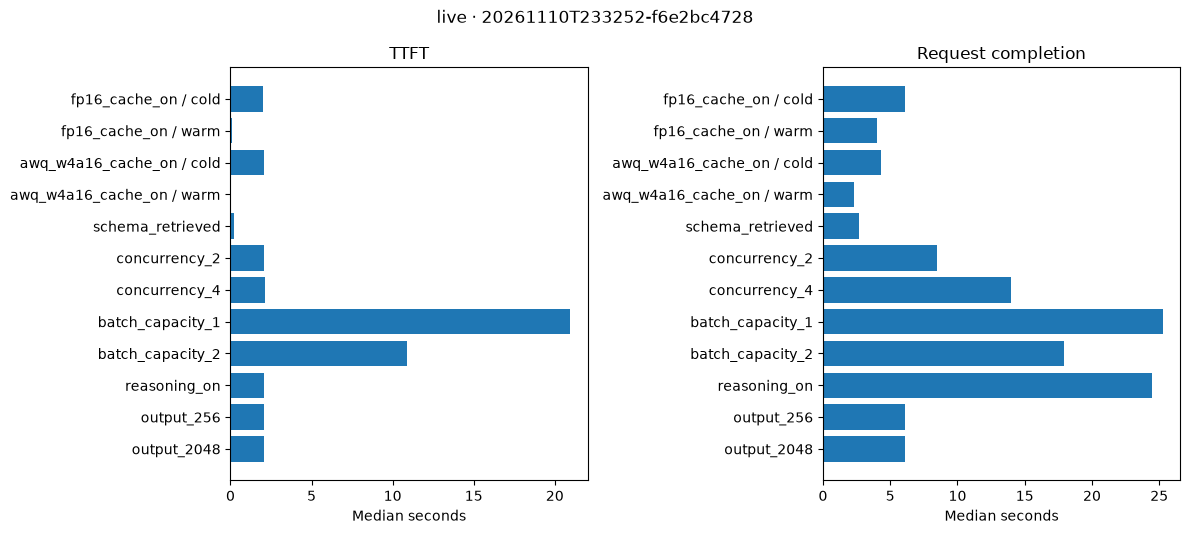

In [20]:
from clinical_trial_mvp.tutorial.session_figures import figure
fig = figure(study)
if fig is not None:
    display(fig)
    import matplotlib.pyplot as plt
    plt.close(fig)
else:
    print('No measured rows available for a figure.')


## 6. Cleanup

Save the notebook to retain genuine Live outputs. Native servers stop after each row. Stop the owned NIM container (if applicable) before switching models or pausing. Cleanup is safe to repeat and does not stop external servers.


In [21]:
print(study.close())


Study servers stopped. Saved records and notebook outputs are retained.
